# **Problem Definition**

## What is the problem?
Aeolus Renewables owns 1,150 wind turbines and sells the electricity they make. A turbine that is stopped makes no electricity, so it earns no money. The longest and most expensive stops come from the drivetrain, the part inside the top of the turbine that connects the blades to the generator. We want to spot a drivetrain that is starting to fail before it breaks completely.

## How a turbine works
Think of a wind turbine as a giant bicycle on top of a tall tower. The wind pushes the big blades round slowly, like your legs pushing the pedals. Inside the box at the top is the drivetrain. It takes that slow push and turns it into a fast spin, so the generator can make electricity.

Two kinds of parts do most of the work in there:
- Bearings are smooth rollers that let heavy spinning rods glide easily.
- Gears are toothed wheels that make the spin faster.

## What is a failure?
A failure happens when those smooth, slippery metal parts stop gliding and start to rub, grind or break. Instead of a quiet hum, the machine scrapes, shakes or gets hot until a part sticks or snaps. One often-quoted breakdown says that when a gearbox fails, bearings are the cause about 70% of the time, gears about 26% and other things about 4%. So bearings are the part to watch most.

## What can cause a failure?
Each cause below shows up in our data as a column, so a model can learn to spot it.

1. Heat and friction (`gearbox_oil_temp_C`). Moving metal makes heat, like rubbing your hands together. Special oil keeps the parts cool and slippery. If the oil gets too hot it goes thin and stops protecting the metal.
2. Shaking (`drivetrain_vibration_rms_mmps`). A chipped gear tooth or a rough bearing makes the machine shake more, like a bike wheel that is not straight. The extra shaking wears other parts out faster.
3. Tiny metal crumbs in the oil (`oil_particle_count`). When parts scrape, flakes of metal break off into the oil, like sand in soup. More crumbs means something inside is being chewed up.
4. Age (`operating_hours_total`). Even strong parts wear out after tens of thousands of hours of spinning.
5. Gusty wind and heavy work (`power_output_kW` and `rated_power_kW`). Strong, bumpy wind makes the drivetrain work close to its limit. If a part is already worn, that extra push can turn a small wobble into a big breakdown.

## Why it matters
- The turbine is off for 7 to 21 days. It makes and sells no electricity in that time.
- An emergency crane and rushed parts cost much more than the same repair planned ahead.
- A bad bearing left running can destroy the gearbox it feeds, so a small repair becomes a huge one. The gearbox alone is about 13% of the cost of a whole turbine.
- Today's alarms only go off when the fault is almost final. Analysts also watch a flood of numbers across 1,150 turbines, so early warnings get missed.

## What we are going to build
A model that reads the sensor numbers from a turbine for one 10-minute reading and answers with one of two labels: normal (0) or fault (1). Analysts can then look at the few turbines marked as fault, instead of scanning every turbine.

## How we will judge the model
Missing a real fault costs far more than checking a turbine that was fine. So the main score is recall, which is the share of real faults the model catches. We also keep an eye on precision, which is the share of alerts that are real faults, so the team is not buried in false alarms.

## The data in short
The file `wind_turbine_detection.csv` has 131,760 rows and 35 columns. Each row is one 10-minute reading from one of 15 turbines, between 1 January and 1 March 2024. The column we want to predict is `failure` (0 = normal, 1 = fault).


## **Data Dictionary**

The dataset, `wind_turbine_detection.csv` contains 10-minute SCADA records for 15 turbines.

### Identifiers & Metadata

| Column | Data Type | Description |
| --- | --- | --- |
| timestamp | datetime | Date and time of the 10-minute logging interval; establishes chronological sequence. |
| turbine_id | object (categorical) | Unique code identifying individual wind turbines; used to track specific asset history. |

### Environmental Conditions

| Column | Data Type | Description |
| --- | --- | --- |
| rated_power_kW | float | Maximum engineered power capacity of the turbine; defines its performance baseline. |
| wind_speed_mps | float | Velocity of the incoming wind; the primary driver of kinetic energy input. |
| wind_direction_deg | float | Compass direction of oncoming wind; used to assess turbine alignment. |
| turbulence_intensity | float | Measure of wind speed fluctuation; higher intensity increases structural fatigue. |
| air_density_kgm3 | float | Mass of air per unit volume; directly impacts aerodynamic lift and power potential. |
| ambient_temp_C | float | Outdoor air temperature surrounding the turbine; affects cooling efficiency. |
| humidity_pct | float | Relative moisture level in the air; flags risks for electrical insulation degradation or corrosion. |

### Operational Control & State

| Column | Data Type | Description |
| --- | --- | --- |
| power_output_kW | float | Real-time electricity generated; drops or fluctuations can signal mechanical drag. |
| rotor_speed_rpm | float | Rotational speed of the main blades; reflects low-speed shaft dynamics. |
| generator_speed_rpm | float | Rotational speed of the generator shaft; crucial for detecting gearbox slip. |
| blade_pitch_angle_deg | float | Angle of the blades relative to the wind; adjusted to control power and rotor speed. |
| yaw_misalignment_deg | float | Angle deviation between wind direction and nacelle orientation; high values cause uneven drivetrain stress. |

### Thermal Metrics (Component Health)

| Column | Data Type | Description |
| --- | --- | --- |
| gearbox_oil_temp_C | float | Temperature of the lubricating oil; spikes indicate excessive mechanical friction. |
| gearbox_bearing_temp_C | float | Internal temperature of gearbox bearings; a leading indicator of bearing wear. |
| generator_bearing_temp_C | float | Temperature of generator bearings; flags alignment or lubrication issues. |
| generator_winding_temp_C | float | Temperature of internal electrical coils; spikes indicate electrical overload or cooling failure. |
| main_bearing_temp_C | float | Temperature of the primary low-speed shaft bearing; handles massive structural loads. |
| nacelle_temp_C | float | Air temperature inside the enclosed housing; reflects global internal heat dissipation. |

### Vibration & Diagnostics (FFT)

| Column | Data Type | Description |
| --- | --- | --- |
| drivetrain_vibration_rms_mmps | float | Overall energy of drivetrain vibrations; general indicator of mechanical roughness. |
| tower_vibration_mmps | float | Structural oscillation of the turbine tower; flags aerodynamic or rotor imbalance. |
| vib_fft_bearing_bpfo | float | Vibration amplitude at the bearing outer-race defect frequency; tracks outer-ring pitting. |
| vib_fft_bearing_bpfi | float | Vibration amplitude at the bearing inner-race defect frequency; tracks inner-ring pitting. |
| vib_fft_gearmesh | float | Vibration amplitude at the teeth-meshing frequency; isolates gearbox tooth wear or misalignment. |
| vib_fft_sideband | float | Vibration amplitude surrounding main frequencies; flags localized faults like cracked gear teeth. |

### Lubrication & Particle Analysis

| Column | Data Type | Description |
| --- | --- | --- |
| oil_particle_count | float | Quantity of metallic debris suspended in lubricating oil; direct indicator of component wear. |
| oil_pressure_bar | float | Pressure of the lubrication system; drops indicate leaks, pump failures, or oil thinning. |

### Asset Lifecycle & History

| Column | Data Type | Description |
| --- | --- | --- |
| operating_hours_total | float | Cumulative runtime of the turbine; represents the asset's total mechanical mileage. |
| cumulative_energy_MWh | float | Total historical electricity produced; measures the lifetime work done by the drivetrain. |
| load_cycles | int | Total count of fatigue-inducing stress variations; correlates directly with structural aging. |
| hours_since_last_maintenance | float | Time elapsed since last service; crucial for identifying maintenance-cycle fatigue. |
| prior_fault_count | int | Total historical fault events triggered; highlights chronic or poorly repaired issues. |
| component_age_days | float | Elapsed lifetime of active components; captures chronological wear independent of runtime. |

### Targets (Labels)

| Column | Data Type | Description |
| --- | --- | --- |
| failure | int (0/1) | The target variable; boolean flag indicating if the drivetrain or turbine is healthy (0) or failing (1). |

# **Installing and Importing the Necessary Libraries**

In [1]:
!pip install pandas==2.2.2 numpy==2.0.2 scikit-learn==1.6.1 tensorflow==2.20.0 keras==3.13.2 xgboost==3.2.0 seaborn==0.13.2 matplotlib==3.10.0 -q

ERROR: Ignored the following versions that require a different python version: 1.7.0 Requires-Python >=3.10; 1.7.0rc1 Requires-Python >=3.10; 1.7.1 Requires-Python >=3.10; 1.7.2 Requires-Python >=3.10; 1.8.0 Requires-Python >=3.11; 1.8.0rc1 Requires-Python >=3.11; 1.9.0 Requires-Python >=3.11; 1.9.0rc1 Requires-Python >=3.11; 1.9.1 Requires-Python >=3.11; 2.1.0 Requires-Python >=3.10; 2.1.1 Requires-Python >=3.10; 2.1.2 Requires-Python >=3.10; 2.1.3 Requires-Python >=3.10; 2.2.0 Requires-Python >=3.10; 2.2.1 Requires-Python >=3.10; 2.2.2 Requires-Python >=3.10; 2.2.3 Requires-Python >=3.10; 2.2.4 Requires-Python >=3.10; 2.2.5 Requires-Python >=3.10; 2.2.6 Requires-Python >=3.10; 2.3.0 Requires-Python >=3.11; 2.3.1 Requires-Python >=3.11; 2.3.2 Requires-Python >=3.11; 2.3.3 Requires-Python >=3.11; 2.3.4 Requires-Python >=3.11; 2.3.5 Requires-Python >=3.11; 2.4.0 Requires-Python >=3.11; 2.4.0rc1 Requires-Python >=3.11; 2.4.1 Requires-Python >=3.11; 2.4.2 Requires-Python >=3.11; 2.4.3 Req

**Note**:
- After running the above cell, kindly restart the notebook kernel (for VS Code) or runtime (for Google Colab), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

In [2]:
# Standard libraries for tracking execution time and vector/matrix operations
import time
import numpy as np

# Data manipulation and visualization libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Tree-based and ensemble machine learning classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Utilities for handling class imbalance, model evaluation, and metric calculations
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

# Deep learning framework and specific layers for building Artificial Neural Networks (ANNs)
import tensorflow as tf
from keras.models import Sequential  # Model for building NN sequentially.
from keras.layers import Dense, Dropout, BatchNormalization

# Preprocessing tools for scaling data and tools for model optimization/explainability
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV  # To tune different models
from sklearn.inspection import permutation_importance

# Configuration settings to suppress warnings and format data display outputs
import warnings
warnings.filterwarnings('ignore')              # Suppress warnings for cleaner output logs
sns.set_style('whitegrid')                     # Set a consistent clean grid style for plots
pd.set_option('display.max_columns', None)     # Prevent truncation of columns when displaying dataframes

# **Loading the Data**

In [3]:
# uncomment and run the below code snippets if you're using Google Colab and the dataset is present in the Google Drive
# from google.colab import drive
# drive.mount('/content/drive')

In [4]:
data = pd.read_csv('wind_turbine_detection.csv')

# **Data Overview**
Before drawing any charts, we take a first look at the table itself: what the rows and columns look like, how big it is, what type each column is, and whether any rows are repeated. (Missing values are checked in detail in the Data Preprocessing section.)

## Viewing the first and last 5 rows of the dataset
This shows a few real rows, so we can see what one reading looks like.

In [5]:
data.head()

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
0,1/1/2024 0:00,T001,1500,2.335,151.993,0.149,1.205,21.820,68.717,0.000,0.000,14.414,87.761,-5.455,53.728,56.728,57.637,61.546,48.728,29.820,1.518,0.974,0.455,0.391,0.455,0.399,55.756,6.032,19319.612,9587.146,0.000,769.284,0,1360.703,0
1,1/1/2024 0:10,T001,1500,9.166,152.957,0.153,1.200,22.893,74.002,486.762,12.554,1134.433,-0.159,0.489,64.105,67.798,66.841,85.072,58.544,33.649,1.480,0.992,0.455,0.391,0.455,0.399,55.756,5.776,19319.778,9587.227,1.528,769.450,0,1360.710,0
2,1/1/2024 0:20,T001,1500,9.034,158.402,0.201,1.219,22.899,59.616,454.109,12.579,1143.435,1.061,4.220,63.868,66.635,66.093,82.383,58.365,32.667,1.753,1.074,0.455,0.391,0.455,0.399,55.756,5.994,19319.945,9587.302,3.539,769.617,0,1360.717,0
3,1/1/2024 0:30,T001,1500,13.284,159.023,0.159,1.181,22.727,64.676,1446.811,16.941,1526.358,5.718,1.584,83.654,89.761,85.749,128.484,77.257,36.349,1.924,1.379,0.455,0.391,0.455,0.399,55.756,5.541,19320.112,9587.544,5.126,769.784,0,1360.724,0
4,1/1/2024 0:40,T001,1500,2.239,159.842,0.189,1.173,23.742,65.423,0.000,0.194,27.405,88.452,3.400,54.573,57.150,56.817,60.963,51.506,32.234,1.497,0.936,0.455,0.391,0.455,0.399,55.756,6.018,19320.112,9587.544,5.126,769.950,0,1360.731,0


In [6]:
data.tail()

,timestamp,turbine_id,rated_power_kW,wind_speed_mps,wind_direction_deg,turbulence_intensity,air_density_kgm3,ambient_temp_C,humidity_pct,power_output_kW,rotor_speed_rpm,generator_speed_rpm,blade_pitch_angle_deg,yaw_misalignment_deg,gearbox_oil_temp_C,gearbox_bearing_temp_C,generator_bearing_temp_C,generator_winding_temp_C,main_bearing_temp_C,nacelle_temp_C,drivetrain_vibration_rms_mmps,tower_vibration_mmps,vib_fft_bearing_bpfo,vib_fft_bearing_bpfi,vib_fft_gearmesh,vib_fft_sideband,oil_particle_count,oil_pressure_bar,operating_hours_total,cumulative_energy_MWh,load_cycles,hours_since_last_maintenance,prior_fault_count,component_age_days,failure
131755,3/1/2024 23:10,T015,3000,5.680,108.327,0.306,1.200,19.599,60.093,95.437,8.399,764.196,-0.123,-6.325,53.286,60.399,56.996,63.265,50.056,27.808,2.139,0.886,0.322,0.333,0.424,0.224,78.731,5.741,36147.152,33527.459,13588.408,2588.506,63,784.507,0
131756,3/1/2024 23:20,T015,3000,6.945,111.198,0.151,1.207,18.800,63.952,254.325,9.789,886.754,0.507,1.873,54.811,62.961,60.368,67.812,50.091,27.891,1.470,0.956,0.322,0.333,0.424,0.224,78.731,6.125,36147.318,33527.501,13589.919,2588.673,63,784.514,0
131757,3/1/2024 23:30,T015,3000,2.191,113.020,0.148,1.214,18.331,61.764,0.000,0.029,3.975,87.072,0.880,51.704,60.440,57.181,63.706,47.760,26.242,1.793,0.897,0.322,0.333,0.424,0.224,78.731,5.955,36147.318,33527.501,13589.919,2588.839,63,784.521,0
131758,3/1/2024 23:40,T015,3000,11.003,117.356,0.178,1.200,19.640,62.729,2056.378,14.527,1297.923,0.869,4.662,72.463,84.704,78.389,111.169,66.612,31.989,1.764,1.212,0.322,0.333,0.424,0.224,78.731,5.920,36147.485,33527.844,13591.700,2589.006,63,784.528,0
131759,3/1/2024 23:50,T015,3000,2.231,116.146,0.160,1.206,19.598,66.575,0.000,0.040,0.936,88.206,0.105,51.646,60.774,57.721,63.360,46.512,28.247,1.833,1.239,0.322,0.333,0.424,0.224,78.731,5.886,36147.485,33527.844,13591.700,2589.173,63,784.535,0


**Used for:** Getting to know what one reading looks like.

**What it shows:** Each row is one 10-minute reading from one turbine. The table starts with turbine T001 at 00:00 on 1 January 2024 and ends with turbine T015 at 23:50 on 1 March 2024, so the rows are sorted by turbine and then by time.

**Hence:** Every row is one snapshot of one turbine, and `failure` (0 or 1) is the column we want to predict.

## Checking the shape of the dataset
The shape is the number of rows and columns.

In [7]:
data.shape

(131760, 35)

**Used for:** Knowing how big the data is.

**What it shows:** There are 131,760 rows and 35 columns: 15 turbines x 61 days x 144 readings a day.

**Hence:** The data is large enough to train and test models properly.

## Checking the attribute types
This lists every column, its type (number or text) and how many cells are filled in.

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131760 entries, 0 to 131759
Data columns (total 35 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   timestamp                      131760 non-null  object 
 1   turbine_id                     131760 non-null  object 
 2   rated_power_kW                 131760 non-null  int64  
 3   wind_speed_mps                 131760 non-null  float64
 4   wind_direction_deg             131760 non-null  float64
 5   turbulence_intensity           131760 non-null  float64
 6   air_density_kgm3               131760 non-null  float64
 7   ambient_temp_C                 131760 non-null  float64
 8   humidity_pct                   131760 non-null  float64
 9   power_output_kW                131760 non-null  float64
 10  rotor_speed_rpm                131760 non-null  float64
 11  generator_speed_rpm            131760 non-null  float64
 12  blade_pitch_angle_deg         

**Used for:** Checking which columns are numbers and which are text.

**What it shows:** 33 columns are numbers (30 decimals and 3 whole numbers). Two are text: `timestamp` (date and time stored as text) and `turbine_id`. Three columns have fewer filled cells than the rest: gearbox oil temperature, generator bearing temperature and oil pressure.

**Hence:** The date has to be turned into a real date later, and the three columns with gaps need fixing in Data Preprocessing.

## Checking the statistical summary
For every number column this shows the count, average, spread, smallest and largest value.

In [9]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
rated_power_kW,131760.0,2166.666667,743.567808,1500.000,1500.00000,2000.0000,3000.00000,3600.000
wind_speed_mps,131760.0,7.649297,4.066898,0.015,4.62700,7.1365,10.08800,32.000
wind_direction_deg,131760.0,163.155270,106.644769,0.000,68.28875,150.5440,254.89200,359.995
turbulence_intensity,131760.0,0.175353,0.033725,0.121,0.15100,0.1680,0.19100,0.450
air_density_kgm3,131760.0,1.244980,0.037329,1.140,1.21400,1.2450,1.27600,1.345
ambient_temp_C,131760.0,10.011035,8.999438,-9.748,2.17800,9.9770,17.85900,29.078
humidity_pct,131760.0,60.023310,13.067340,18.908,50.03800,59.9980,70.00800,99.693
power_output_kW,131760.0,633.607766,869.596264,0.000,17.35800,198.5185,1014.10925,3672.000
rotor_speed_rpm,131760.0,9.981842,4.856042,0.000,7.30700,10.1970,13.59600,17.628
generator_speed_rpm,131760.0,898.629973,436.640301,0.000,657.56950,917.7410,1223.73300,1590.833


**Used for:** Spotting unusual values and checking that the numbers make sense.

**What it shows:** Wind speed runs from 0 to 32 m/s and power from 0 to 3,672 kW. Vibration, oil particle count and past fault count have averages well above their middle values, so a few very high readings pull them up. The only negative values are in angles (blade pitch, yaw misalignment) and in outdoor and nacelle temperatures, which can drop below 0 °C in winter. Power sometimes goes up to 2% above the rated power, which is a normal small overshoot.

**Hence:** No impossible values were found, so nothing needs to be removed. The very high readings are kept, because faults hide in them.

## Checking for duplicate values
A duplicate is a row that appears twice. Duplicates would count the same reading twice.

In [10]:
data.duplicated().sum()

np.int64(0)

**Used for:** Making sure no reading is counted twice.

**What it shows:** There are 0 duplicate rows.

**Hence:** Nothing needs to be removed.

# **Exploratory Data Analysis (EDA)**

Before we look at any tables, we look at the data in pictures. We go in three steps:

1. **Univariate**: one column at a time.
2. **Bivariate**: two columns together.
3. **Multivariate**: many columns together.

In every chart, **blue means normal** and **red means fault**. Each chart has a title and labelled axes with units. Under every chart there are three short lines: **Used for** (what the chart helps us find out), **What it shows** (what we see in it) and **Hence** (what it means for the project).

**How to read the charts**
- **Pie chart**: each slice is a share of the whole.
- **Histogram**: each bar counts how many readings fall in a range of values. A tall bar means many readings there.
- **Box plot**: the box holds the middle half of the readings. The line inside the box is the median (the middle reading). The lines on each side (whiskers) show the usual range. Dots beyond the whiskers are unusual readings.
- **Scatter plot**: each dot is one 10-minute reading, placed by its value on two columns.
- **Heatmap**: each square shows how strongly two columns move together, from -1 to +1. Red means they rise together, blue means one rises as the other falls.

### Chart settings
This cell sets the colours and the text sizes once, so every chart looks the same and is easy to read. It also builds two small helper functions that draw a labelled histogram and a labelled box plot, so we do not repeat the same code for every column.

In [11]:
# Same look for every chart: big readable titles and labels
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 14, 'axes.titleweight': 'bold',
                     'axes.labelsize': 12, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
                     'legend.fontsize': 11})

NORMAL_COLOR = '#1F77B4'   # blue  = normal
FAULT_COLOR = '#D62728'    # red   = fault
LABELS = {0: 'Normal (0)', 1: 'Fault (1)'}
PALETTE = {0: NORMAL_COLOR, 1: FAULT_COLOR}


def fmt(x):
    """2 decimals for small numbers, 1 decimal for big ones."""
    return f'{x:,.2f}' if abs(x) < 10 else f'{x:,.1f}'


def labelled_hist(col, title, xlabel):
    """Histogram with mean and median lines, a title, axis labels and a legend."""
    plt.figure(figsize=(9, 4.5))
    sns.histplot(data[col], bins=50, kde=True, color=NORMAL_COLOR)
    plt.axvline(data[col].mean(), color='black', linestyle='--', linewidth=2,
                label=f'Mean = {fmt(data[col].mean())}')
    plt.axvline(data[col].median(), color='#2CA02C', linestyle='-', linewidth=2,
                label=f'Median = {fmt(data[col].median())}')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel('Number of readings')
    plt.legend()
    plt.tight_layout()
    plt.show()


def labelled_box(col, title, xlabel):
    """Horizontal box plot. Also prints how many readings are above the upper whisker."""
    q1, q3 = data[col].quantile([0.25, 0.75])
    upper_whisker = q3 + 1.5 * (q3 - q1)
    n_above = int((data[col] > upper_whisker).sum())
    plt.figure(figsize=(9, 3.2))
    sns.boxplot(x=data[col], color=NORMAL_COLOR, flierprops={'markersize': 2, 'alpha': 0.4})
    plt.title(title)
    plt.xlabel(xlabel)
    plt.yticks([])
    plt.tight_layout()
    plt.show()
    print(f'Median: {fmt(data[col].median())} | Middle half of readings: {fmt(q1)} to {fmt(q3)} | '
          f'Readings above the upper whisker ({fmt(upper_whisker)}): {n_above:,} ({n_above / len(data):.1%})')

## Univariate Analysis
Here we look at one column at a time to see how its values are spread: where most readings sit, whether the shape is balanced or lopsided, and whether there are unusual values.

### Pie charts

**Pie chart 1: normal readings vs fault readings.** This shows how rare faults are. It matters because it decides how we judge the model later.

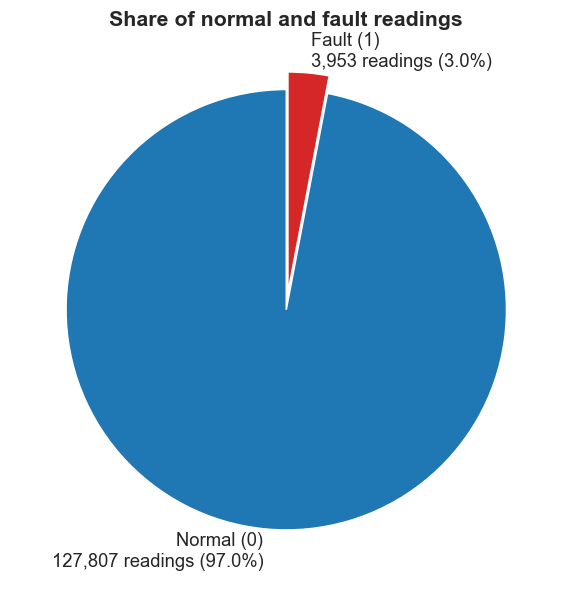

In [12]:
fail_counts = data['failure'].value_counts().sort_index()

plt.figure(figsize=(6.5, 6.5))
plt.pie(fail_counts,
        labels=[f'{LABELS[i]}\n{v:,} readings ({v / fail_counts.sum():.1%})' for i, v in fail_counts.items()],
        startangle=90, explode=(0, 0.08),
        colors=[NORMAL_COLOR, FAULT_COLOR],
        textprops={'fontsize': 12}, wedgeprops={'edgecolor': 'white'})
plt.title('Share of normal and fault readings')
plt.show()

**Used for:** Seeing how many readings are faults and how many are normal.

**What it shows:** Only **3.0%** of readings (3,953 out of 131,760) are faults. The other 97.0% are normal.

**Hence:** Faults are rare. A model that always says "normal" would be right 97% of the time and still be useless, so we judge the model on **recall** (how many real faults it catches), not on accuracy.

**Pie chart 2: the turbine sizes in the data.** Each turbine has a rated power, which is the most it can produce. This chart shows how many of the 15 turbines have each rating.

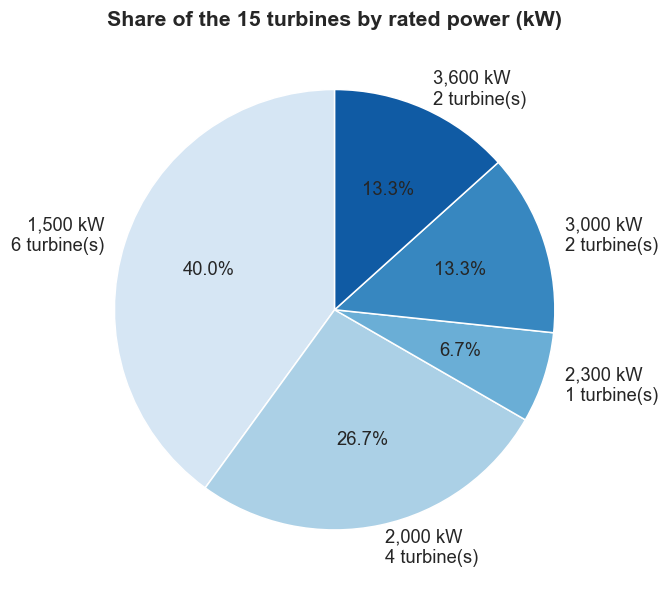

In [13]:
size_counts = data.groupby('rated_power_kW')['turbine_id'].nunique()

plt.figure(figsize=(6.5, 6.5))
plt.pie(size_counts,
        labels=[f'{kw:,} kW\n{n} turbine(s)' for kw, n in size_counts.items()],
        autopct='%1.1f%%', startangle=90,
        colors=sns.color_palette('Blues', len(size_counts)),
        textprops={'fontsize': 12}, wedgeprops={'edgecolor': 'white'})
plt.title('Share of the 15 turbines by rated power (kW)')
plt.show()

**Used for:** Checking whether all 15 turbines are the same size.

**What it shows:** They are not. Six are 1,500 kW, four are 2,000 kW, two are 3,000 kW, two are 3,600 kW and one is 2,300 kW. The bigger the turbine, the more power it can make.

**Hence:** The data mixes several turbine models, so we cannot compare power output between turbines without keeping their size in mind.

### Histograms
Each histogram below shows how the readings of one column are spread. The dashed black line is the mean (the average) and the green line is the median (the middle reading). When the two lines are far apart, the data is lopsided.

**Histogram: wind speed.** Wind drives everything in a turbine, so we start here.

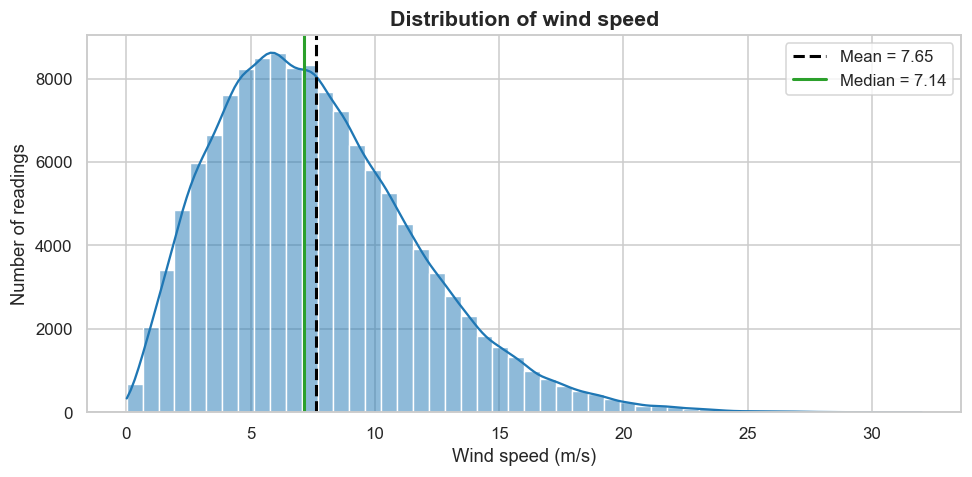

In [14]:
labelled_hist('wind_speed_mps', 'Distribution of wind speed', 'Wind speed (m/s)')

**Used for:** Seeing what wind the turbines usually work in.

**What it shows:** Most readings are between 4.6 and 10.1 m/s (median 7.1). The stronger the wind, the fewer the readings: only a few storm readings reach 32 m/s. About 11% of readings are below 3 m/s, when the turbine barely turns.

**Hence:** The turbines work in light to medium wind most of the time. Storms are rare.

**Histogram: power output.** This shows how much electricity the turbines make in a 10-minute reading.

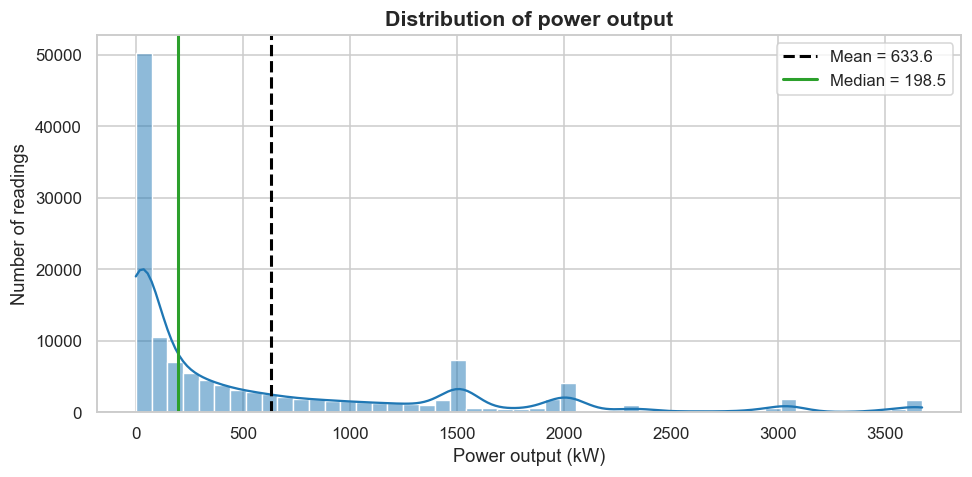

In [15]:
labelled_hist('power_output_kW', 'Distribution of power output', 'Power output (kW)')

**Used for:** Seeing how much electricity the turbines make in a 10-minute reading.

**What it shows:** The higher the power, the fewer the readings. 18% of readings are exactly 0 kW (low wind, or the turbine is stopped). The median is about 199 kW but the mean is 634 kW, because a smaller group runs at high output, up to 3,672 kW. The small spikes at 1,500, 2,000, 3,000 and 3,600 kW are turbines running at their maximum.

**Hence:** Turbines spend most of their time well below full power.

**Histogram: gearbox oil temperature.** The oil cools and protects the gears, so its temperature is a health sign.

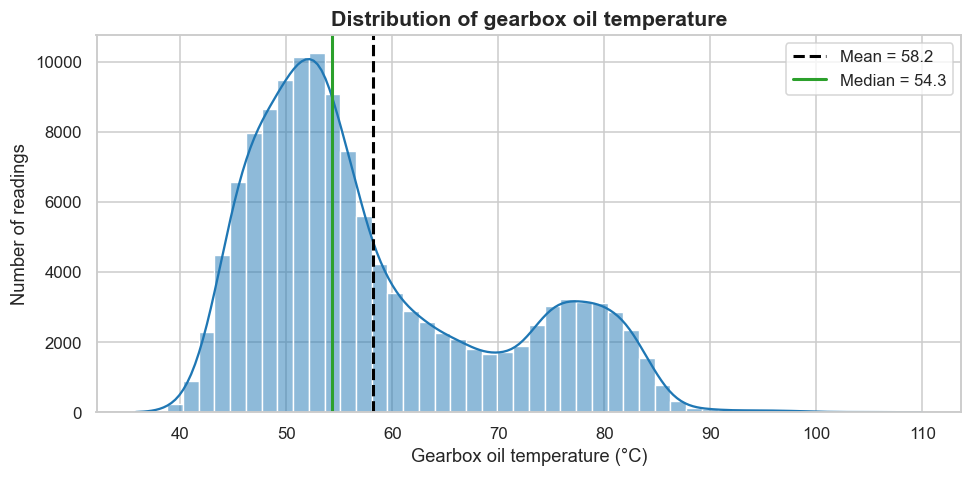

In [16]:
labelled_hist('gearbox_oil_temp_C', 'Distribution of gearbox oil temperature', 'Gearbox oil temperature (°C)')

**Used for:** Seeing how hot the gearbox oil usually runs, which shows how hard the gearbox is working.

**What it shows:** Most readings are around 50 °C, and the hotter it gets, the fewer the readings, until a second, smaller hump appears around 75 to 80 °C. That hot hump is turbines working hard: when the oil is above 70 °C (20% of readings), the median power is 1,918 kW, against 86 kW otherwise.

**Hence:** Oil temperature mostly follows the workload, so on its own it is a weak sign of a fault.

**Histogram: drivetrain vibration.** Shaking is one of the main warning signs of a rough bearing or a chipped gear.

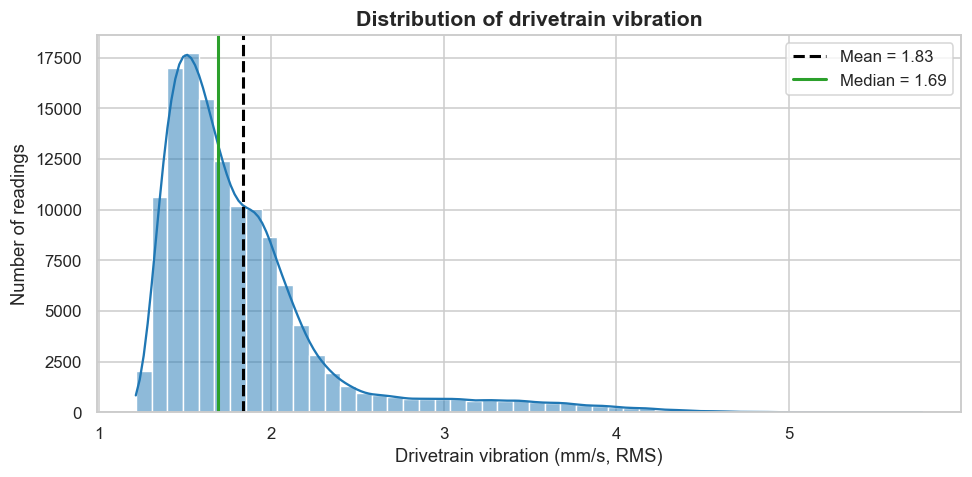

In [17]:
labelled_hist('drivetrain_vibration_rms_mmps', 'Distribution of drivetrain vibration', 'Drivetrain vibration (mm/s, RMS)')

**Used for:** Seeing how much the drivetrain normally shakes.

**What it shows:** Most readings are between 1.5 and 2.0 mm/s (median 1.69). The more the shaking, the fewer the readings, but there is a small second bump between 3 and 4.5 mm/s, and the tail reaches 5.8 mm/s.

**Hence:** A small group of readings shakes far more than normal. The bivariate section shows that this group is the faults.

**Histogram: oil particle count.** This counts the tiny metal flakes in the oil. More flakes means parts are wearing.

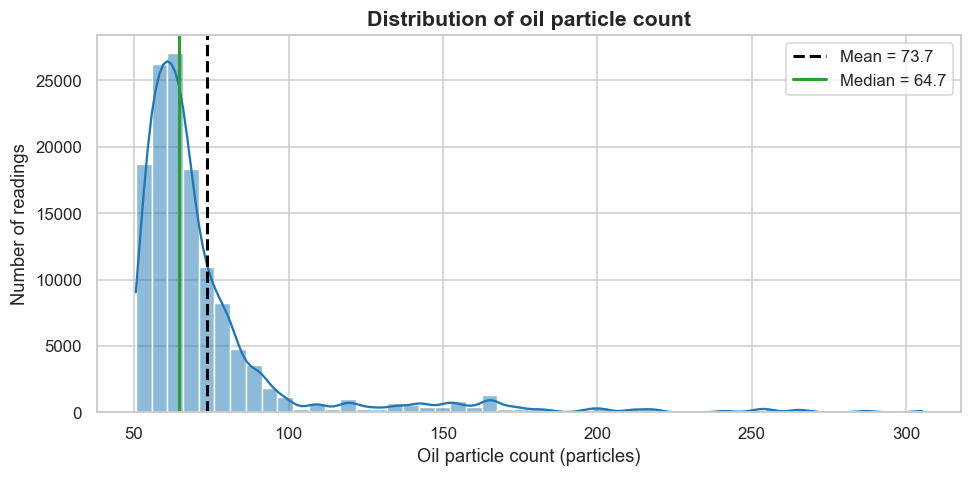

In [18]:
labelled_hist('oil_particle_count', 'Distribution of oil particle count', 'Oil particle count (particles)')

**Used for:** Seeing how much metal wear is in the oil.

**What it shows:** Most readings are low, between 59 and 75 particles (median 65). The more particles, the fewer the readings. A small group goes up to 305, with a little bump around 150. This is the most lopsided column in the data.

**Hence:** The oil is clean most of the time, so a high particle count is rare and worth watching.

**Histogram: component age.** Older parts are more worn, so age could matter.

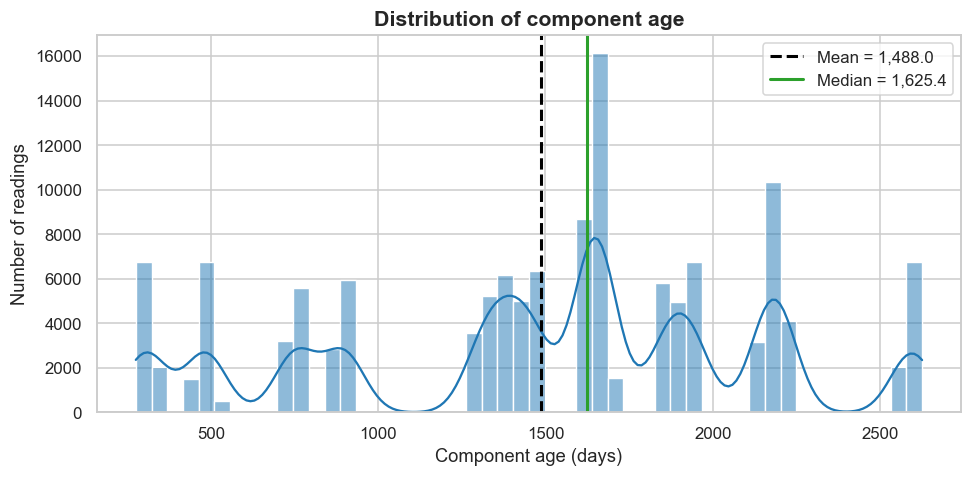

In [19]:
labelled_hist('component_age_days', 'Distribution of component age', 'Component age (days)')

**Used for:** Seeing how old the monitored parts are.

**What it shows:** Ages run from 276 to 2,625 days (under 1 year to over 7 years), with a median of about 1,625 days. The bars are lumpy because each turbine has one age that barely changes over two months.

**Hence:** This chart shows the 15 turbines more than it shows a smooth spread, so component age tells us about differences between turbines, not between readings.

### Box plots
A box plot is the fastest way to see unusual readings. The dots to the right of the box are readings far above the usual range. We draw one for the three columns that matter most for faults and for oil and heat.

**Box plot: drivetrain vibration.**

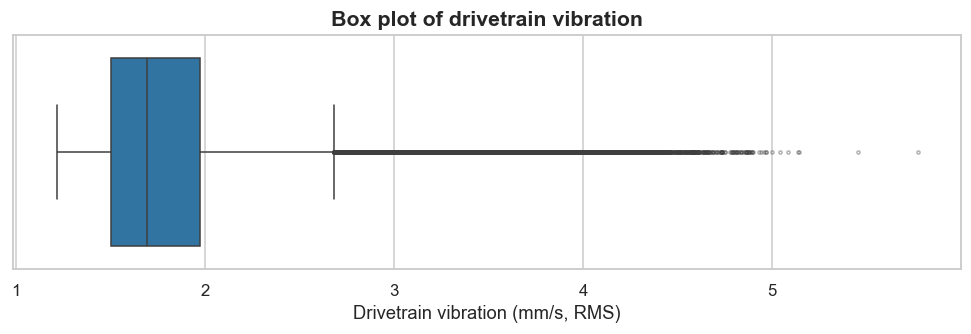

Median: 1.69 | Middle half of readings: 1.51 to 1.98 | Readings above the upper whisker (2.68): 8,981 (6.8%)


In [20]:
labelled_box('drivetrain_vibration_rms_mmps', 'Box plot of drivetrain vibration', 'Drivetrain vibration (mm/s, RMS)')

**Used for:** Spotting unusually high vibration readings.

**What it shows:** The box is narrow, so most readings are close together (1.51 to 1.98 mm/s). The dots on the right are 8,981 readings (6.8%) that are unusually high.

**Hence:** A small group shakes much more than the rest. Faulty readings are expected to be among them.

**Box plot: oil particle count.**

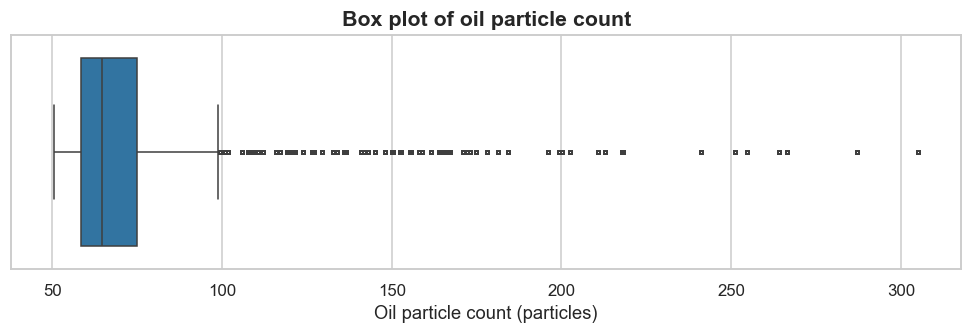

Median: 64.7 | Middle half of readings: 58.6 to 74.9 | Readings above the upper whisker (99.5): 11,232 (8.5%)


In [21]:
labelled_box('oil_particle_count', 'Box plot of oil particle count', 'Oil particle count (particles)')

**Used for:** Spotting unusually high oil particle counts.

**What it shows:** The box is tight near 65 particles, and 8.5% of readings (11,232) are above the upper whisker. That is more than for the other two columns.

**Hence:** Oil particle count has the most unusual readings of the three, so it is a good place to look for faults.

**Box plot: gearbox oil temperature.**

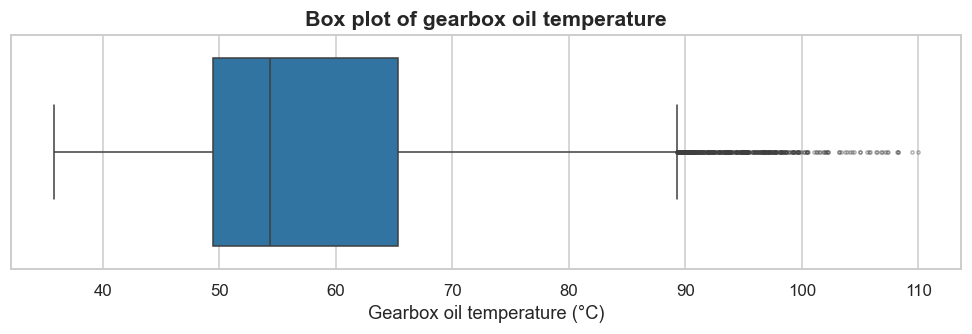

Median: 54.3 | Middle half of readings: 49.4 to 65.4 | Readings above the upper whisker (89.3): 429 (0.3%)


In [22]:
labelled_box('gearbox_oil_temp_C', 'Box plot of gearbox oil temperature', 'Gearbox oil temperature (°C)')

**Used for:** Spotting unusually hot gearbox oil.

**What it shows:** Only 0.3% of readings (429) are above the upper whisker. The hotter the oil gets above about 89 °C, the rarer the readings.

**Hence:** Temperature has far fewer extreme readings than vibration or oil particles, so it is less likely to flag faults by itself.

## Bivariate Analysis
Now we compare two columns at a time. The main question is: **how does each column change between normal readings and fault readings?** We use box plots and histograms for that, then scatter plots to see two measurements together.

### Box plots: normal vs fault
Each plot has two boxes, blue for normal and red for fault. The median is written under each label. The further apart the boxes are, the better that column separates faults from normal readings.

### Bar chart: fault rate of each turbine
This chart compares the 15 turbines: what share of each turbine's readings are faults. The dashed line is the average for all turbines. Red bars are turbines above 5%.

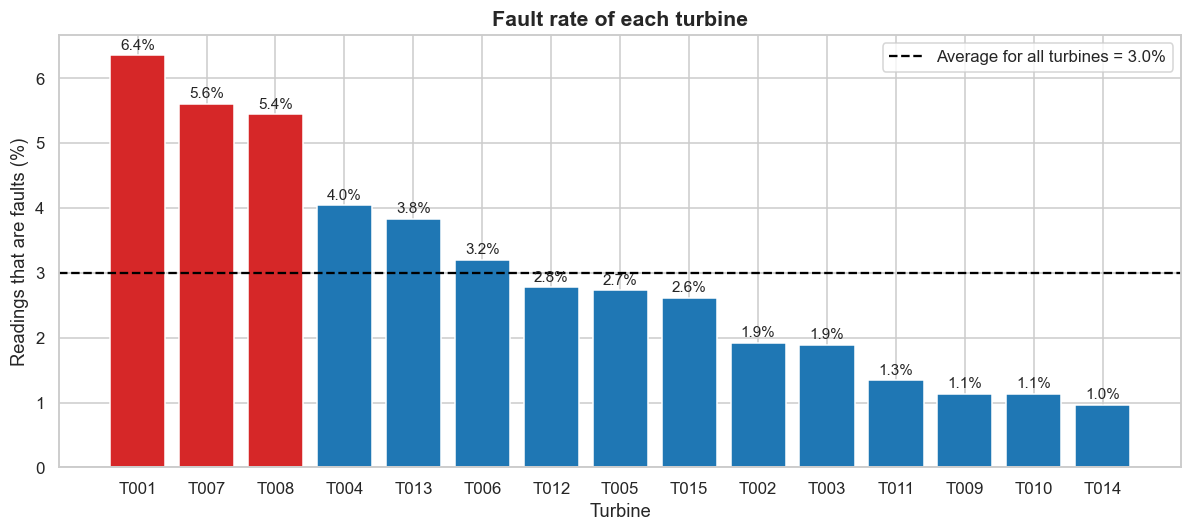

In [23]:
turbine_rate = data.groupby('turbine_id')['failure'].mean().mul(100).sort_values(ascending=False)

plt.figure(figsize=(11, 5))
bars = plt.bar(turbine_rate.index, turbine_rate.values,
               color=['#D62728' if v > 5 else '#1F77B4' for v in turbine_rate.values])
plt.bar_label(bars, fmt='%.1f%%', padding=2, fontsize=10)
plt.axhline(data['failure'].mean() * 100, color='black', linestyle='--',
            label=f"Average for all turbines = {data['failure'].mean() * 100:.1f}%")
plt.title('Fault rate of each turbine')
plt.xlabel('Turbine')
plt.ylabel('Readings that are faults (%)')
plt.legend()
plt.tight_layout()
plt.show()

**Used for:** Finding out whether some turbines fault more often than others.

**What it shows:** Yes. T001 (6.4%), T007 (5.6%) and T008 (5.4%) fault the most, about twice the average of 3.0%. T014, T009 and T010 fault the least (about 1%).

**Hence:** Faults are concentrated in a few machines. These three turbines should be inspected first. We still leave `turbine_id` out of the models, so the model can work on turbines it has never seen.

This cell builds one helper that draws the "normal vs fault" box plot with labels, so we can reuse it for each column.

In [24]:
def box_by_failure(col, title, ylabel):
    """Box plot of one column for normal vs fault readings, with the median under each label."""
    medians = data.groupby('failure')[col].median()
    plt.figure(figsize=(7, 5))
    ax = sns.boxplot(data=data, x='failure', y=col, hue='failure', palette=PALETTE, legend=False,
                     flierprops={'markersize': 2, 'alpha': 0.3})
    ax.set_xticks([0, 1])
    ax.set_xticklabels([f'{LABELS[i]}\nmedian = {fmt(medians[i])}' for i in (0, 1)])
    ax.set_xlabel('Drivetrain condition')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

**Box plot: drivetrain vibration, normal vs fault.**

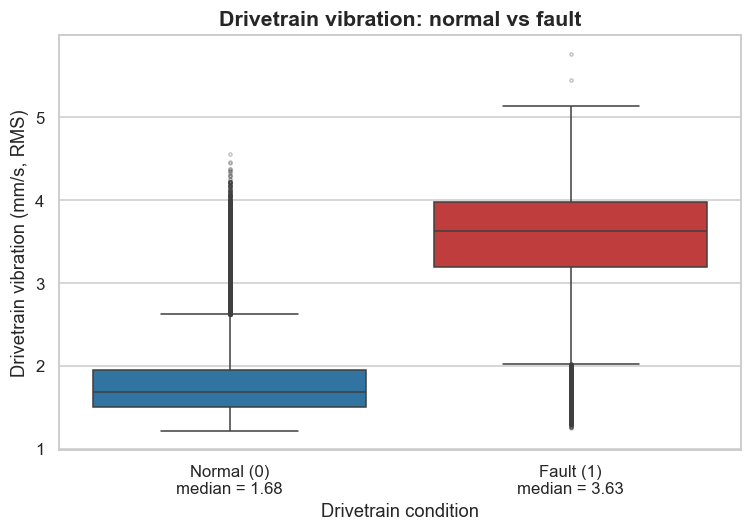

In [25]:
box_by_failure('drivetrain_vibration_rms_mmps', 'Drivetrain vibration: normal vs fault', 'Drivetrain vibration (mm/s, RMS)')

**Used for:** Checking whether faulty readings shake more than normal ones.

**What it shows:** Faults shake much more: the median is **3.63 mm/s** for faults and **1.68 mm/s** for normal readings, and the two boxes do not overlap. 85% of fault readings are above 1.95 mm/s, the top of the normal box. The dots at the bottom of the red box are the 15% of faults that still look normal on vibration.

**Hence:** The more the shaking, the more likely it is a fault. Vibration is the clearest warning sign.

**Box plot: oil particle count, normal vs fault.**

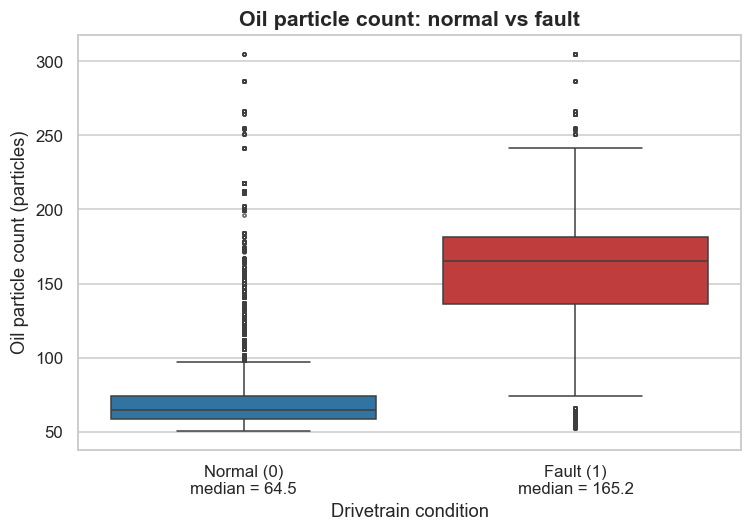

In [26]:
box_by_failure('oil_particle_count', 'Oil particle count: normal vs fault', 'Oil particle count (particles)')

**Used for:** Checking whether faulty readings carry more metal flakes in the oil.

**What it shows:** Fault readings have about 2.6 times more particles: the median is **165** for faults and **64** for normal readings. 75% of fault readings are above 74 particles, the top of the normal box.

**Hence:** The more metal flakes in the oil, the more likely it is a fault.

**Box plot: gearbox bearing temperature, normal vs fault.**

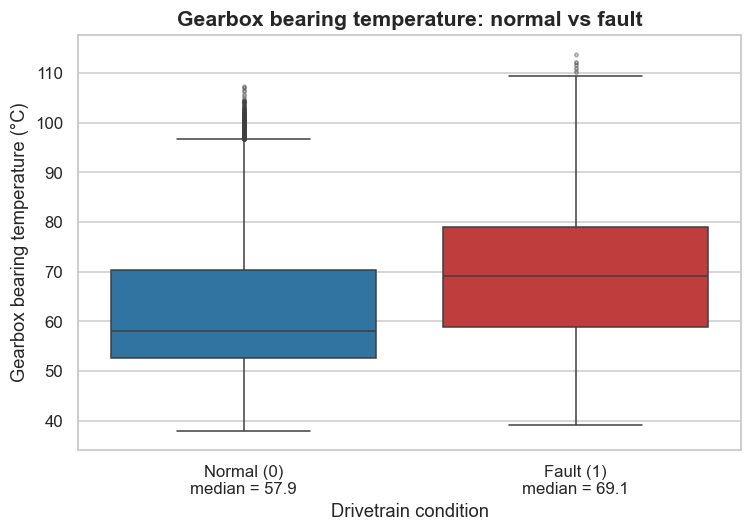

In [27]:
box_by_failure('gearbox_bearing_temp_C', 'Gearbox bearing temperature: normal vs fault', 'Gearbox bearing temperature (°C)')

**Used for:** Checking whether faulty readings run hotter.

**What it shows:** Faults run about 11 °C hotter (median **69 °C** against **58 °C**), but the boxes overlap a lot. Many normal readings are just as hot.

**Hence:** Temperature rises with faults, but not clearly enough. A temperature alarm on its own would either miss faults or go off on healthy machines.

**Box plot: power output, normal vs fault.**

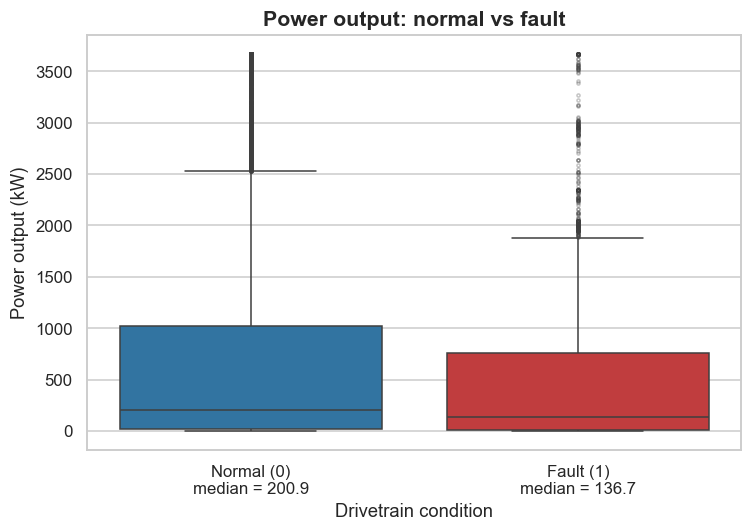

In [28]:
box_by_failure('power_output_kW', 'Power output: normal vs fault', 'Power output (kW)')

**Used for:** Checking whether faulty readings make less power.

**What it shows:** Faulty readings make a little less power (median **137 kW** against **201 kW**), and the boxes overlap almost completely.

**Hence:** Power output cannot tell a fault from a normal reading, so a faulty turbine can look fine on production.

### Histograms: normal vs fault
These histograms put the normal and fault readings on the same chart. We show the share of readings (not the count), because there are far fewer faults, and counts would hide the red bars.

This cell builds a helper that draws the two histograms on top of each other.

In [29]:
def hist_by_failure(col, title, xlabel):
    """Overlapping histograms of one column for normal and fault readings (as shares)."""
    bins = np.linspace(data[col].min(), data[col].max(), 60)
    plt.figure(figsize=(9, 4.5))
    for f in (0, 1):
        sns.histplot(data.loc[data['failure'] == f, col], bins=bins, stat='density', element='step',
                     alpha=0.45, color=PALETTE[f], label=LABELS[f])
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel('Share of readings (density)')
    plt.legend(title='Condition')
    plt.tight_layout()
    plt.show()

**Histogram: drivetrain vibration, normal vs fault.**

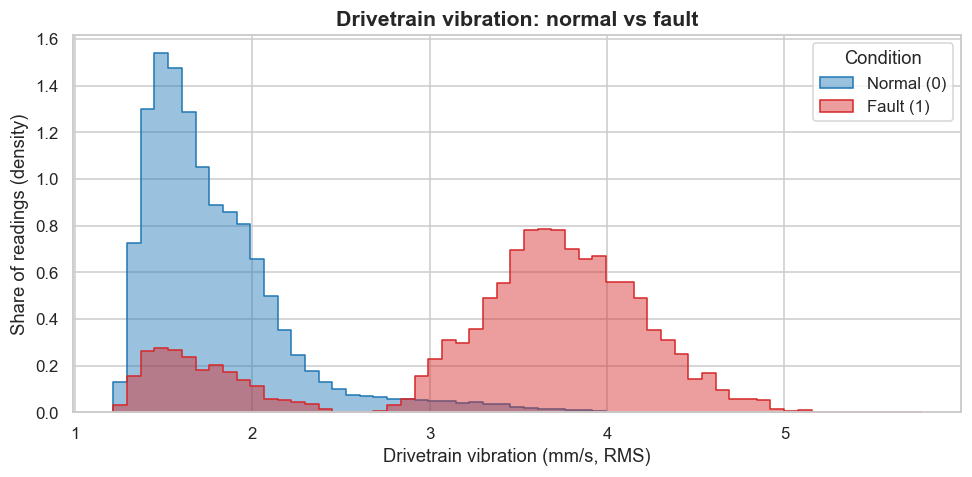

In [30]:
hist_by_failure('drivetrain_vibration_rms_mmps', 'Drivetrain vibration: normal vs fault', 'Drivetrain vibration (mm/s, RMS)')

**Used for:** Seeing the full shape of vibration for normal and fault readings, not just the middle.

**What it shows:** Normal readings pile up between 1.2 and 2.5 mm/s. Fault readings form a separate hump around 3 to 4.5 mm/s. The more the shaking, the more red and the less blue. The small red bump inside the blue one is the 15% of faults that look normal on vibration.

**Hence:** The two humps overlap only a little, which is why vibration separates faults so well.

**Histogram: oil particle count, normal vs fault.**

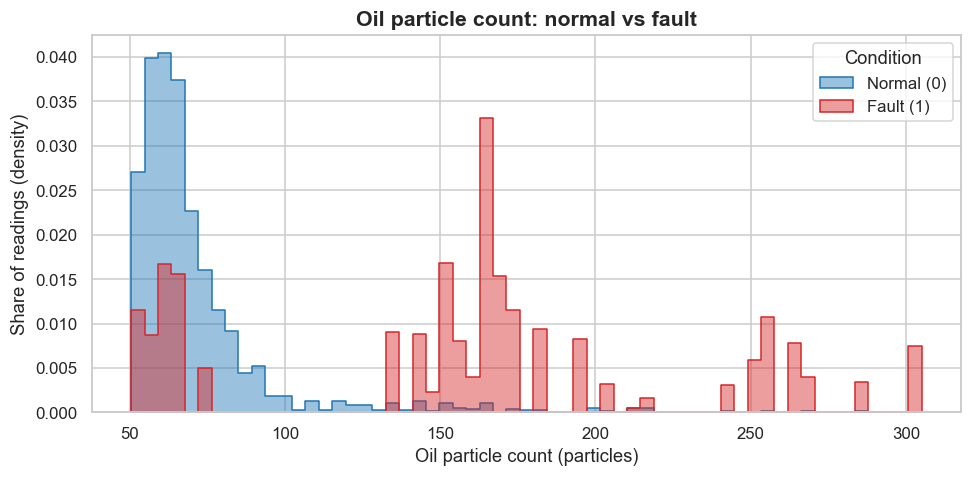

In [31]:
hist_by_failure('oil_particle_count', 'Oil particle count: normal vs fault', 'Oil particle count (particles)')

**Used for:** Seeing the full shape of the oil particle count for normal and fault readings.

**What it shows:** Normal readings sit mostly below 80 particles. Fault readings are spread from about 130 up to 305. The more particles, the more red and the less blue. The red bars are spiky because the oil count is only updated every so often, so it moves in steps.

**Hence:** About 25% of fault readings are below 80 particles, inside the normal range, so oil alone also misses some faults.

### Scatter plots
Each dot is one reading. A scatter plot with 131,760 dots would be one solid blob, so we draw **all 3,953 fault readings and a random 5,000 normal readings**. The plots are for seeing the pattern; any percentages in the conclusions are calculated on all the data.

This cell takes the random sample and builds a helper that draws a labelled scatter plot with blue normal dots and red fault dots.

In [32]:
normal_sample = data[data['failure'] == 0].sample(5000, random_state=42)
fault_all = data[data['failure'] == 1]


def scatter_by_failure(xcol, ycol, title, xlabel, ylabel):
    """Scatter plot of two columns. Blue = random normal readings, red = all fault readings."""
    plt.figure(figsize=(8.5, 6))
    plt.scatter(normal_sample[xcol], normal_sample[ycol], s=10, alpha=0.35, color=NORMAL_COLOR,
                label=f'Normal (random {len(normal_sample):,} of {(data["failure"] == 0).sum():,})')
    plt.scatter(fault_all[xcol], fault_all[ycol], s=10, alpha=0.5, color=FAULT_COLOR,
                label=f'Fault (all {len(fault_all):,})')
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.legend(markerscale=2)
    plt.tight_layout()
    plt.show()

**Scatter plot: drivetrain vibration vs oil particle count.** These are the two strongest warning signs from the box plots. Here we see them together.

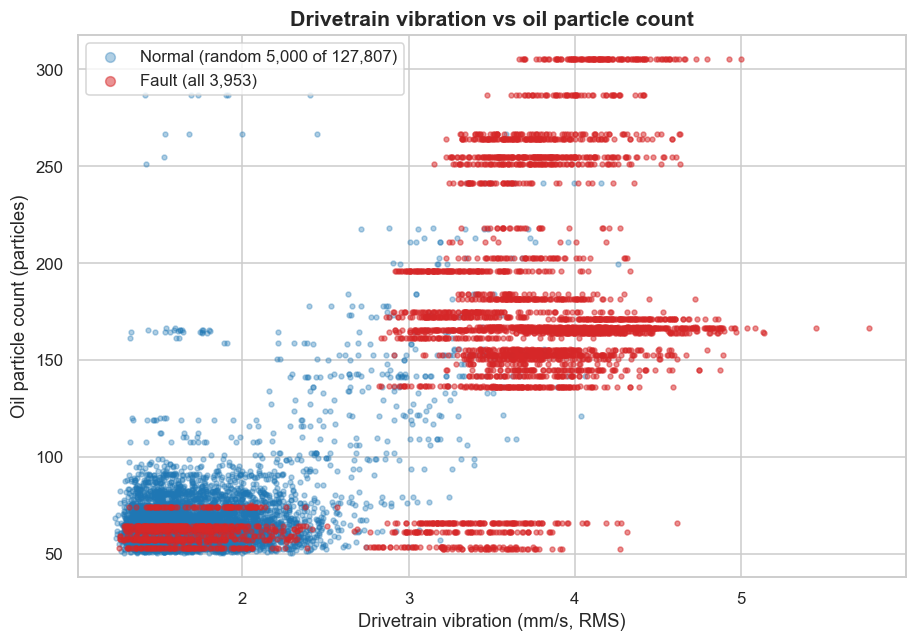

In [33]:
scatter_by_failure('drivetrain_vibration_rms_mmps', 'oil_particle_count',
                   'Drivetrain vibration vs oil particle count',
                   'Drivetrain vibration (mm/s, RMS)', 'Oil particle count (particles)')

**Used for:** Checking whether two warning signs together separate faults better than one.

**What it shows:** Normal readings (blue) crowd the bottom left corner. Faults (red) spread out to the top right: when shaking and metal flakes both go up, faults appear. **75% of all fault readings** have vibration above 2.5 mm/s **and** more than 100 particles, against only **4% of normal readings**. The other 25% of faults sit in the blue corner and look normal on these two signs.

**Hence:** Two signs together tell more than one, but they still miss about a quarter of the faults.

**Scatter plot: wind speed vs power output.** This is the power curve of a turbine. We check whether faults sit anywhere special on it.

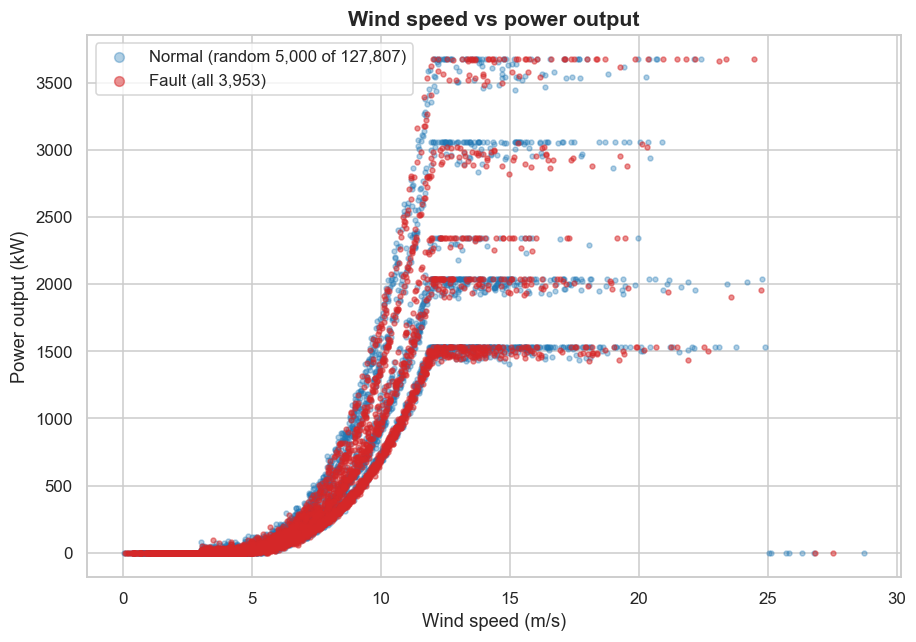

In [34]:
scatter_by_failure('wind_speed_mps', 'power_output_kW',
                   'Wind speed vs power output',
                   'Wind speed (m/s)', 'Power output (kW)')

**Used for:** Checking that the turbines behave as expected, and whether faults show up on the power curve.

**What it shows:** Below about 3 m/s the turbines make almost no power. Between 3 and 12 m/s, the stronger the wind, the more power. Above 12 m/s the power stays flat at each turbine's maximum (the flat levels are the different turbine sizes). A few blue dots at 25 m/s or more sit at 0 kW: the turbine stopped itself in a storm. Red dots are spread along the whole curve.

**Hence:** Wind speed and power alone do not show a fault.

**Scatter plot: rotor speed vs generator speed.** The gearbox connects these two, so we expect them to move together.

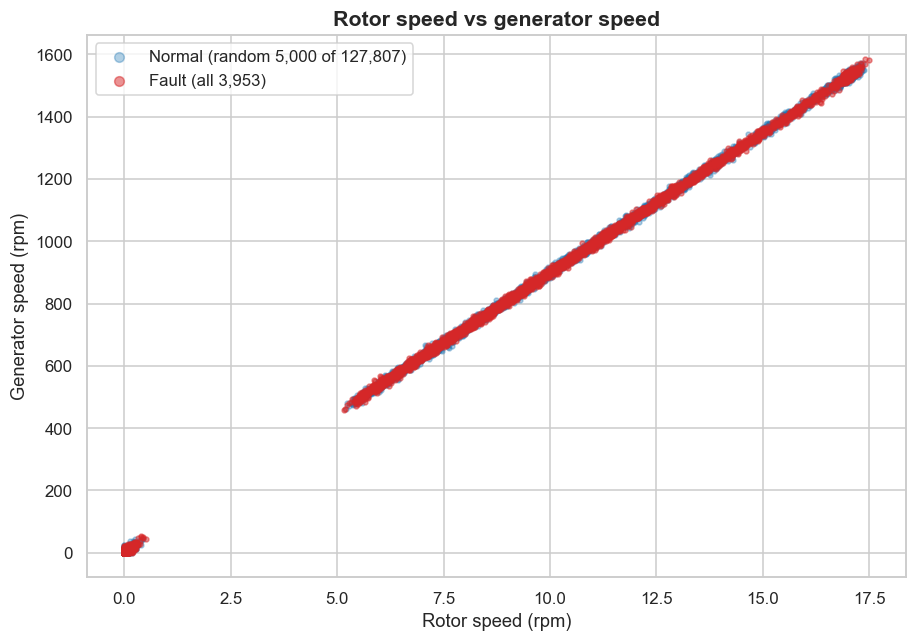

In [35]:
scatter_by_failure('rotor_speed_rpm', 'generator_speed_rpm',
                   'Rotor speed vs generator speed',
                   'Rotor speed (rpm)', 'Generator speed (rpm)')

**Used for:** Checking how the two speed measurements are linked.

**What it shows:** The dots make a perfect straight line (correlation 1.00): the faster the rotor, the faster the generator, always in the same ratio, which is set by the gearbox. The dots near 0 rpm are stopped turbines.

**Hence:** The two columns carry the same information, so one of them is enough. Faults sit on the same line, so speed does not reveal them.

## Multivariate Analysis
Now we look at many columns at once. The question is: **which columns move together, and which ones move with failure?**

### Correlation heatmap of all numeric columns
Correlation is a number from -1 to +1. Near +1 means two columns rise together. Near -1 means one rises as the other falls. Near 0 means no link. We only show the lower half of the map, because the upper half is a mirror copy. A number is written in a square only when the link is 0.3 or stronger (in either direction).

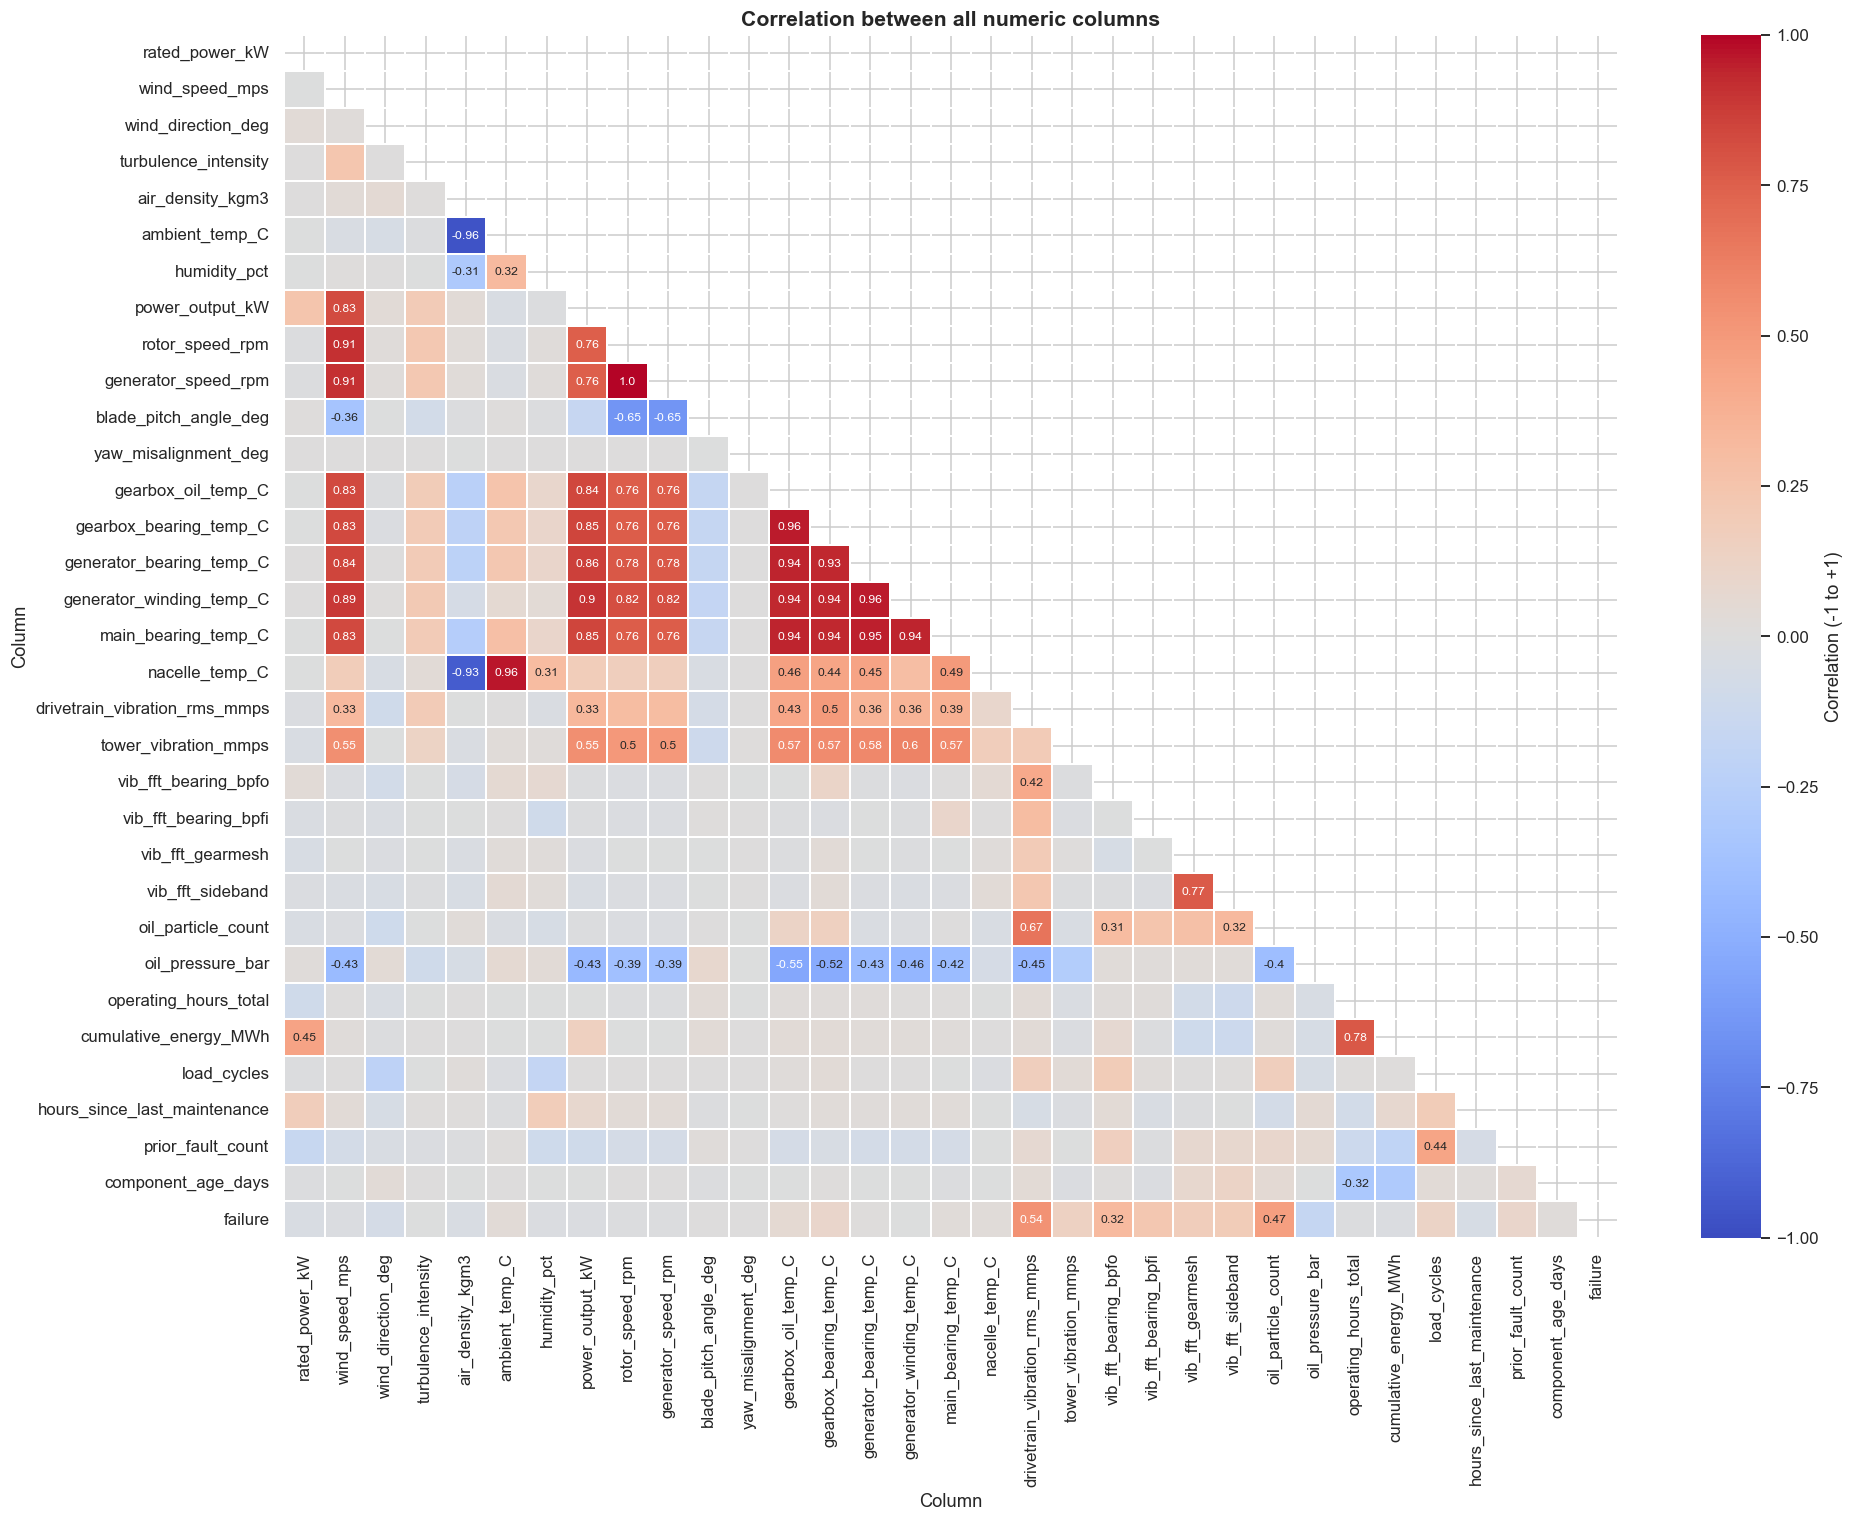

In [36]:
numeric_cols = data.select_dtypes(include='number').columns        # all number columns, including failure
corr = data[numeric_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))                      # hide the mirror half

# Write a number only where the link is 0.3 or stronger, so the strong links stand out
labels = corr.round(2).astype(str).where(corr.abs() >= 0.3, '')

plt.figure(figsize=(18, 14))
sns.heatmap(corr, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            annot=labels, fmt='', annot_kws={'size': 8}, linewidths=0.3,
            cbar_kws={'label': 'Correlation (-1 to +1)'})
plt.title('Correlation between all numeric columns')
plt.xlabel('Column')
plt.ylabel('Column')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**Used for:** Finding which columns move together (and so repeat each other), and which move with failure.

**What it shows:** Many columns repeat each other. All the temperatures (gearbox oil, gearbox bearing, generator bearing, generator winding, main bearing) move together at 0.93 to 0.96: when one is hot, they all are. Rotor speed and generator speed are identical (1.00). Air density mirrors ambient temperature (-0.96): the warmer the air, the thinner it is. The `failure` row is mostly pale.

**Hence:** We have fewer truly different columns than it seems, and no single column explains failure on its own.

### Which columns move with failure?
The big map is crowded, so here we pull out just the `failure` column and rank the 12 columns most linked to it.

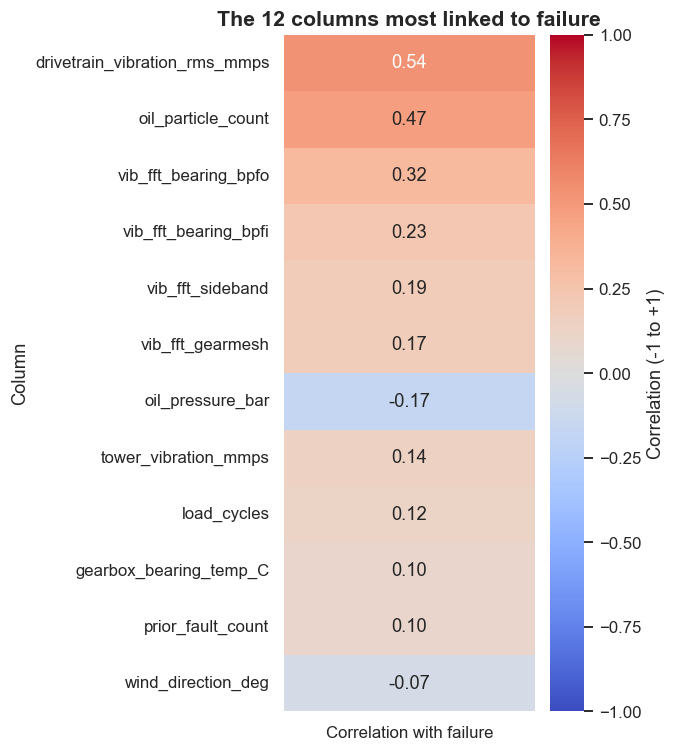

In [37]:
top_corr = (data[numeric_cols].corr()['failure'].drop('failure')
            .sort_values(key=abs, ascending=False).head(12))

plt.figure(figsize=(6, 7))
sns.heatmap(top_corr.to_frame('Correlation with failure'), annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0, cbar_kws={'label': 'Correlation (-1 to +1)'}, annot_kws={'size': 12})
plt.title('The 12 columns most linked to failure')
plt.ylabel('Column')
plt.tight_layout()
plt.show()

**Used for:** Ranking which columns are most linked to failure.

**What it shows:** Drivetrain vibration (**0.54**) and oil particle count (**0.47**) are the most linked, followed by the bearing defect signals BPFO (0.32) and BPFI (0.23). Oil pressure is the only one in the list that goes the other way (-0.17): the lower the pressure, the more likely a fault. Temperatures are weak (gearbox bearing 0.10).

**Hence:** Vibration and oil particles are the main clues. Even the strongest link is only 0.54, so no single sensor is enough on its own.

### Pair plot of the key columns
A pair plot draws every pair of chosen columns at once. We use four columns: vibration, oil particles, the bearing defect signal (BPFO) and oil pressure. To keep the plot clear we use **1,000 random normal readings and 1,000 random fault readings**. Because the two groups are made equal in size here, only look at the pattern, not at how many dots there are.

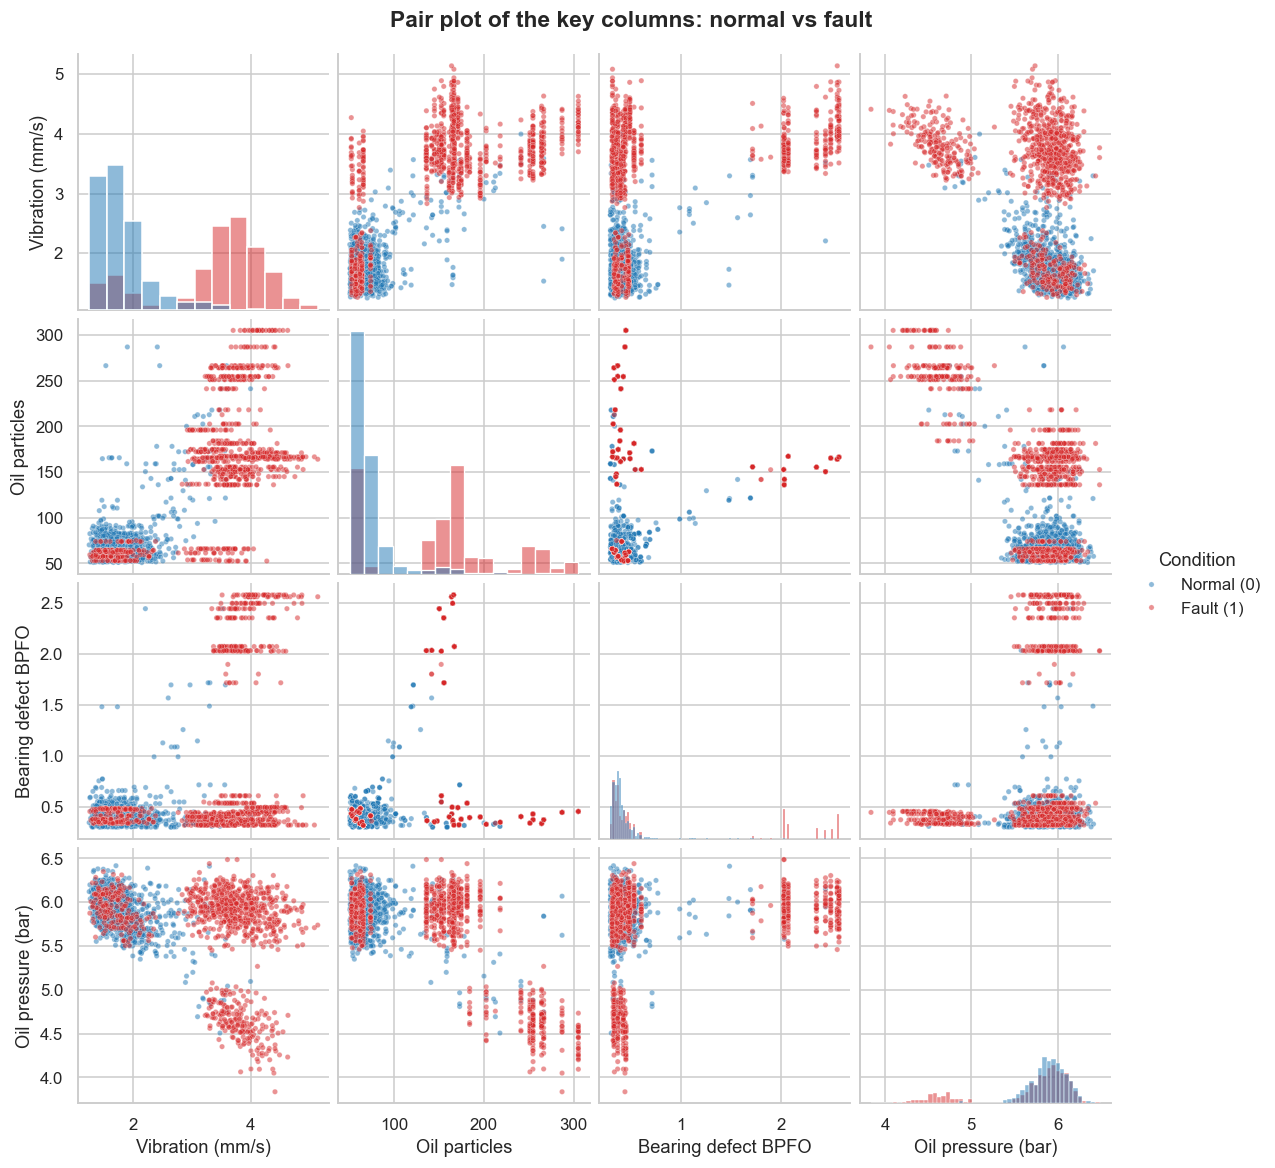

In [38]:
pair_cols = {'drivetrain_vibration_rms_mmps': 'Vibration (mm/s)',
             'oil_particle_count': 'Oil particles',
             'vib_fft_bearing_bpfo': 'Bearing defect BPFO',
             'oil_pressure_bar': 'Oil pressure (bar)'}

pair_data = pd.concat([data[data['failure'] == 0].sample(1000, random_state=42),
                       data[data['failure'] == 1].sample(1000, random_state=42)])
pair_data = pair_data[list(pair_cols) + ['failure']].rename(columns=pair_cols)
pair_data['Condition'] = pair_data['failure'].map(LABELS)

g = sns.pairplot(pair_data.drop(columns='failure'), hue='Condition', diag_kind='hist',
                 palette={'Normal (0)': NORMAL_COLOR, 'Fault (1)': FAULT_COLOR},
                 plot_kws={'s': 12, 'alpha': 0.5}, height=2.6)
g.fig.suptitle('Pair plot of the key columns: normal vs fault', y=1.02, fontsize=15, fontweight='bold')
plt.show()

**Used for:** Seeing four key columns against each other in one picture, to find which combinations separate faults from normal readings.

**What it shows:** The red and blue dots separate most in the plots that use **vibration** and **oil particles**. Oil pressure adds something new: a group of faults has pressure between 4 and 5 bar, and those same faults also have high vibration and many metal particles. 20% of fault readings have oil pressure below 5 bar, against 0.6% of normal readings. The bearing defect signal (BPFO) sits near 0.4 for most readings but jumps above 1 for 24% of faults, against 1.6% of normal readings.

**Hence:** No single column catches every fault, so the model will use them together.

# **Data Preprocessing**

Before we build any model, we clean and prepare the data. This section follows the order of the project steps:

1. **Missing value detection:** find the empty cells and see what they look like.
2. **Missing value treatment (choice):** decide whether to drop the rows or fill the gaps with the mean, the median or the mode.
3. **Feature engineering:** make new, more useful columns (we have dates to work with).
4. **Preparing the data for modeling:** check duplicates, separate the target from the inputs, and split the data by time.
5. **Missing value treatment (fill):** fill the gaps, using the training data only.

For every step we say what we did and why. When we skip something, we say why we skipped it.

### Column names for the charts
This cell sets the chart style and gives the three columns with gaps a plain name, so the charts in this section are easy to read.

In [39]:
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 14, 'axes.titleweight': 'bold',
                     'axes.labelsize': 12, 'xtick.labelsize': 11, 'ytick.labelsize': 11,
                     'legend.fontsize': 11})

# Nice names for the three columns that have missing values
NAMES = {'gearbox_oil_temp_C': 'Gearbox oil temperature (°C)',
         'generator_bearing_temp_C': 'Generator bearing temperature (°C)',
         'oil_pressure_bar': 'Oil pressure (bar)'}

## 1. Missing value detection
A missing value is an empty cell: the sensor did not send a reading for that 10-minute slot. Python calls it NaN ("not a number"). We first count them, so we know how big the problem is.

This cell counts the empty cells in every column and keeps only the columns that have any. It also counts how many rows have at least one gap.

In [40]:
missing_count = data.isnull().sum()

missing_table = pd.DataFrame({'Missing readings': missing_count,
                              'Share of all readings (%)': (missing_count / len(data) * 100).round(2)})
missing_table = missing_table[missing_table['Missing readings'] > 0].sort_values('Missing readings', ascending=False)
display(missing_table)

rows_with_gap = data.isnull().any(axis=1)
print(f"Columns with no missing values: {(missing_count == 0).sum()} of {data.shape[1]}")
print(f"Rows with at least one gap: {rows_with_gap.sum():,} of {len(data):,} ({rows_with_gap.mean():.2%})")
print(f"Empty cells in the whole table: {data.isnull().sum().sum():,} of {data.size:,} ({data.isnull().sum().sum() / data.size:.3%})")

,Missing readings,Share of all readings (%)
generator_bearing_temp_C,690,0.52
gearbox_oil_temp_C,645,0.49
oil_pressure_bar,636,0.48


Columns with no missing values: 32 of 35
Rows with at least one gap: 1,965 of 131,760 (1.49%)
Empty cells in the whole table: 1,971 of 4,611,600 (0.043%)


**Used for:** Finding which columns have empty cells, and how many.

**What it shows:** Only **3 of the 35 columns** have gaps: generator bearing temperature (690), gearbox oil temperature (645) and oil pressure (636). Each is about 0.5% of its readings. In total 1,965 rows (1.5%) have at least one gap, and only 0.04% of all the cells in the table are empty.

**Hence:** The problem is small. We still have to deal with it, because most models cannot run when a cell is empty.

This chart shows the same thing as a picture: how much of each column is missing. The axis stops at 1% on purpose, so you can see that all three bars are tiny.

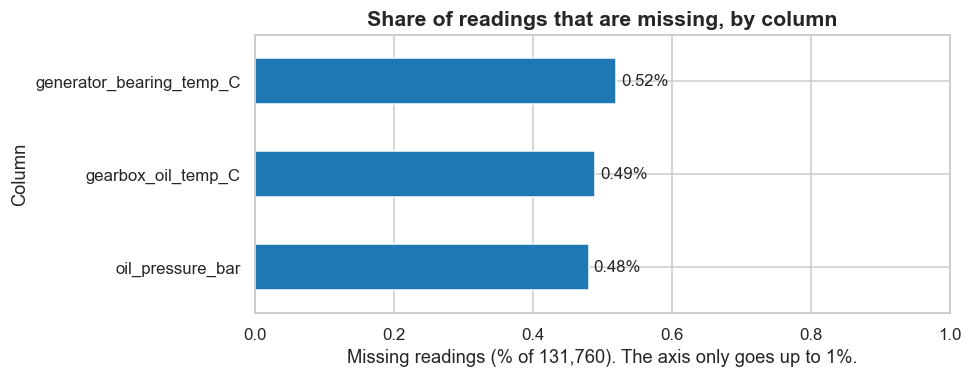

In [41]:
ax = missing_table['Share of all readings (%)'].sort_values().plot(kind='barh', figsize=(9, 3.6), color='#1F77B4')
ax.bar_label(ax.containers[0], fmt='%.2f%%', padding=3, fontsize=11)
ax.set_xlim(0, 1)
ax.set_title('Share of readings that are missing, by column')
ax.set_xlabel('Missing readings (% of 131,760). The axis only goes up to 1%.')
ax.set_ylabel('Column')
plt.tight_layout()
plt.show()

**Used for:** Seeing how much of each column is missing.

**What it shows:** All three bars are about half of one percent (0.48% to 0.52%). The other 32 columns are complete.

**Hence:** No column is missing enough data to be thrown away.

Next we check whether the gaps are bunched up (one broken turbine, or one long outage) or scattered around. We count the gaps for each turbine, find the longest stretch of gaps in a row, and check whether faults are more common where there is a gap.

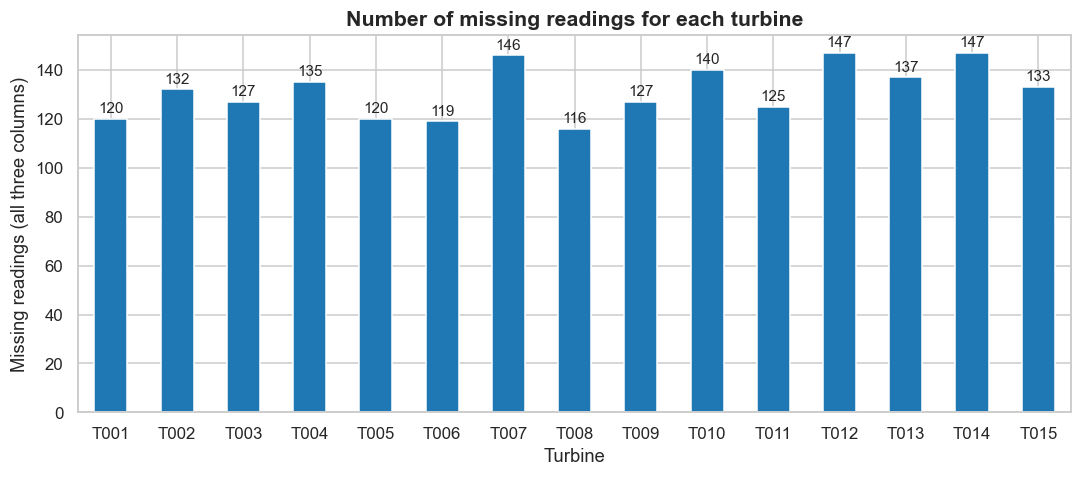

generator_bearing_temp_C: longest stretch of gaps in a row = 2 reading(s)
gearbox_oil_temp_C: longest stretch of gaps in a row = 2 reading(s)
oil_pressure_bar: longest stretch of gaps in a row = 2 reading(s)

Fault rate in rows with a gap: 3.21%
Fault rate in all rows: 3.00%


In [42]:
gap_cols = missing_table.index.tolist()

# 1. Gaps per turbine
gaps_per_turbine = data.groupby('turbine_id')[gap_cols].apply(lambda x: x.isnull().sum().sum())

plt.figure(figsize=(10, 4.5))
ax = gaps_per_turbine.plot(kind='bar', color='#1F77B4')
ax.bar_label(ax.containers[0], padding=2, fontsize=10)
ax.set_title('Number of missing readings for each turbine')
ax.set_xlabel('Turbine')
ax.set_ylabel('Missing readings (all three columns)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Longest stretch of gaps in a row (data is already in time order inside each turbine)
for col in gap_cols:
    gap = data[col].isnull()
    stretch_id = gap.ne(gap.groupby(data['turbine_id']).shift()).cumsum()
    longest = int(stretch_id[gap].value_counts().max())
    print(f"{col}: longest stretch of gaps in a row = {longest} reading(s)")

# 3. Are faults more common where there is a gap?
print(f"\nFault rate in rows with a gap: {data.loc[rows_with_gap, 'failure'].mean():.2%}")
print(f"Fault rate in all rows: {data['failure'].mean():.2%}")

**Used for:** Checking whether the gaps come from one bad turbine, one long outage, or are linked to faults.

**What it shows:** Every turbine has between 116 and 147 gaps, so no turbine stands out. The longest stretch of gaps in a row is 2 readings (20 minutes). Rows with a gap are faults 3.2% of the time, against 3.0% for all rows.

**Hence:** The gaps look like small, random sensor drop-outs. They are not linked to one turbine or to faults, so filling them in will not hide anything important.

## 2. Missing value treatment: mean, median or mode?
We have four options:

- **Drop the rows with a gap.** We would lose 1,965 readings, some of them real faults, and we would break the steady 10-minute sequence. For such a small problem this is not worth it, so we do not drop anything.
- **Fill with the mean.** The mean is the average: add everything up and divide by the count.
- **Fill with the median.** The median is the middle reading: line them all up and take the one in the centre.
- **Fill with the mode.** The mode is the most common value.

To choose, we look at the shape of each column. The next cell puts the mean, median and mode side by side, and shows how many different values each column has.

In [43]:
rows = []
for col in gap_cols:
    values = data[col].dropna()
    mode_value = values.mode()[0]
    rows.append({'Column': col,
                 'Mean': values.mean(),
                 'Median': values.median(),
                 'Mode': mode_value,
                 'Times the mode appears': int((values == mode_value).sum()),
                 'Different values in the column': values.nunique(),
                 'Skew': values.skew()})
display(pd.DataFrame(rows).set_index('Column').round(2))

,Mean,Median,Mode,Times the mode appears,Different values in the column,Skew
Column,,,,,,
generator_bearing_temp_C,62.39,58.41,56.37,19,38734,0.88
gearbox_oil_temp_C,58.21,54.31,53.52,17,39598,0.85
oil_pressure_bar,5.89,5.92,5.95,320,2124,-1.77


This chart shows the shape of each column. The dashed black line is the mean and the green line is the median. If the two lines are far apart, a few extreme readings are pulling the average away from the typical reading.

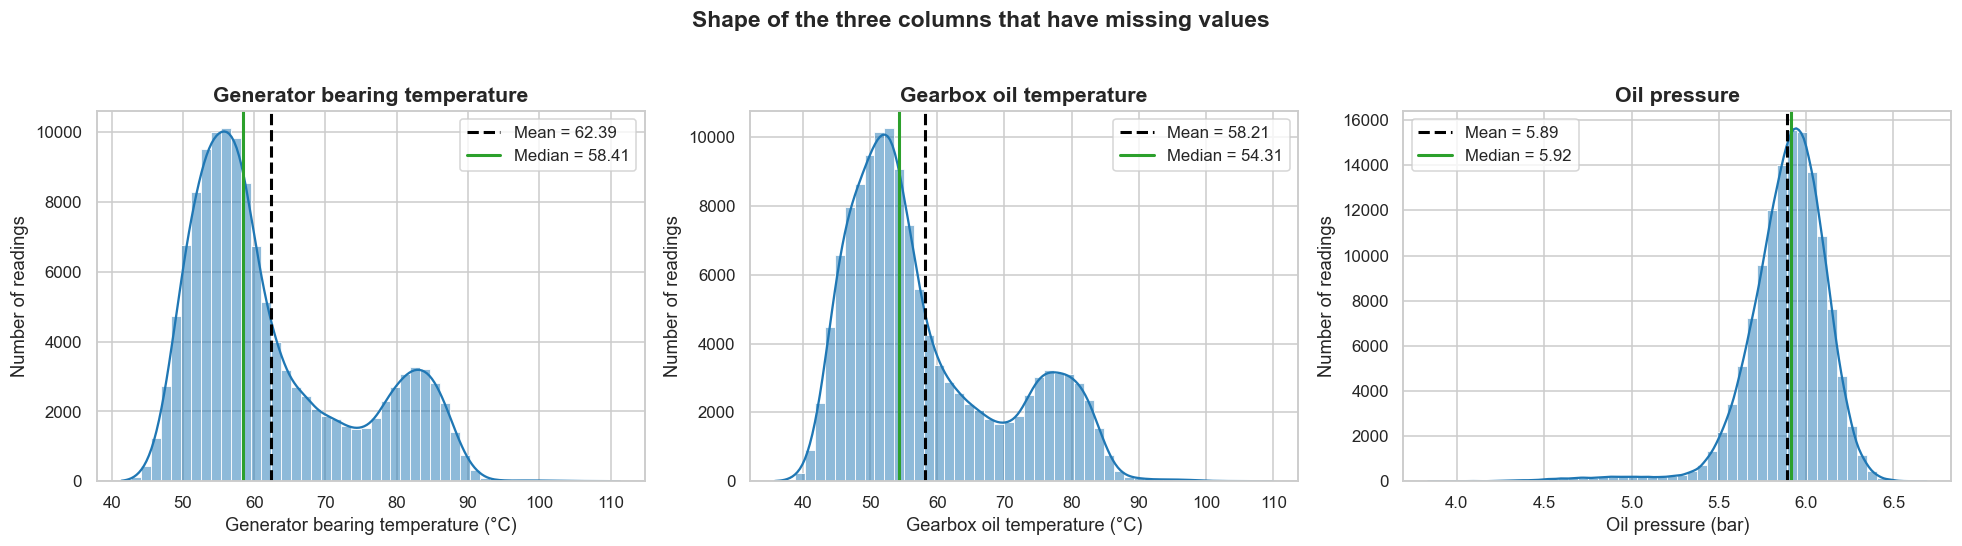

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, col in zip(axes, gap_cols):
    values = data[col].dropna()
    sns.histplot(values, bins=50, kde=True, color='#1F77B4', ax=ax)
    ax.axvline(values.mean(), color='black', linestyle='--', linewidth=2, label=f'Mean = {values.mean():,.2f}')
    ax.axvline(values.median(), color='#2CA02C', linestyle='-', linewidth=2, label=f'Median = {values.median():,.2f}')
    ax.set_title(NAMES[col].split(' (')[0])
    ax.set_xlabel(NAMES[col])
    ax.set_ylabel('Number of readings')
    ax.legend()
fig.suptitle('Shape of the three columns that have missing values', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Used for:** Choosing between the mean, the median and the mode.

**What it shows:** In the two temperature columns the hot readings pull the mean up: gearbox oil temperature has a mean of 58.2 °C but a median of 54.3 °C, and generator bearing temperature 62.4 °C against 58.4 °C. Oil pressure leans the other way: a few low-pressure readings pull the mean down to 5.89 bar, while the median is 5.92 bar. The mode is no use here. The sensors measure to many decimals, so values hardly repeat: the most common gearbox oil temperature shows up only 17 times out of 131,115.

**Hence:** We fill with the **median** in all three columns. It is the typical reading and the extreme readings do not move it. One small catch: both temperature columns have two humps (low load and high load), so a gap that happened during hard work gets a typical value that is a little too low. With only 0.5% of readings affected, that is fine.

## 3. Feature engineering
Feature engineering means making new, more useful columns from the ones we already have.

**Do we have dates? Yes.** The `timestamp` column holds the date and time of every reading. But it is stored as plain text (type `object`), and a model cannot read a text date. First we check what we have.

In [45]:
print('Type of the timestamp column:', data['timestamp'].dtype)
data['timestamp'].head(3)

Type of the timestamp column: object


0    1/1/2024 0:00
1    1/1/2024 0:10
2    1/1/2024 0:20
Name: timestamp, dtype: object

**Used for:** Checking how the date and time are stored.

**What it shows:** The type is `object`, which means plain text, like "1/1/2024 0:00". It looks like a date to us, but to Python it is just letters and numbers.

**Hence:** We have to turn the text into a real date and time first.

**Step 1: turn the text into a real date and time.** After this, Python knows that "1/1/2024 0:10" comes ten minutes after "1/1/2024 0:00", and it can pull out parts like the hour. We also check that nothing is missing in the time line.

In [46]:
data['timestamp'] = pd.to_datetime(data['timestamp'], format='%m/%d/%Y %H:%M')

print('Type now:', data['timestamp'].dtype)
print('First reading:', data['timestamp'].min())
print('Last reading: ', data['timestamp'].max())
print('Readings per turbine:', data.groupby('turbine_id').size().unique(), '(61 days x 144 readings a day = 8,784, so no reading is missing)')

Type now: datetime64[ns]
First reading: 2024-01-01 00:00:00
Last reading:  2024-03-01 23:50:00
Readings per turbine: [8784] (61 days x 144 readings a day = 8,784, so no reading is missing)


**Used for:** Turning the text dates into real dates, and checking the time line is complete.

**What it shows:** The type is now a date and time. The data runs from 1 January 2024 to 1 March 2024. Each turbine has exactly 8,784 readings, which is 61 days times 144 readings a day.

**Hence:** The time line has no holes, so the date can be trusted.

**Step 2: pull out the hour and the day of the week.** A date as a whole is not useful to a model, because every row has a different one. But the hour (0 to 23) and the day of the week (0 = Monday to 6 = Sunday) repeat, so a model can look for patterns in them. Maybe faults are more common at night, or on certain days.

In [47]:
data['hour'] = data['timestamp'].dt.hour               # 0 to 23
data['dayofweek'] = data['timestamp'].dt.dayofweek     # 0 = Monday ... 6 = Sunday

data[['timestamp', 'hour', 'dayofweek']].head()

,timestamp,hour,dayofweek
0,2024-01-01 00:00:00,0,0
1,2024-01-01 00:10:00,0,0
2,2024-01-01 00:20:00,0,0
3,2024-01-01 00:30:00,0,0
4,2024-01-01 00:40:00,0,0


**Used for:** Making two new columns that a model can use.

**What it shows:** Each reading now has an `hour` and a `dayofweek` next to its timestamp. The first reading, 1 January 2024 at 00:00, is hour 0 and day 0, because it was a Monday.

**Hence:** We have two new features. Next we check whether they carry any signal.

This chart checks whether the new columns are useful. The left chart shows how often readings are faults at each hour, and the right chart does the same for each day of the week. The dashed line is the overall fault rate (3.0%).

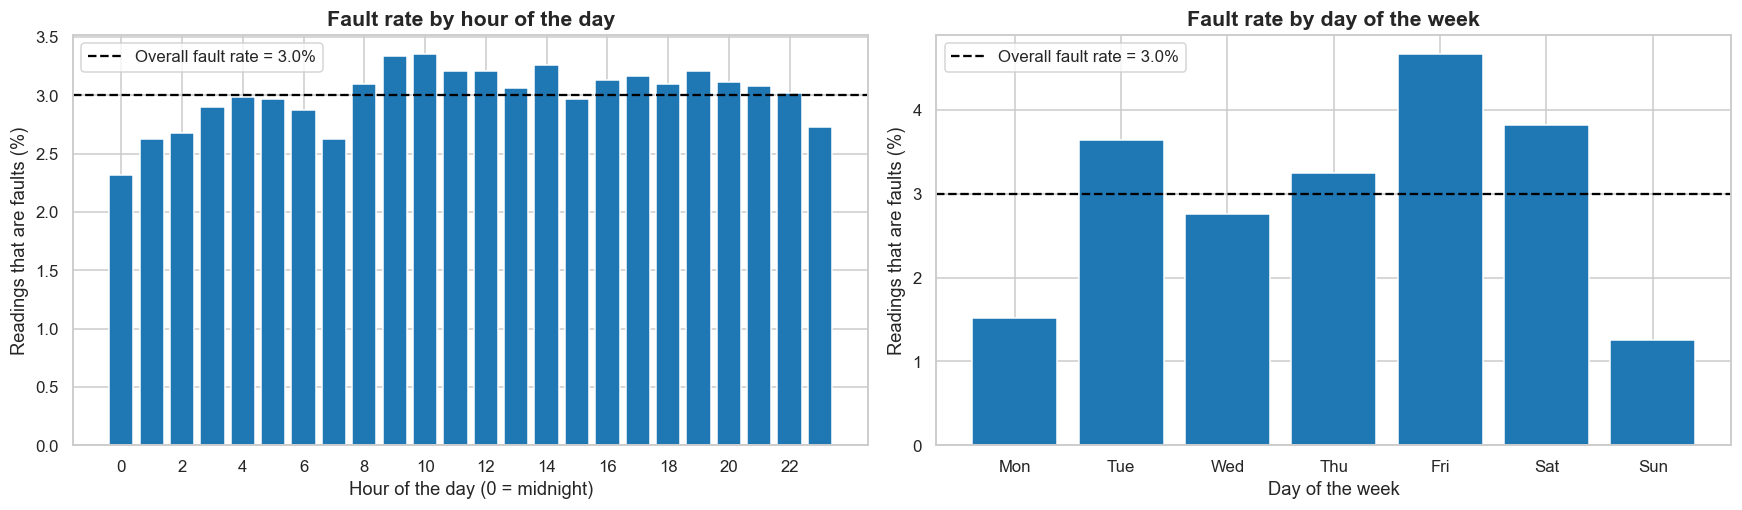

In [48]:
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
overall = data['failure'].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))

by_hour = data.groupby('hour')['failure'].mean() * 100
axes[0].bar(by_hour.index, by_hour.values, color='#1F77B4')
axes[0].axhline(overall, color='black', linestyle='--', label=f'Overall fault rate = {overall:.1f}%')
axes[0].set_title('Fault rate by hour of the day')
axes[0].set_xlabel('Hour of the day (0 = midnight)')
axes[0].set_ylabel('Readings that are faults (%)')
axes[0].set_xticks(range(0, 24, 2))
axes[0].legend()

by_day = data.groupby('dayofweek')['failure'].mean() * 100
axes[1].bar(day_names, by_day.values, color='#1F77B4')
axes[1].axhline(overall, color='black', linestyle='--', label=f'Overall fault rate = {overall:.1f}%')
axes[1].set_title('Fault rate by day of the week')
axes[1].set_xlabel('Day of the week')
axes[1].set_ylabel('Readings that are faults (%)')
axes[1].legend()

plt.tight_layout()
plt.show()

**Used for:** Checking whether the hour and the day of the week tell us anything about faults.

**What it shows:** By hour, the fault rate barely moves: it stays between 2.3% and 3.4%. By day, it swings more, from 1.3% on Sunday to 4.7% on Friday.

**Hence:** We keep both columns. They cost nothing and the model can ignore them if they do not help. We do not read too much into the weekday pattern: the data covers only two months, and a fault lasts many readings in a row, so a few long faults can make one day look bad.

**Do we need to change anything else?** We went through the other columns and decided this:

- `timestamp` is dropped before modelling, because the hour and day of the week now carry what we need from it.
- `turbine_id` is dropped too. We want the model to work on any turbine, including ones it has never seen, and the sensor readings already describe the state of the machine.
- Skewed columns such as oil particle count and vibration are **not** transformed. The tree models do not care about the shape of a column, and the neural network gets its columns scaled later.
- Rotor speed and generator speed say the same thing. We keep both, because it does no harm to the models.
- No text columns are left after `turbine_id` goes, so we do not need to turn anything into numbers.

## 4. Preparing the data for modeling: duplicates, target and split
**Duplicates and inconsistencies.** The Data Overview found 0 duplicate rows and no impossible values, so there is nothing to remove.

**Separating the target.** The answer we want to predict (`failure`) is kept apart from the inputs: `X` holds the input columns and `y` holds `failure`.

**Splitting.** We cut the data into three parts, in time order:

- **Train (oldest 70%)**: the model learns from this.
- **Validation (next 15%)**: we use it to compare and tune the models.
- **Test (newest 15%)**: we keep it untouched until the very end, for a final check.

**Why by time and not at random?** One fault lasts many 10-minute readings in a row. With a random split, pieces of the same fault would land in both train and test, and the model would be tested on faults it has already seen. A split by time works like real life: the model learns from the past and is tested on the future.

We do the split **before** filling the gaps, so that the fill values come from the training data only.

First we sort the readings by time, and count how many rows we have.

In [49]:
data = data.sort_values(by=['timestamp', 'turbine_id'])
n = len(data)
print(f'Total readings: {n:,}')

Total readings: 131,760


Here we pick the split sizes. The template offers three choices, and we choose 70% / 15% / 15%. It gives the model plenty to learn from and still leaves 19,764 readings each for validation and test.

In [50]:
# Uncomment the below train and validation indices to create a 70% train, 15% validation, and 15% test split.
i_train = int(n * 0.70)
i_val = int(n * 0.85)

# Uncomment the below train and validation indices to create a 90% train, 5% validation, and 5% test split.
# i_train = int(n * 0.90)
# i_val = int(n * 0.95)

# Uncomment the below train and validation indices to create a 80% train, 10% validation, and 10% test split.
# i_train = int(n * 0.80)
# i_val = int(n * 0.90)

This cell makes the three parts. `X` holds the input columns (what the model looks at) and `y` holds the answer (`failure`). We take `failure`, `timestamp` and `turbine_id` out of the inputs, as explained above.

In [51]:
data_train = data.iloc[:i_train]
data_val = data.iloc[i_train:i_val]
data_test = data.iloc[i_val:]

X_train = data_train.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_train = data_train['failure']

X_valid = data_val.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_valid = data_val['failure']

X_test = data_test.drop(columns=['failure', 'timestamp', 'turbine_id'])
y_test = data_test['failure']

for name, part in [('Train', data_train), ('Validation', data_val), ('Test', data_test)]:
    print(f"{name:<11}{len(part):>8,} readings   {part['timestamp'].min():%d %b %Y} to {part['timestamp'].max():%d %b %Y}")
print('\nInput columns:', X_train.shape[1])

Train        92,232 readings   01 Jan 2024 to 12 Feb 2024
Validation   19,764 readings   12 Feb 2024 to 21 Feb 2024
Test         19,764 readings   21 Feb 2024 to 01 Mar 2024

Input columns: 34


This chart shows how common faults are in each part. It matters because the model needs faults to learn from, and faults to be tested on.

Train split failure rate: 1.60%
Validation split failure rate: 5.26%
Test split failure rate: 7.29%


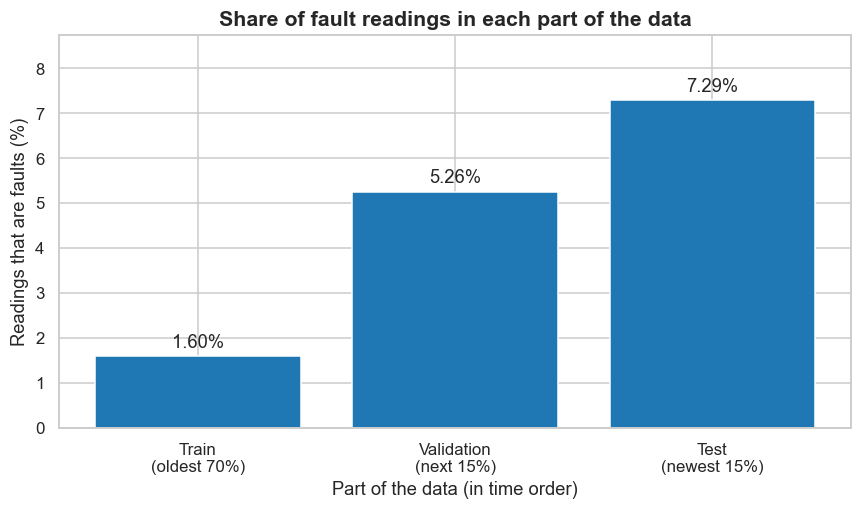

In [52]:
print(f'Train split failure rate: {y_train.mean()*100:.2f}%')
print(f'Validation split failure rate: {y_valid.mean()*100:.2f}%')
print(f'Test split failure rate: {y_test.mean()*100:.2f}%')

rates = [y_train.mean() * 100, y_valid.mean() * 100, y_test.mean() * 100]
plt.figure(figsize=(8, 4.8))
bars = plt.bar(['Train\n(oldest 70%)', 'Validation\n(next 15%)', 'Test\n(newest 15%)'], rates,
               color=['#1F77B4', '#1F77B4', '#1F77B4'])
plt.bar_label(bars, fmt='%.2f%%', padding=3, fontsize=12)
plt.title('Share of fault readings in each part of the data')
plt.xlabel('Part of the data (in time order)')
plt.ylabel('Readings that are faults (%)')
plt.ylim(0, max(rates) * 1.2)
plt.tight_layout()
plt.show()

**Used for:** Checking that each part has faults to learn from and to be tested on.

**What it shows:** Faults are **1.60%** of the train part, **5.26%** of validation and **7.29%** of test. The later the period, the more faults there are.

**Hence:** The model learns from a calm period and is tested on a harder one. If it still catches most faults on the test part, that is a strong result. We keep this in mind when we read the test scores.

## 5. Missing value treatment: filling the gaps with the training median
Now we fill the gaps. For each of the three columns we:

1. work out the **median of the training data only**,
2. use that one number to fill the gaps in train, validation and test.

**Why only the training data?** Validation and test pretend to be the future. If we used their numbers to fill the gaps, the model would get a small peek at the future. Using the training median for all three parts keeps the test fair.

First, a quick look at how many gaps each part has.

In [53]:
pct_missing = pd.DataFrame({'Train (%)': X_train.isnull().mean() * 100,
                           'Validation (%)': X_valid.isnull().mean() * 100,
                           'Test (%)': X_test.isnull().mean() * 100}).round(2)
pct_missing[pct_missing.sum(axis=1) > 0]

,Train (%),Validation (%),Test (%)
gearbox_oil_temp_C,0.50,0.49,0.46
generator_bearing_temp_C,0.52,0.54,0.54
oil_pressure_bar,0.47,0.51,0.51


**Used for:** Checking how many gaps each part of the data has before we fill them.

**What it shows:** Each of the three columns is missing about 0.5% of its readings in every part (between 0.46% and 0.54%).

**Hence:** The gaps are spread evenly over time, so one fill rule works for all three parts.

**Gearbox oil temperature.** We choose the median (see the explanation in step 2).

In [54]:
# Uncomment one of the following statistics for the imputation strategy
# oil_temp_train_stat = X_train['gearbox_oil_temp_C'].mean()      # to impute using mean
oil_temp_train_stat = X_train['gearbox_oil_temp_C'].median()      # to impute using median   <- chosen
# oil_temp_train_stat = X_train['gearbox_oil_temp_C'].mode()[0]   # to impute using mode

X_train['gearbox_oil_temp_C'] = X_train['gearbox_oil_temp_C'].fillna(oil_temp_train_stat)
X_valid['gearbox_oil_temp_C'] = X_valid['gearbox_oil_temp_C'].fillna(oil_temp_train_stat)
X_test['gearbox_oil_temp_C']  = X_test['gearbox_oil_temp_C'].fillna(oil_temp_train_stat)

print(f'Value used to fill the gaps: {oil_temp_train_stat:.2f} °C')

Value used to fill the gaps: 53.92 °C


**Generator bearing temperature.** Same choice, for the same reason.

In [55]:
# Uncomment one of the following statistics for the imputation strategy
# bearing_temp_train_stat = X_train['generator_bearing_temp_C'].mean()      # to impute using mean
bearing_temp_train_stat = X_train['generator_bearing_temp_C'].median()      # to impute using median   <- chosen
# bearing_temp_train_stat = X_train['generator_bearing_temp_C'].mode()[0]   # to impute using mode

X_train['generator_bearing_temp_C'] = X_train['generator_bearing_temp_C'].fillna(bearing_temp_train_stat)
X_valid['generator_bearing_temp_C'] = X_valid['generator_bearing_temp_C'].fillna(bearing_temp_train_stat)
X_test['generator_bearing_temp_C']  = X_test['generator_bearing_temp_C'].fillna(bearing_temp_train_stat)

print(f'Value used to fill the gaps: {bearing_temp_train_stat:.2f} °C')

Value used to fill the gaps: 58.11 °C


**Oil pressure.** Here the mean and median are very close, so either would work. We still use the median, so all three columns are treated the same way.

In [56]:
# Uncomment one of the following statistics for the imputation strategy
# oil_pressure_train_stat = X_train['oil_pressure_bar'].mean()      # to impute using mean
oil_pressure_train_stat = X_train['oil_pressure_bar'].median()      # to impute using median   <- chosen
# oil_pressure_train_stat = X_train['oil_pressure_bar'].mode()[0]   # to impute using mode

X_train['oil_pressure_bar'] = X_train['oil_pressure_bar'].fillna(oil_pressure_train_stat)
X_valid['oil_pressure_bar'] = X_valid['oil_pressure_bar'].fillna(oil_pressure_train_stat)
X_test['oil_pressure_bar']  = X_test['oil_pressure_bar'].fillna(oil_pressure_train_stat)

print(f'Value used to fill the gaps: {oil_pressure_train_stat:.2f} bar')

Value used to fill the gaps: 5.92 bar


Last check: are there any empty cells left in any part?

In [57]:
left = pd.DataFrame({'Empty cells left': [X_train.isnull().sum().sum(), X_valid.isnull().sum().sum(), X_test.isnull().sum().sum()],
                     'Rows': [len(X_train), len(X_valid), len(X_test)]},
                    index=['Train', 'Validation', 'Test'])
display(left)

,Empty cells left,Rows
Train,0,92232
Validation,0,19764
Test,0,19764


**Used for:** Making sure the gaps are gone before we build models.

**What it shows:** The gaps were filled with the training medians: 53.92 °C for gearbox oil temperature, 58.11 °C for generator bearing temperature and 5.92 bar for oil pressure. There are 0 empty cells left in train, validation and test.

**Hence:** The data is clean and ready for the models. We kept every row, we used the same fill values everywhere, and the test part never influenced the fill.

# **Model Building - Baseline**

In this section we build the **five baseline models** the project asks for:

1. Decision Tree
2. Random Forest
3. Gradient Boosting
4. XGBoost
5. Artificial Neural Network (ANN)

"Baseline" means a first, simple version of each model, built with the settings the template gives us. We do not tune anything yet. The goal is to see how each one does out of the box, so that later we can pick the best ones to improve.

All five are trained on the **imbalanced** training data, where only 1.6% of the readings are faults (1,474 faults against 90,758 normal readings). If we did nothing, a model could ignore the faults and still look good. So each model gets a way to treat a fault as more important than a normal reading: a "balanced" setting for the tree and the forest, `scale_pos_weight` for XGBoost, and class weights for the neural network. Gradient Boosting has no such setting in this template, so we train it as it is and see what happens.

### Before you start
The models need the training, validation and test data that the **Data Preprocessing** section creates (`X_train`, `y_train` and so on). If you run this section on its own, or after restarting the kernel, those names do not exist yet and you get a `NameError`. The cell below checks for them. If anything is missing, it tells you what to run first.

**The easy way:** click the first cell of this section, then use the menu **Run > Run All Above Selected Cell**. (Skip the `!pip install` cell at the top. The libraries are already installed.)

In [58]:
needed = ['X_train', 'y_train', 'X_valid', 'y_valid', 'X_test', 'y_test']
missing = [name for name in needed if name not in globals()]
if missing:
    raise RuntimeError(f"Not ready yet. These are missing: {missing}. "
                       "Run the cells above first: the imports, the data loading and the whole Data Preprocessing section "
                       "(menu: Run > Run All Above Selected Cell).")
print(f"Ready: the training, validation and test data exist ({len(X_train):,} / {len(X_valid):,} / {len(X_test):,} readings).")

Ready: the training, validation and test data exist (92,232 / 19,764 / 19,764 readings).


## How we score the models (a quick guide)
After a model makes its guesses, every reading ends up in one of four boxes. The confusion matrix charts below show how many readings are in each box.

- **True negative:** it was normal and the model said normal. Correct.
- **False positive (false alarm):** it was normal but the model said fault. A technician checks a healthy turbine.
- **False negative (missed fault):** it was a fault but the model said normal. The fault goes unnoticed.
- **True positive (caught fault):** it was a fault and the model said fault. Correct.

From these four boxes we get four scores, each from 0 to 1 (higher is better):

- **Accuracy:** out of all readings, how many did it get right?
- **Recall:** out of all the real faults, how many did it catch?
- **Precision:** out of all the times it said "fault", how many were real faults?
- **F1:** one score that mixes precision and recall.

## Utility functions
These two helper functions are from the template. The first one calculates the four scores for a model. The second one draws the confusion matrix. We added a title and the names "Normal" and "Fault" to the matrix, so every chart says which model and which data it shows.

In [59]:
def model_performance_classification(model, predictors, target):
    """
    Function to compute different metrics to check classification model performance

    model: classifier (sklearn or tensorflow)
    predictors: independent variables
    target: dependent variable
    """

    # 1. Get raw predictions (Keras models print a progress bar, so we switch it off when we can)
    try:
        pred_raw = model.predict(predictors, verbose=0)
    except TypeError:
        pred_raw = model.predict(predictors)

    # 2. Check the shape or values to handle DL vs ML models safely
    # If the predictions are probabilities (floats between 0 and 1, not exactly 0 or 1)
    # We check if any value falls strictly between 0 and 1
    if np.issubdtype(pred_raw.dtype, np.floating) and not np.all(np.isin(pred_raw, [0.0, 1.0])):
        # FOR TENSORFLOW DL MODELS: threshold the probabilities at 0.5
        pred = (pred_raw > 0.5).astype(int)
    else:
        # FOR SKLEARN ML MODELS: use them directly
        pred = pred_raw

    # Flatten predictions to ensure they match target shape perfectly
    pred = np.array(pred).flatten()

    # 3. Compute metrics
    acc = accuracy_score(target, pred)
    recall = recall_score(target, pred)
    precision = precision_score(target, pred)
    f1 = f1_score(target, pred)

    # 4. Creating a dataframe of metrics
    data_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1": f1},
        index=[0],
    )

    return data_perf


def plot_confusion_matrix(model, predictors, target, title=None):
    """
    To plot the confusion_matrix with percentages

    model: classifier
    predictors: independent variables
    target: dependent variable
    title: name of the model and the data, shown above the chart
    """
    # 1. Get raw predictions
    try:
        y_pred_raw = model.predict(predictors, verbose=0)
    except TypeError:
        y_pred_raw = model.predict(predictors)

    # 2. Check if predictions are probabilities (typical for Keras/TF models or some ML models with predict_proba)
    # If y_pred_raw contains float values between 0 and 1, it's likely probabilities.
    if np.issubdtype(y_pred_raw.dtype, np.floating) and np.any((y_pred_raw > 0) & (y_pred_raw < 1)):
        # Binarize probabilities using a threshold (e.g., 0.5)
        y_pred = (y_pred_raw > 0.5).astype(int)
    else:
        # Use predictions directly (typical for scikit-learn classifiers that return binary labels)
        y_pred = y_pred_raw

    # Ensure y_pred is flattened to a 1D array, as confusion_matrix expects this format.
    y_pred = np.array(y_pred).flatten()

    cm = confusion_matrix(target, y_pred)
    labels = np.asarray(
        [
            ["{0:0.0f}".format(item) + "\n{0:.2%}".format(item / cm.flatten().sum())]
            for item in cm.flatten()
        ]
    ).reshape(2, 2)

    plt.figure(figsize=(6.5, 4.8))
    sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", annot_kws={"size": 13},
                xticklabels=["Normal (0)", "Fault (1)"], yticklabels=["Normal (0)", "Fault (1)"],
                cbar_kws={"label": "Number of readings"})
    plt.title(title)
    plt.ylabel("True label (what it really was)")
    plt.xlabel("Predicted label (what the model said)")
    plt.show()

## Model 1: Decision Tree classifier
**What it is, in simple words.** A decision tree is like a game of 20 questions. It asks yes or no questions about a reading ("is the vibration above 2.5?", "is the oil particle count above 100?") and follows the answers down the branches until it reaches a final guess: normal or fault.

**Settings.** `class_weight='balanced'` tells the tree that one fault counts for about 62 normal readings (the ratio in the training data), so it cannot just ignore the faults. `random_state` is a fixed number, so we get the same tree every time we run the cell.

In [60]:
# Set the random state for reproducibility.
# Choose an integer between 0 and 100.
# Using the same random state ensures the model produces the same results each time it is trained.
RS = 42

In [61]:
dt_class_model = DecisionTreeClassifier(class_weight='balanced', random_state=RS)
dt_class_model.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', random_state=42)

**Results on the training data** (the data the tree learned from).

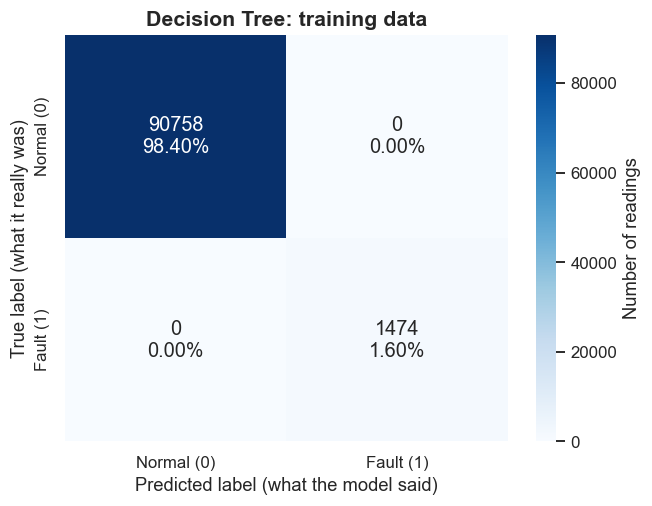

Decision Tree: training performance


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


In [62]:
plot_confusion_matrix(dt_class_model, X_train, y_train, title='Decision Tree: training data')
decision_tree_class_weight_perf_train = model_performance_classification(dt_class_model, X_train, y_train)
print('Decision Tree: training performance')
decision_tree_class_weight_perf_train

**Results on the validation data** (newer data the tree has never seen).

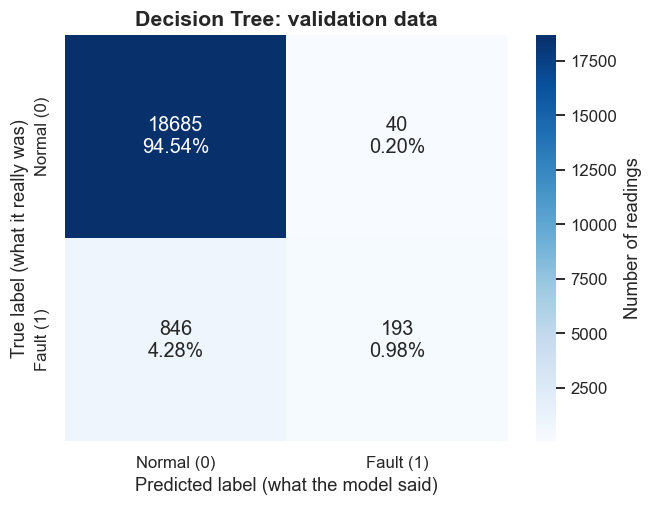

Decision Tree: validation performance


,Accuracy,Recall,Precision,F1
0,0.955171,0.185756,0.828326,0.303459


In [63]:
plot_confusion_matrix(dt_class_model, X_valid, y_valid, title='Decision Tree: validation data')
decision_tree_class_weight_perf_valid = model_performance_classification(dt_class_model, X_valid, y_valid)
print('Decision Tree: validation performance')
decision_tree_class_weight_perf_valid

**Used for:** Checking how well the tree learned the training data, and how well it works on new data it has never seen.

**What it shows:** On the training data the tree is perfect: it got all 1,474 faults and all 90,758 normal readings right. On the validation data it caught only **193 of the 1,039 real faults** (recall 0.19) and missed 846. When it did say "fault", it was right 83% of the time (precision 0.83), with 40 false alarms.

**Hence:** The tree memorised the training data. A perfect score on data it has already seen means little. On new data it misses over 80% of the faults, so this baseline is not good enough for catching faults.

## Model 2: Random Forest classifier
**What it is, in simple words.** A random forest is a crowd of many decision trees (100 by default). Each tree looks at a slightly different piece of the data and gives its own answer. Then they vote, and the majority wins. It is like asking 100 people instead of one.

**Settings.** The same `class_weight='balanced'` and `random_state` as the tree.

In [64]:
rf_class_model = RandomForestClassifier(class_weight='balanced', random_state=RS)
rf_class_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

**Results on the training data.**

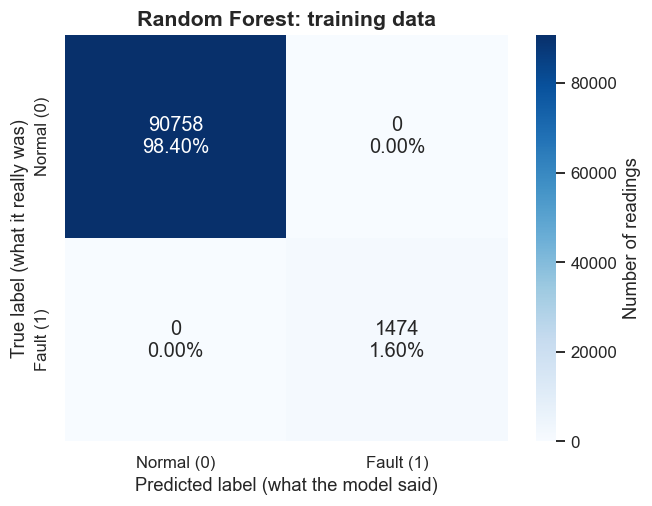

Random Forest: training performance


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


In [65]:
plot_confusion_matrix(rf_class_model, X_train, y_train, title='Random Forest: training data')
random_forest_class_weight_perf_train = model_performance_classification(rf_class_model, X_train, y_train)
print('Random Forest: training performance')
random_forest_class_weight_perf_train

**Results on the validation data.**

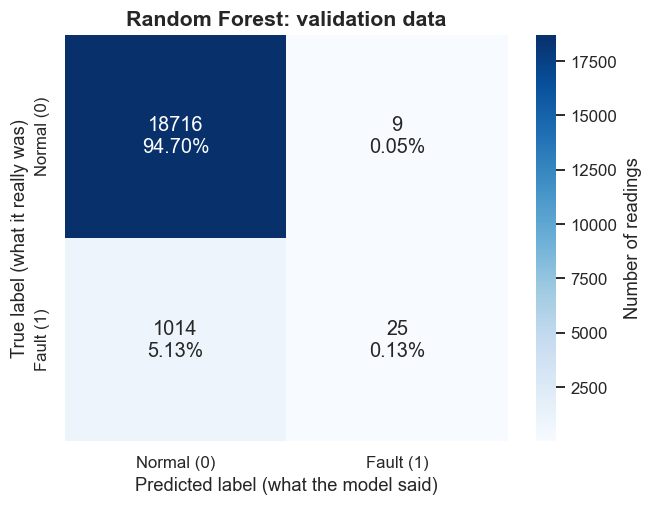

Random Forest: validation performance


,Accuracy,Recall,Precision,F1
0,0.948239,0.024062,0.735294,0.046598


In [66]:
plot_confusion_matrix(rf_class_model, X_valid, y_valid, title='Random Forest: validation data')
random_forest_class_weight_perf_valid = model_performance_classification(rf_class_model, X_valid, y_valid)
print('Random Forest: validation performance')
random_forest_class_weight_perf_valid

**Used for:** Checking how well the forest learned the training data, and how well it works on new data.

**What it shows:** The forest is perfect on the training data again. On the validation data it caught only **25 of the 1,039 faults** (recall 0.02) and raised just 9 false alarms. It almost never says "fault".

**Hence:** Even a crowd of trees memorised the training period. The most likely reason is that faults are rare there (1.6%), so most trees vote "normal" on new data. It is the weakest baseline at catching faults, even though its accuracy (0.95) looks fine.

## Model 3: Gradient Boosting classifier
**What it is, in simple words.** Gradient boosting also uses many small trees, but one after the other instead of all at once. Each new tree tries to fix the mistakes the earlier trees made, like a student who keeps correcting their own homework.

**Settings.** Only the fixed `random_state`. This model has no "balanced" setting in the template, so it is trained on the imbalanced data as it is.

In [67]:
gb_model = GradientBoostingClassifier(random_state=RS)
gb_model.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

**Results on the training data.**

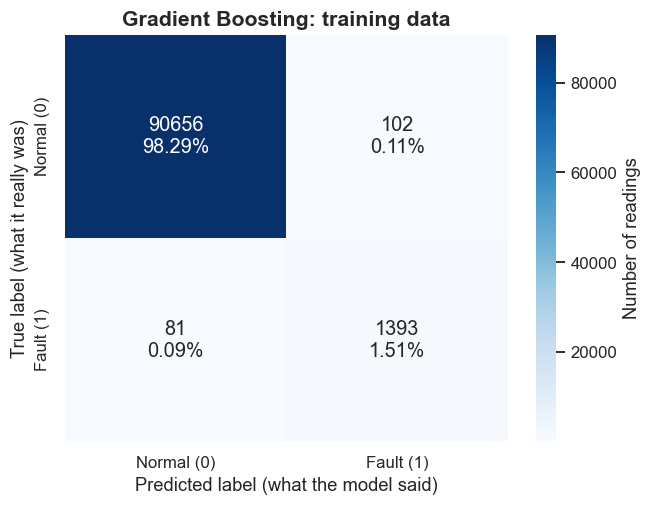

Gradient Boosting: training performance


,Accuracy,Recall,Precision,F1
0,0.998016,0.945047,0.931773,0.938363


In [68]:
plot_confusion_matrix(gb_model, X_train, y_train, title='Gradient Boosting: training data')
gradient_boosting_weight_perf_train = model_performance_classification(gb_model, X_train, y_train)
print('Gradient Boosting: training performance')
gradient_boosting_weight_perf_train

**Results on the validation data.**

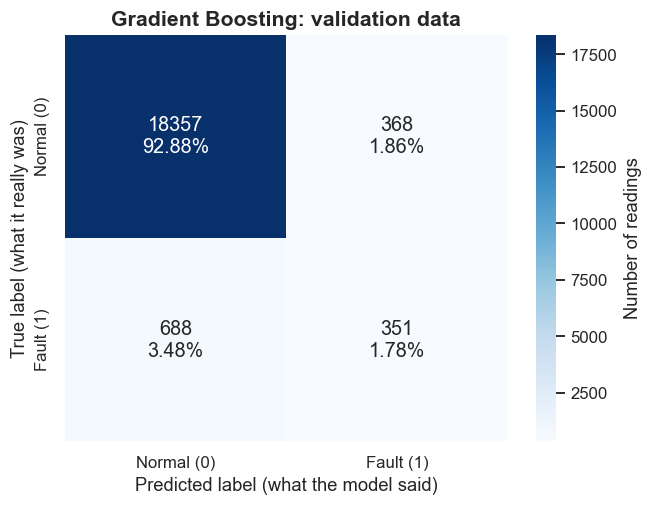

Gradient Boosting: validation performance


,Accuracy,Recall,Precision,F1
0,0.94657,0.337825,0.488178,0.399317


In [69]:
plot_confusion_matrix(gb_model, X_valid, y_valid, title='Gradient Boosting: validation data')
gradient_boosting_weight_perf_valid = model_performance_classification(gb_model, X_valid, y_valid)
print('Gradient Boosting: validation performance')
gradient_boosting_weight_perf_valid

**Used for:** Checking how well the boosted trees learned the training data, and how well they work on new data.

**What it shows:** On the training data it is not perfect: it caught 1,393 of the 1,474 faults (recall 0.95, precision 0.93). On the validation data it caught **351 of the 1,039 faults** (recall 0.34) and raised 368 false alarms (precision 0.49).

**Hence:** It does better than the tree and the forest on new data, but it still misses about two thirds of the faults. It had no "balanced" setting, which may be part of the reason. The drop from 0.95 to 0.34 shows it overfits too.

## Model 4: XGBoost classifier
**What it is, in simple words.** XGBoost is a faster and more careful version of gradient boosting. It uses the same idea (trees that fix each other's mistakes) with extra tricks to keep it from memorising the training data.

**Settings.** `scale_pos_weight` tells it how much more a fault matters. We set it to the number of normal readings divided by the number of fault readings in the training data, which is about 62. First we count them.

In [70]:
neg_count = y_train.value_counts()[0]
pos_count = y_train.value_counts()[1]
scale_pos_weight_value = neg_count / pos_count
print(f"Negative Samples: {neg_count}")
print(f"Positive Samples: {pos_count}")
print(f"Scale Pos Weight (neg/pos): {scale_pos_weight_value:.2f}")

Negative Samples: 90758
Positive Samples: 1474
Scale Pos Weight (neg/pos): 61.57


In [71]:
xgb_class_model = XGBClassifier(scale_pos_weight=scale_pos_weight_value, random_state=RS)
xgb_class_model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

**Results on the training data.**

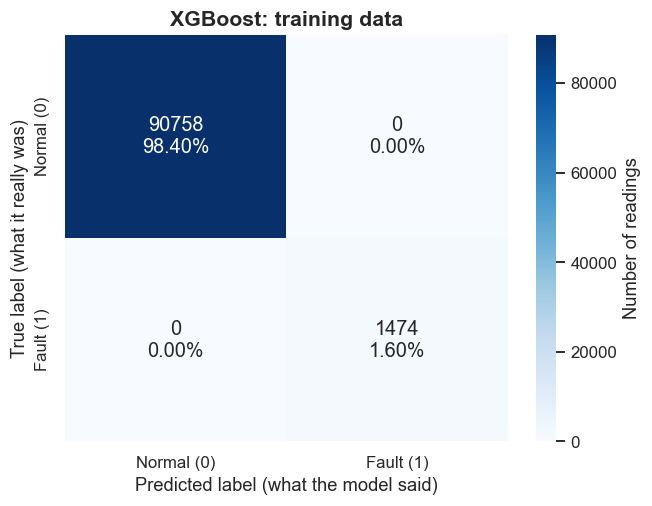

XGBoost: training performance


,Accuracy,Recall,Precision,F1
0,1.0,1.0,1.0,1.0


In [72]:
plot_confusion_matrix(xgb_class_model, X_train, y_train, title='XGBoost: training data')
xgb_class_weight_perf_train = model_performance_classification(xgb_class_model, X_train, y_train)
print('XGBoost: training performance')
xgb_class_weight_perf_train

**Results on the validation data.**

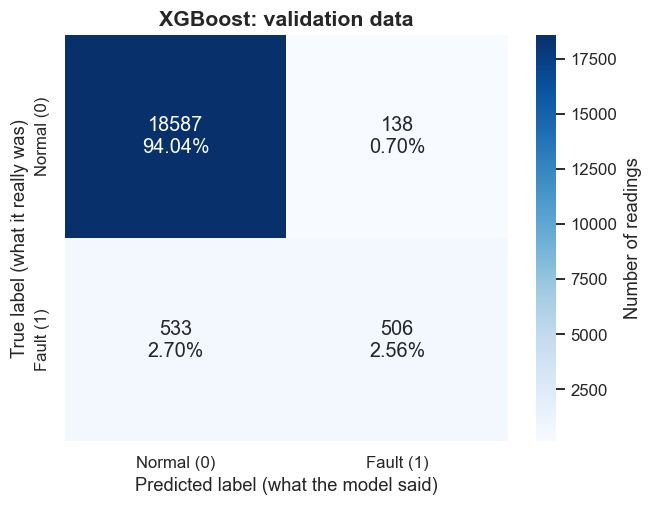

XGBoost: validation performance


,Accuracy,Recall,Precision,F1
0,0.966049,0.487007,0.785714,0.601307


In [73]:
plot_confusion_matrix(xgb_class_model, X_valid, y_valid, title='XGBoost: validation data')
xgb_class_weight_perf_valid = model_performance_classification(xgb_class_model, X_valid, y_valid)
print('XGBoost: validation performance')
xgb_class_weight_perf_valid

**Used for:** Checking how well XGBoost learned the training data, and how well it works on new data.

**What it shows:** It is perfect on the training data. On the validation data it caught **506 of the 1,039 faults** (recall 0.49), missed 533, and raised 138 false alarms (precision 0.79).

**Hence:** This is the best of the tree-based models: it catches about half of the new faults with few false alarms. It still overfits (recall drops from 1.00 to 0.49), so there is room to improve.

## Model 5: Artificial Neural Network (ANN)
**What it is, in simple words.** A neural network is a small web of connected "dials". The readings go in on one side, pass through layers of simple calculators, and one number comes out: the chance that the reading is a fault, from 0 to 1. If that chance is above 0.5, we call it a fault.

This is the plainest version of a neural network: two small hidden layers and one output.

**Step 1: put the columns on the same scale.** The columns are on very different scales (power goes up to thousands, oil pressure is around 6). A neural network gets confused by that, so we rescale every column to a similar size. The scaler learns its numbers from the training data only, and then uses the same numbers on validation and test. (The tree models do not need this.) We also fix the random starting numbers of the network with the same `RS` as before, so that every run gives the same answer.

In [74]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RS)   # a network starts from random numbers; this fixes them so every run gives the same result
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

**Step 2: build the layers.** The first hidden layer has 32 neurons with the `relu` rule (a simple rule that lets positive signals through and blocks negative ones). The second hidden layer has 7 neurons, as in the template. The last layer has one neuron with `sigmoid`, which squeezes the answer into a number between 0 and 1. The summary below lists the layers and the number of dials (parameters) the network has to learn.

In [75]:
# Choose the number of neurons for the first hidden layer between 8 and 128 integer value only
# Fewer neurons (8-32) create a simpler model that trains faster and is less likely to overfit.
# More neurons (64-128) allow the model to learn more complex patterns but increase training time and the risk of overfitting.
# Choose the activation function for the first hidden layer.
# Common choices: 'relu', 'tanh', or 'sigmoid'.
model = Sequential()
model.add(Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)))
model.add(Dense(7, activation='relu'))
model.add(Dense(1, activation='sigmoid'))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           231 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,359 (5.31 KB)

 Trainable params: 1,359 (5.31 KB)

 Non-trainable params: 0 (0.00 B)

**Step 3: choose how it learns.** The template uses the plain `sgd` learning rule: after looking at a small batch of readings, the network nudges its dials a little in the direction that reduces its mistakes. The loss, `binary_crossentropy`, is the usual way to measure mistakes when there are two answers. We also ask it to track recall, precision and accuracy while it trains.

In [76]:
optimizer = 'sgd'
loss = 'binary_crossentropy'
model.compile(loss=loss, optimizer=optimizer, metrics=[tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), tf.keras.metrics.BinaryAccuracy()])

**Step 4: how long to train.** One **epoch** is one full pass over the training data. We use 30 epochs. The **batch size** is how many readings the network looks at before it nudges its dials: we use 64. Both numbers are inside the ranges the template allows.

We also give the network the same kind of help as the tree models: class weights, so that a fault counts for more than a normal reading.

In [77]:
# Choose the number of training epochs between 10 and 100.
# Fewer epochs (10-30) train faster but may underfit the data.
# More epochs (50-100) allow the model to learn more patterns but may increase the risk of overfitting.
epochs = 30

# Choose the batch size between 16 and 128.
# Smaller batch sizes (16-32) can improve generalization but increase training time.
# Larger batch sizes (64-128) train faster but may require more memory and sometimes reduce generalization.
batch_size = 64

weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weight_dict = {i: weights[i] for i in range(len(weights))}
print('Class weights:', class_weight_dict)

Class weights: {0: np.float64(0.508120496264792), 1: np.float64(31.28629579375848)}


**Step 5: train it.** Each line below is one epoch. `recall` and `precision` are for the training data, and the `val_` numbers are for the validation data.

In [78]:
start = time.time()
history = model.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled, y_valid), class_weight=class_weight_dict, batch_size=batch_size, epochs=epochs, verbose=2)
end = time.time()
print("Time taken in seconds ", end - start)

Epoch 1/30
1442/1442 - 1s - 733us/step - binary_accuracy: 0.9374 - loss: 0.1613 - precision: 0.1987 - recall: 0.9613 - val_binary_accuracy: 0.9488 - val_loss: 0.1545 - val_precision: 0.5107 - val_recall: 0.6218
Epoch 2/30
1442/1442 - 1s - 462us/step - binary_accuracy: 0.9732 - loss: 0.0536 - precision: 0.3733 - recall: 0.9986 - val_binary_accuracy: 0.9587 - val_loss: 0.1588 - val_precision: 0.5972 - val_recall: 0.6564
Epoch 3/30
1442/1442 - 1s - 461us/step - binary_accuracy: 0.9767 - loss: 0.0433 - precision: 0.4065 - recall: 1.0000 - val_binary_accuracy: 0.9620 - val_loss: 0.1696 - val_precision: 0.6314 - val_recall: 0.6660
Epoch 4/30
1442/1442 - 1s - 504us/step - binary_accuracy: 0.9789 - loss: 0.0384 - precision: 0.4306 - recall: 1.0000 - val_binary_accuracy: 0.9640 - val_loss: 0.1825 - val_precision: 0.6541 - val_recall: 0.6699
Epoch 5/30
1442/1442 - 1s - 485us/step - binary_accuracy: 0.9807 - loss: 0.0350 - precision: 0.4530 - recall: 1.0000 - val_binary_accuracy: 0.9658 - val_los

**Results on the training data.**

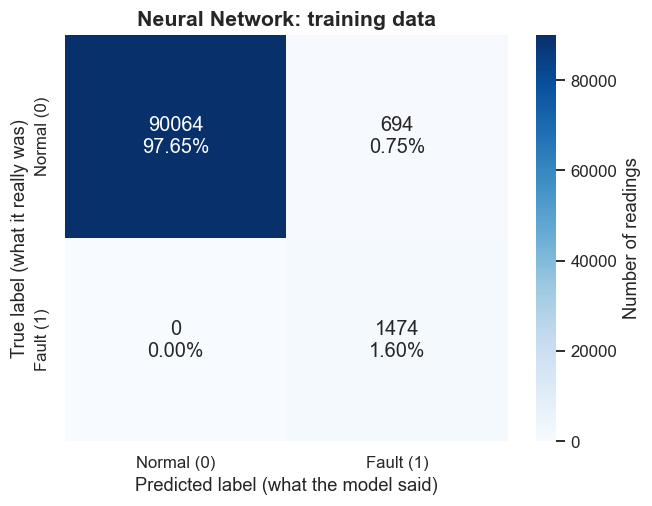

ANN Baseline Training Performance:


,Accuracy,Recall,Precision,F1
0,0.992475,1.0,0.679889,0.809445


In [79]:
plot_confusion_matrix(model, X_train_scaled, y_train, title='Neural Network: training data')
ann_perf_train = model_performance_classification(model, X_train_scaled, y_train)
print("ANN Baseline Training Performance:")
ann_perf_train

**Results on the validation data.**

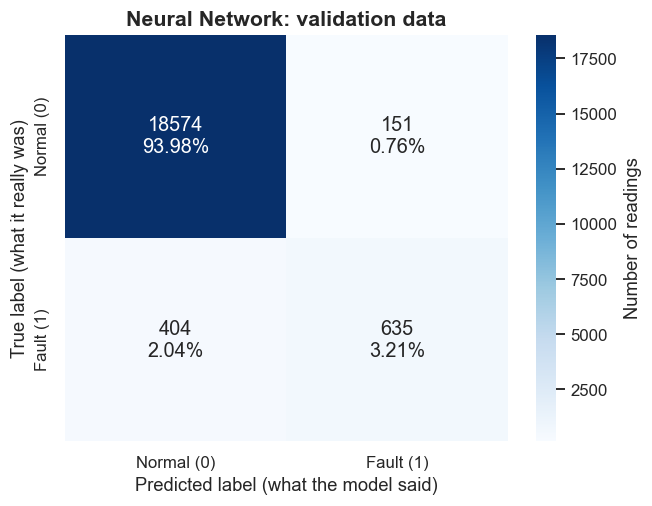


ANN Baseline Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.971919,0.611165,0.807888,0.69589


In [80]:
plot_confusion_matrix(model, X_valid_scaled, y_valid, title='Neural Network: validation data')
ann_perf_valid = model_performance_classification(model, X_valid_scaled, y_valid)
print("\nANN Baseline Validation Performance:")
ann_perf_valid

**Used for:** Checking how well the neural network learned the training data, and how well it works on new data.

**What it shows:** On the training data it caught every fault (recall 1.00) but raised 694 false alarms (precision 0.68). On the validation data it caught **635 of the 1,039 faults** (recall 0.61), missed 404, and raised only 151 false alarms (precision 0.81).

**Hence:** It has the highest recall of the five baselines, and the smallest drop between training and validation. It still overfits a little (1.00 down to 0.61). The numbers can differ slightly on another computer, even with the seed fixed.

## Baseline model performance comparison
Now we put all five models side by side.

### Training performance comparison
This table shows how each model does on the data it learned from.

In [81]:
print("Training performance comparison:")

all_models_train_comp_data = pd.concat([
    decision_tree_class_weight_perf_train.T.rename(columns={0: 'Decision Tree'}),
    random_forest_class_weight_perf_train.T.rename(columns={0: 'Random Forest'}),
    gradient_boosting_weight_perf_train.T.rename(columns={0: 'Gradient Boosting'}),
    xgb_class_weight_perf_train.T.rename(columns={0: 'XGBoost'}),
    ann_perf_train.T.rename(columns={0: 'Neural Network'})
], axis=1)
all_models_train_comp_data.round(4)

Training performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,1.0,1.0,0.9980,1.0,0.9925
Recall,1.0,1.0,0.9450,1.0,1.0000
Precision,1.0,1.0,0.9318,1.0,0.6799
F1,1.0,1.0,0.9384,1.0,0.8094


### Validation performance comparison
This table shows how each model does on new data it has never seen. This is the one that counts.

In [82]:
print("Validation performance comparison:")

all_models_valid_comp_data = pd.concat([
    decision_tree_class_weight_perf_valid.T.rename(columns={0: 'Decision Tree'}),
    random_forest_class_weight_perf_valid.T.rename(columns={0: 'Random Forest'}),
    gradient_boosting_weight_perf_valid.T.rename(columns={0: 'Gradient Boosting'}),
    xgb_class_weight_perf_valid.T.rename(columns={0: 'XGBoost'}),
    ann_perf_valid.T.rename(columns={0: 'Neural Network'})
], axis=1)
all_models_valid_comp_data.round(4)

Validation performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network
Accuracy,0.9552,0.9482,0.9466,0.9660,0.9719
Recall,0.1858,0.0241,0.3378,0.4870,0.6112
Precision,0.8283,0.7353,0.4882,0.7857,0.8079
F1,0.3035,0.0466,0.3993,0.6013,0.6959


This chart shows the recall of every model twice: on the training data (blue) and on the validation data (red). A big drop from blue to red means the model memorised the training data and does not work well on new data. This is called **overfitting**.

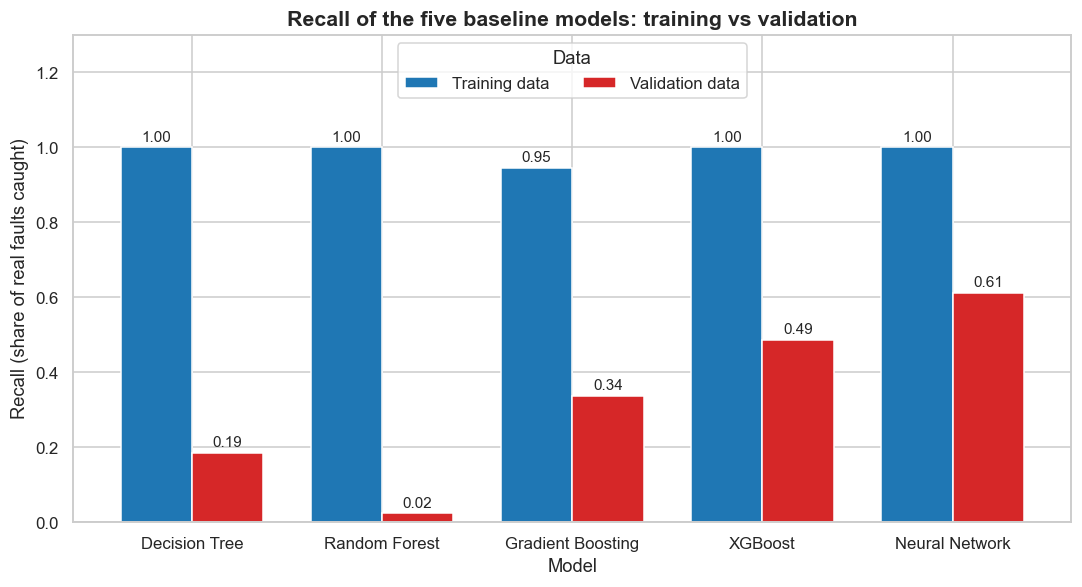

In [83]:
recall_compare = pd.DataFrame({'Training data': all_models_train_comp_data.loc['Recall'],
                               'Validation data': all_models_valid_comp_data.loc['Recall']})

ax = recall_compare.plot(kind='bar', figsize=(10, 5.5), color=['#1F77B4', '#D62728'], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2, fontsize=10)
ax.set_title('Recall of the five baseline models: training vs validation')
ax.set_xlabel('Model')
ax.set_ylabel('Recall (share of real faults caught)')
ax.set_ylim(0, 1.3)
ax.legend(title='Data', loc='upper center', ncol=2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Used for:** Seeing all five models side by side, and checking whether each one still works on new data.

**What it shows:** On the training data, four of the five models score a recall of 1.00 (Gradient Boosting 0.95). On the validation data every model drops: Neural Network **0.61**, XGBoost **0.49**, Gradient Boosting **0.34**, Decision Tree **0.19** and Random Forest **0.02**. The Neural Network also has the best F1 (0.70), with XGBoost second (0.60). Precision on validation is highest for the Decision Tree (0.83), then the Neural Network (0.81) and XGBoost (0.79).

**Hence:** Every baseline overfits: the red bars are much shorter than the blue ones. The Neural Network and XGBoost are the strongest starting points. The Decision Tree, Random Forest and Gradient Boosting miss most of the faults on new data. We will look at all of them again in the tuning section.

## Model evaluation criterion: which score matters most?
We have four scores (accuracy, recall, precision and F1). We have to pick the one that matters most for this business problem. First, a chart that shows why **accuracy** is a poor choice here. It puts accuracy and recall side by side for each model on the validation data.

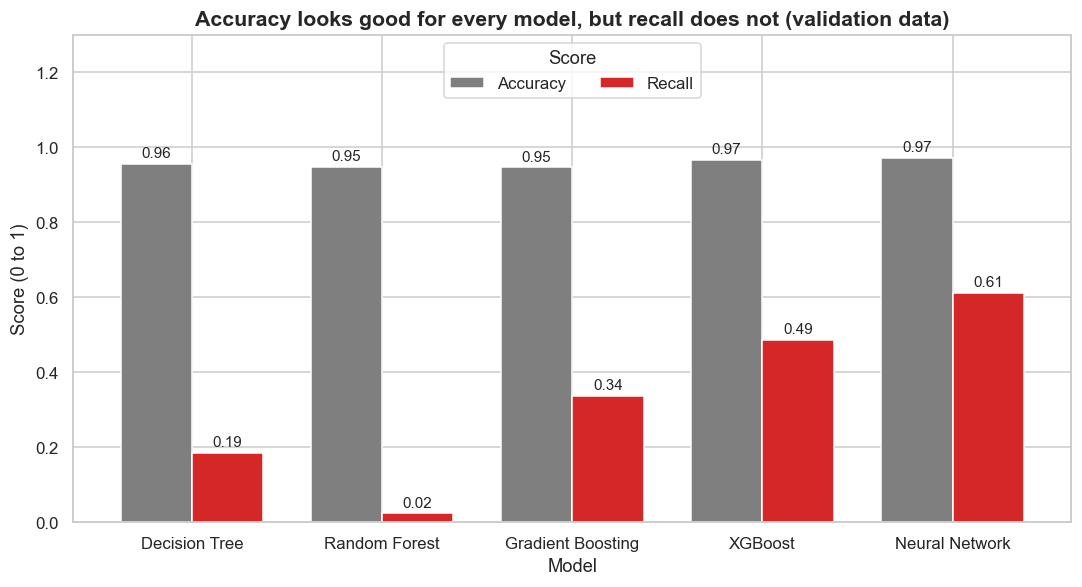

In [84]:
acc_vs_recall = all_models_valid_comp_data.loc[['Accuracy', 'Recall']].T

ax = acc_vs_recall.plot(kind='bar', figsize=(10, 5.5), color=['#7F7F7F', '#D62728'], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2, fontsize=10)
ax.set_title('Accuracy looks good for every model, but recall does not (validation data)')
ax.set_xlabel('Model')
ax.set_ylabel('Score (0 to 1)')
ax.set_ylim(0, 1.3)
ax.legend(title='Score', loc='upper center', ncol=2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Used for:** Showing why accuracy is a poor score for this project.

**What it shows:** Accuracy is between 0.95 and 0.97 for all five models, but recall goes from 0.02 to 0.61. The Random Forest has an accuracy of 0.95 and catches only 25 of the 1,039 faults in the validation data.

**Hence:** Accuracy cannot tell a good model from a useless one here. Recall can.

### The most important metric: recall
**Recall** is the most important score for this project, for these reasons:

- **A missed fault is very expensive.** The turbine keeps running while the bearing wears out. Then it can be offline for 7 to 21 days with no electricity to sell, an emergency crane and rushed parts, and sometimes a destroyed gearbox. This is a false negative, and recall is the score that counts false negatives.
- **A false alarm is cheap.** A technician checks a turbine that was fine. That costs one visit.
- **The project brief says the same thing.** The model should be "deliberately tuned to favour catching true failures over avoiding false alerts".
- **Accuracy would fool us.** Only 3% of readings are faults, so a model that says "normal" every time scores about 97% accuracy and catches nothing. The chart above shows models with high accuracy and low recall.

**Precision** and **F1** still matter as a second check. If the model sounds the alarm far too often, the technicians will stop trusting it. So we choose models by recall first, and look at precision to make sure the false alarms stay at a level the team can handle.

The next cell saves our choice, which the tuning section uses to decide what counts as "better".

In [85]:
# Uncomment one of the following evaluation metrics

# metric_of_choice = 'accuracy'
# metric_of_choice = 'precision'
metric_of_choice = 'recall'
# metric_of_choice = 'f1'

print('Metric we will use to choose and tune the models:', metric_of_choice)

Metric we will use to choose and tune the models: recall


# **Hyperparameter Tuning**

**What is tuning?** Every model has settings that we choose before it starts learning, such as how deep a tree can grow or how many neurons a layer has. These are called **hyperparameters**. Think of them as the dials on a radio: the baseline models used the default dials, and tuning is the search for a better setting.

**How we search.**
- **Random search** tries a random sample of dial combinations, instead of every possible one (there are far too many). We choose how many to try with `n_iter`.
- **5-fold cross-validation** gives each combination an honest score. The training data is cut into 5 parts. The model learns on 4 parts and is checked on the 5th, and this is repeated until each part has been the "check" part once. The 5 scores are averaged.
- Every combination is scored on **recall**, our primary metric from the previous section.

**The plan for this section**
1. Choose the two best baseline models, and say why.
2. Tune them.
3. Check the tuned models: did recall improve compared to the baseline, and did overfitting go up or down?

### Before you start
The tuning below needs the baseline models and their results from the Model Building section. The cell below checks that they exist. If something is missing, run the cells above first (menu: **Run > Run All Above Selected Cell**).

In [86]:
needed = ['all_models_train_comp_data', 'all_models_valid_comp_data', 'xgb_class_model', 'X_train_scaled', 'class_weight_dict', 'metric_of_choice']
missing = [name for name in needed if name not in globals()]
if missing:
    raise RuntimeError(f"Not ready yet. These are missing: {missing}. "
                       "Run the whole Model Building section first (menu: Run > Run All Above Selected Cell).")
print('Ready: the baseline models and their results exist. The metric we tune for is:', metric_of_choice)

Ready: the baseline models and their results exist. The metric we tune for is: recall


## Choosing the two models to tune
We choose with the **validation results** of the five baselines, because those are scores on data the models had not seen. The rule:

1. The main test is **validation recall**, our primary metric.
2. Precision and F1 are a second check, so we do not pick a model that sounds the alarm all the time.
3. The **recall drop** (training recall minus validation recall) tells us how much the model overfits.

The next cell lines the five models up, best recall first. The chart shows the same thing, with the two chosen models in red.

,Validation recall,Validation precision,Validation F1,Recall drop (train - validation)
Neural Network,0.611,0.808,0.696,0.389
XGBoost,0.487,0.786,0.601,0.513
Gradient Boosting,0.338,0.488,0.399,0.607
Decision Tree,0.186,0.828,0.303,0.814
Random Forest,0.024,0.735,0.047,0.976


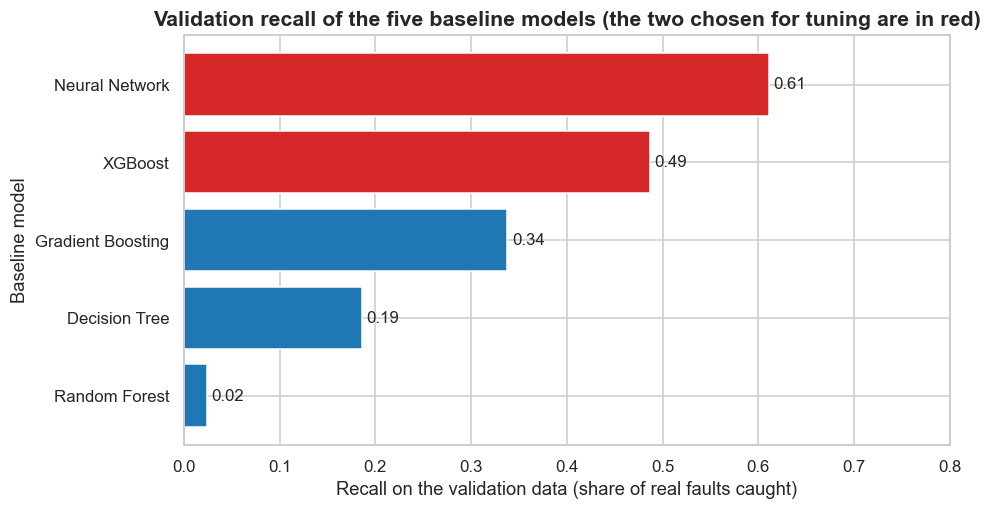

Models chosen for tuning: ['Neural Network', 'XGBoost']


In [87]:
ranking = pd.DataFrame({
    'Validation recall': all_models_valid_comp_data.loc['Recall'],
    'Validation precision': all_models_valid_comp_data.loc['Precision'],
    'Validation F1': all_models_valid_comp_data.loc['F1'],
    'Recall drop (train - validation)': all_models_train_comp_data.loc['Recall'] - all_models_valid_comp_data.loc['Recall']
}).sort_values('Validation recall', ascending=False)
display(ranking.round(3))

top_two = ranking.index[:2].tolist()
colors = ['#D62728' if m in top_two else '#1F77B4' for m in ranking.index]

plt.figure(figsize=(9, 4.8))
bars = plt.barh(ranking.index[::-1], ranking['Validation recall'][::-1], color=colors[::-1])
plt.bar_label(bars, fmt='%.2f', padding=3, fontsize=11)
plt.title('Validation recall of the five baseline models (the two chosen for tuning are in red)')
plt.xlabel('Recall on the validation data (share of real faults caught)')
plt.ylabel('Baseline model')
plt.xlim(0, 0.8)
plt.tight_layout()
plt.show()
print('Models chosen for tuning:', top_two)

**Used for:** Choosing which two baseline models to tune.

**What it shows:** The **Neural Network** has the highest validation recall (0.61), followed by **XGBoost** (0.49). Gradient Boosting (0.34), the Decision Tree (0.19) and the Random Forest (0.02) are far behind. The two leaders also keep good precision (0.81 and 0.79) and have the smallest recall drops (0.39 and 0.51).

**Hence:** We tune the Neural Network and XGBoost. They catch the most faults on new data, which is what we care about most, and they do it without a flood of false alarms. The Decision Tree has high precision (0.83) but misses over 80% of the faults. Gradient Boosting has the lowest precision of the five (0.49) and still catches few faults.

## Tuning model 1: XGBoost
**The dials we will search.** The template lists these settings for XGBoost. In simple words:

- `n_estimators`: how many trees it builds.
- `learning_rate`: how big a step each new tree takes. Small steps are slower but more careful.
- `max_depth`: how many questions deep each tree may go. Deep trees memorise more.
- `min_child_weight`: how much evidence a branch needs before the tree splits it. Higher is more cautious.
- `gamma`: how much a split must improve things to be worth making.
- `subsample`: the share of the readings each tree gets to look at.
- `colsample_bytree`: the share of the columns each tree gets to look at.
- `reg_alpha` and `reg_lambda`: penalties that keep the model simple.

The cell below lists the values we let the search choose from for each dial.

In [88]:
param_grid = {
    'n_estimators': [50, 100, 200, 300],          # Number of trees. Smaller values (50-100) train faster but may underfit. Larger values (100-300) improve learning but increase training time.
    'learning_rate': [0.01, 0.05, 0.1],       # Step size for learning. Smaller values (0.01-0.05) learn gradually and need more trees. Larger values (0.1-0.3) learn faster but may overshoot.
    'max_depth': [3, 5, 7],              # Maximum tree depth. Smaller values (3-5) reduce overfitting. Larger values (6-10) capture more complex patterns but may overfit.
    'min_child_weight': [1, 5, 10],       # Minimum weight required for a split. Smaller values (1-3) create more complex trees. Larger values (5-10) make the model more conservative.
    'gamma': [0, 0.1, 0.5],             # Minimum loss reduction for a split. Smaller values (0-0.1) allow more splits. Larger values (0.3-1) reduce unnecessary splits.
    'subsample': [0.7, 0.8, 1.0],            # Fraction of training samples per tree. Smaller values (0.6-0.8) improve generalization. Larger values (0.9-1.0) use more data but may overfit.
    'colsample_bytree': [0.4, 0.7, 1.0],     # Fraction of features per tree. Smaller values (0.4-0.7) increase tree diversity. Larger values (0.8-1.0) use more features and may improve fit.
    'reg_alpha': [0, 0.001, 0.01, 0.1],       # L1 regularization. Smaller values (0-0.001) apply little regularization. Larger values (0.01-0.1) reduce overfitting by encouraging sparsity.
    'reg_lambda': [0.1, 1, 5]            # L2 regularization. Smaller values (0.1-1) apply light regularization. Larger values (5-10) provide stronger regularization.
}
n_combinations = int(np.prod([len(v) for v in param_grid.values()]))
print(f'Number of possible combinations: {n_combinations:,}')

Number of possible combinations: 34,992


**Run the search.** We try `n_iter = 30` random combinations out of all the possible ones. Each is scored with 5-fold cross-validation, so that is 150 training runs in total. The score is recall.

In [89]:
# Choose the number of random hyperparameter combinations to evaluate.
# Smaller values (10-20) complete faster but explore fewer parameter combinations.
# Larger values (30-50) explore a wider search space and may find better hyperparameters but increase tuning time.
n_iter = 30

xgb_randomized_cv = RandomizedSearchCV(estimator=xgb_class_model, param_distributions=param_grid, n_iter=n_iter, n_jobs=-1, scoring=metric_of_choice, cv=5, random_state=1)

xgb_randomized_cv.fit(X_train, y_train)

print("Best parameters are {} with CV score={}:".format(xgb_randomized_cv.best_params_, xgb_randomized_cv.best_score_))

Best parameters are {'subsample': 0.8, 'reg_lambda': 0.1, 'reg_alpha': 0, 'n_estimators': 100, 'min_child_weight': 1, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0.5, 'colsample_bytree': 0.4} with CV score=0.6898650985818056:


**Used for:** Finding the best XGBoost settings.

**What it shows:** There were 34,992 possible combinations and we tried 30 of them. The best one is careful and simple: shallow trees (`max_depth` of 3), small learning steps (`learning_rate` of 0.01), 100 trees, and each tree sees only 40% of the columns (`colsample_bytree` of 0.4). Its cross-validation recall is 0.69.

**Hence:** The search prefers cautious settings that stop the trees from memorising the training data. We compare it properly with the baseline in the checks below.

**Train the best version.** We take the best combination, train it on the full training data, and look at its results on the training and the validation data.

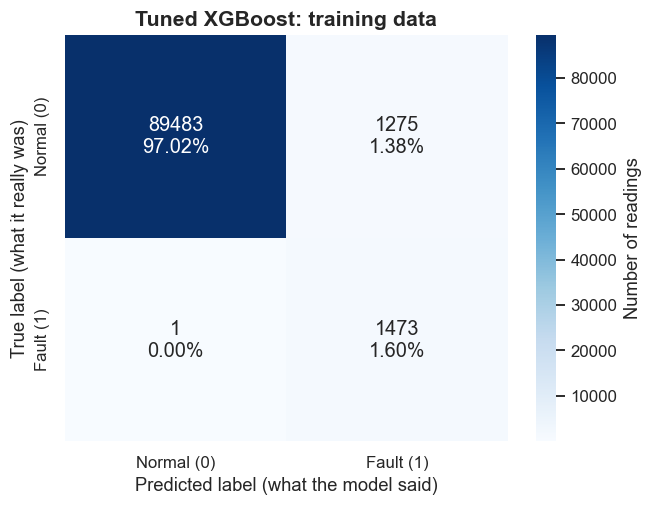

Tuned XGBoost: training performance


,Accuracy,Recall,Precision,F1
0,0.986165,0.999322,0.536026,0.697774


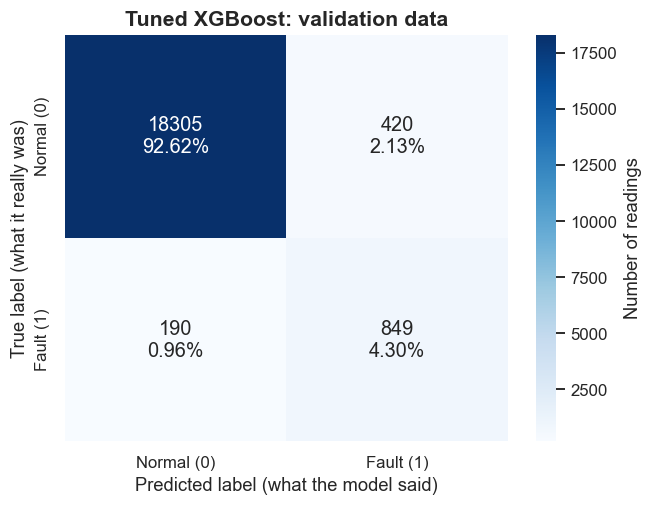

Tuned XGBoost: validation performance


,Accuracy,Recall,Precision,F1
0,0.969136,0.817132,0.669031,0.735702


In [90]:
tuned_xgb = xgb_randomized_cv.best_estimator_
tuned_xgb.fit(X_train, y_train)

plot_confusion_matrix(tuned_xgb, X_train, y_train, title='Tuned XGBoost: training data')
xgb_tuned_perf_train = model_performance_classification(tuned_xgb, X_train, y_train)
print('Tuned XGBoost: training performance')
display(xgb_tuned_perf_train)

plot_confusion_matrix(tuned_xgb, X_valid, y_valid, title='Tuned XGBoost: validation data')
xgb_tuned_perf_valid = model_performance_classification(tuned_xgb, X_valid, y_valid)
print('Tuned XGBoost: validation performance')
xgb_tuned_perf_valid

**Used for:** Checking the tuned XGBoost on the training data and on new data.

**What it shows:** On the training data it caught 1,473 of the 1,474 faults (recall 1.00, precision 0.54). On the validation data it caught **849 of the 1,039 faults** (recall 0.82, up from 0.49), missed 190 (down from 533), and raised 420 false alarms (precision 0.67, down from 0.79). F1 went up from 0.60 to 0.74.

**Hence:** Tuning helped a lot on the score we care about. The model now catches 343 more faults than the baseline (849 instead of 506), at the price of 282 more false alarms (420 instead of 138). Because a missed fault costs far more than a check, that is a good trade.

## Tuning model 2: Neural Network
For the neural network we do not run a random search. The template asks us to choose a better set of layers and training settings by hand. Compared with the baseline, we make three changes:

- **Bigger layers:** 128 neurons in the first layer and 64 in the second, so the network can learn more detail.
- **Batch normalization** after each layer. It keeps the numbers passing through the network on a steady scale, which makes training smoother.
- **Dropout** after each layer. While it trains, the network switches off a random 30% of the neurons each step. That stops it from leaning on a few neurons and memorising the training data, so it is a direct tool against overfitting.

We keep the same plain `sgd` learning rule as the baseline. That way, any change in the results comes from the layers and settings, and not from a different learning rule. We also train for 40 epochs instead of 30.

In [91]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(RS)   # same fixed seed as the baseline, so the run can be repeated

In [92]:
model1 = Sequential()
# Hidden layer 1: 128 neurons (allowed range 32-256), relu, then batch normalization and dropout
model1.add(Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)))
model1.add(BatchNormalization())
# Dropout rate between 0.2 and 0.5: we use 0.3, a middle choice
model1.add(Dropout(0.3))
# Hidden layer 2: 64 neurons (allowed range 16-128), relu, then batch normalization and dropout
model1.add(Dense(64, activation='relu'))
model1.add(BatchNormalization())
model1.add(Dropout(0.3))
# Output layer: one neuron, sigmoid, gives the chance of a fault (0 to 1)
model1.add(Dense(1, activation='sigmoid'))

model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,569 (53.00 KB)

 Trainable params: 13,185 (51.50 KB)

 Non-trainable params: 384 (1.50 KB)

In [93]:
# Uncomment one of the following optimizers.
# optimizer = 'adam'
optimizer = 'sgd'      # same plain learning rule as the baseline network

loss = 'binary_crossentropy'
model1.compile(loss=loss, optimizer=optimizer, metrics=[tf.keras.metrics.Recall(), tf.keras.metrics.Precision(), tf.keras.metrics.BinaryAccuracy()])

# Choose the number of training epochs between 20 and 150.
epochs = 40
# Choose the batch size between 16 and 128.
batch_size = 64

**Train the tuned network.** It uses the same class weights as the baseline, so a fault still counts for more than a normal reading.

In [94]:
start = time.time()
history = model1.fit(X_train_scaled, y_train, validation_data=(X_valid_scaled, y_valid), class_weight=class_weight_dict, batch_size=batch_size, epochs=epochs, verbose=2)
end = time.time()
print("Time taken in seconds ", end - start)

Epoch 1/40
1442/1442 - 2s - 1ms/step - binary_accuracy: 0.8893 - loss: 0.2038 - precision: 0.1245 - recall: 0.9824 - val_binary_accuracy: 0.8955 - val_loss: 0.5883 - val_precision: 0.3347 - val_recall: 1.0000
Epoch 2/40
1442/1442 - 1s - 657us/step - binary_accuracy: 0.9626 - loss: 0.0989 - precision: 0.2981 - recall: 0.9871 - val_binary_accuracy: 0.9080 - val_loss: 0.4896 - val_precision: 0.3637 - val_recall: 1.0000
Epoch 3/40
1442/1442 - 1s - 649us/step - binary_accuracy: 0.9689 - loss: 0.0795 - precision: 0.3380 - recall: 0.9898 - val_binary_accuracy: 0.9164 - val_loss: 0.4420 - val_precision: 0.3851 - val_recall: 0.9904
Epoch 4/40
1442/1442 - 1s - 652us/step - binary_accuracy: 0.9738 - loss: 0.0667 - precision: 0.3777 - recall: 0.9925 - val_binary_accuracy: 0.9117 - val_loss: 0.5099 - val_precision: 0.3730 - val_recall: 0.9990
Epoch 5/40
1442/1442 - 1s - 639us/step - binary_accuracy: 0.9752 - loss: 0.0641 - precision: 0.3914 - recall: 0.9912 - val_binary_accuracy: 0.9134 - val_loss:

**Results on the training and validation data.**

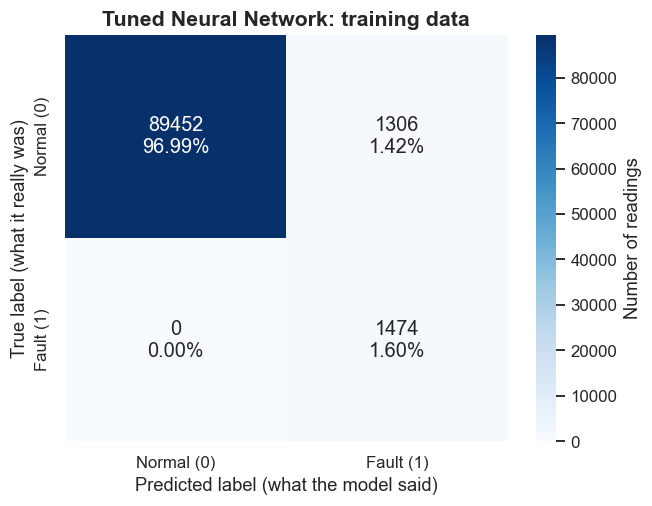

ANN Tuned Training Performance:


,Accuracy,Recall,Precision,F1
0,0.98584,1.0,0.530216,0.692995


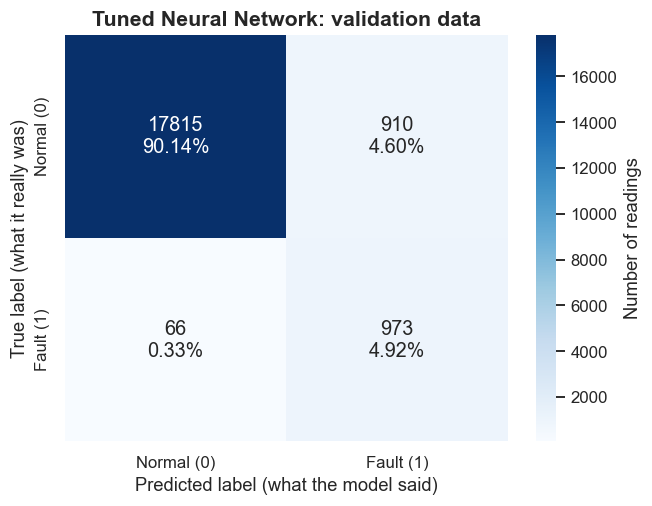


ANN Tuned Validation Performance:


,Accuracy,Recall,Precision,F1
0,0.950617,0.936477,0.516729,0.665982


In [95]:
plot_confusion_matrix(model1, X_train_scaled, y_train, title='Tuned Neural Network: training data')
ann_tuned_perf_train = model_performance_classification(model1, X_train_scaled, y_train)
print("ANN Tuned Training Performance:")
display(ann_tuned_perf_train)

plot_confusion_matrix(model1, X_valid_scaled, y_valid, title='Tuned Neural Network: validation data')
ann_tuned_perf_valid = model_performance_classification(model1, X_valid_scaled, y_valid)
print("\nANN Tuned Validation Performance:")
ann_tuned_perf_valid

**Used for:** Checking the tuned neural network on the training data and on new data.

**What it shows:** On the training data it caught every fault (recall 1.00) with 1,306 false alarms. On the validation data it caught **973 of the 1,039 faults** (recall 0.94, up from 0.61) and missed only 66 (down from 404). It raised 910 false alarms (precision 0.52, down from 0.81). F1 is 0.67, a little below the baseline's 0.70.

**Hence:** The network now catches almost every fault on new data. The price is more false alarms: roughly one false alarm for every real fault it catches, against 151 false alarms before. A missed fault costs more than a check, so this is a fair trade, but the technicians would have more checks to do. The numbers can differ slightly on another computer.

## Checking the tuned models
Now we answer the two questions for each model:

1. **Did recall improve** compared to the baseline?
2. **Did overfitting go up or down?** We measure overfitting as the **recall drop**: training recall minus validation recall. A big drop means the model memorised the training data. A smaller drop means it works more like it did in training.

This table puts the baseline and tuned versions of the two models side by side.

In [96]:
compare_models = {
    'XGBoost (baseline)': (all_models_train_comp_data['XGBoost'], all_models_valid_comp_data['XGBoost']),
    'XGBoost (tuned)': (xgb_tuned_perf_train.T[0], xgb_tuned_perf_valid.T[0]),
    'Neural Network (baseline)': (all_models_train_comp_data['Neural Network'], all_models_valid_comp_data['Neural Network']),
    'Neural Network (tuned)': (ann_tuned_perf_train.T[0], ann_tuned_perf_valid.T[0]),
}

tuned_check = pd.DataFrame({
    name: {'Training recall': tr['Recall'], 'Validation recall': va['Recall'],
           'Recall drop (overfitting)': tr['Recall'] - va['Recall'],
           'Validation precision': va['Precision'], 'Validation F1': va['F1'],
           'Validation accuracy': va['Accuracy']}
    for name, (tr, va) in compare_models.items()}).T
tuned_check.round(3)

,Training recall,Validation recall,Recall drop (overfitting),Validation precision,Validation F1,Validation accuracy
XGBoost (baseline),1.000,0.487,0.513,0.786,0.601,0.966
XGBoost (tuned),0.999,0.817,0.182,0.669,0.736,0.969
Neural Network (baseline),1.000,0.611,0.389,0.808,0.696,0.972
Neural Network (tuned),1.000,0.936,0.064,0.517,0.666,0.951


**Used for:** Putting the baseline and tuned versions of both models side by side.

**What it shows:** Validation recall: XGBoost 0.49 to **0.82**, Neural Network 0.61 to **0.94**. Recall drop (overfitting): XGBoost 0.51 to **0.18**, Neural Network 0.39 to **0.06**. Precision fell for both: XGBoost 0.79 to 0.67 and Neural Network 0.81 to 0.52. F1 rose for XGBoost (0.60 to 0.74) and dipped for the Neural Network (0.70 to 0.67).

**Hence:** Both models improved on the primary metric, and both overfit less. The cost is lower precision, which means more false alarms.

This chart shows the recall of the four models on the training data (blue) and on the validation data (red). The gap between the two bars is the overfitting.

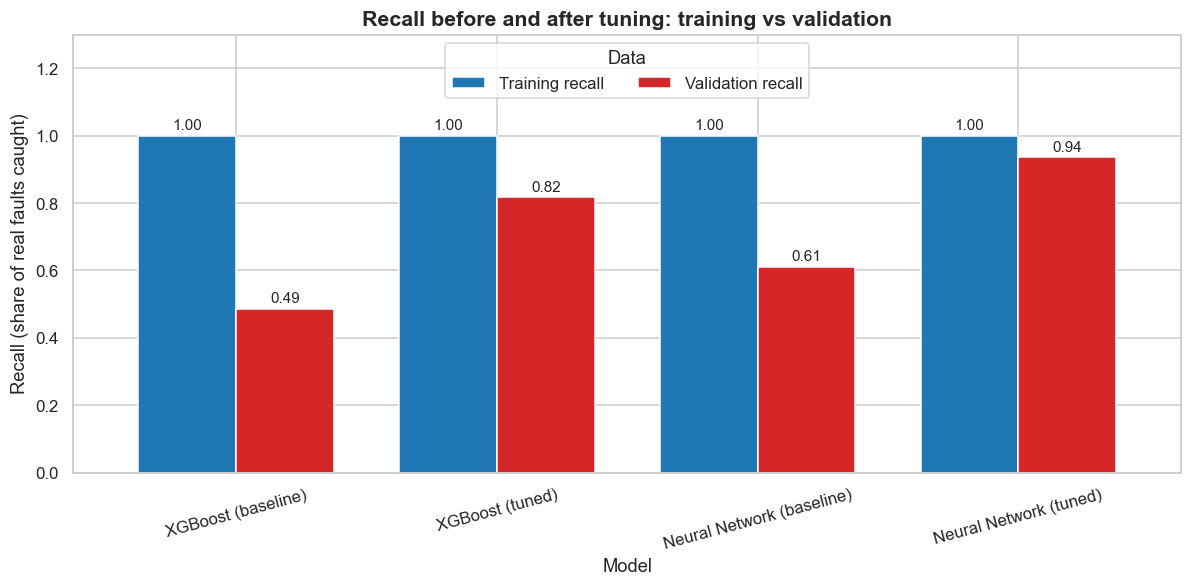

In [97]:
recall_pairs = tuned_check[['Training recall', 'Validation recall']]

ax = recall_pairs.plot(kind='bar', figsize=(11, 5.5), color=['#1F77B4', '#D62728'], width=0.75)
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2, fontsize=10)
ax.set_title('Recall before and after tuning: training vs validation')
ax.set_xlabel('Model')
ax.set_ylabel('Recall (share of real faults caught)')
ax.set_ylim(0, 1.3)
ax.legend(title='Data', loc='upper center', ncol=2)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Used for:** Seeing overfitting as the gap between the blue and the red bar.

**What it shows:** For the baselines, the red bars (validation) are far shorter than the blue bars (training). After tuning, the red bars are much closer to the blue ones: 0.82 for XGBoost and 0.94 for the Neural Network.

**Hence:** The tuned models keep much more of their training skill when they meet new data.

This chart shows only the overfitting, the recall drop, for each model before and after tuning. A shorter bar is better.

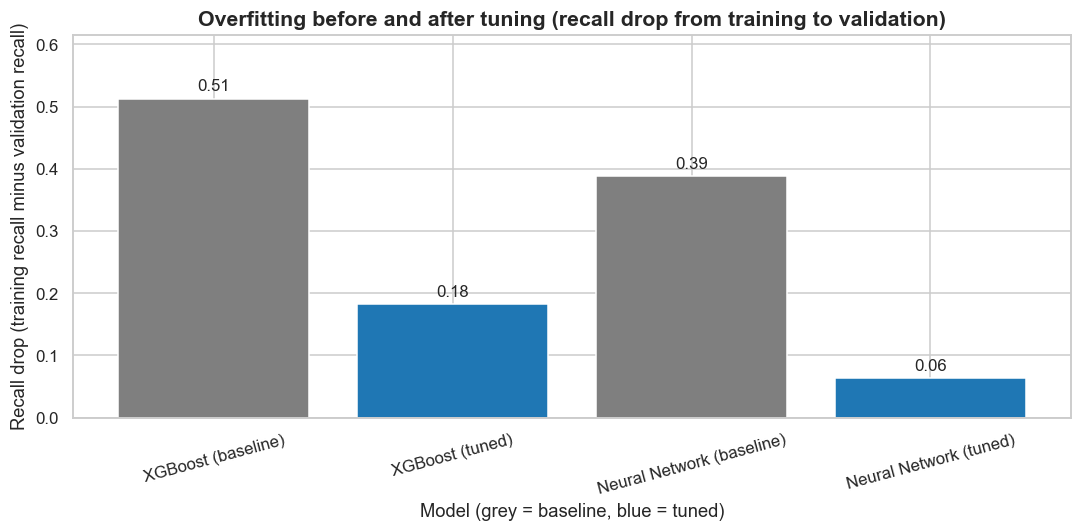

In [98]:
gap = tuned_check['Recall drop (overfitting)']

plt.figure(figsize=(10, 5))
bars = plt.bar(gap.index, gap.values, color=['#7F7F7F', '#1F77B4', '#7F7F7F', '#1F77B4'])
plt.bar_label(bars, fmt='%.2f', padding=3, fontsize=11)
plt.title('Overfitting before and after tuning (recall drop from training to validation)')
plt.xlabel('Model (grey = baseline, blue = tuned)')
plt.ylabel('Recall drop (training recall minus validation recall)')
plt.ylim(0, max(gap.values) * 1.2)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Used for:** Measuring overfitting directly, as the recall drop from training to validation.

**What it shows:** The drop went from 0.51 to 0.18 for XGBoost, and from 0.39 to 0.06 for the Neural Network. The grey bars (baseline) are tall and the blue bars (tuned) are short.

**Hence:** Tuning reduced overfitting for both models. The tuned Neural Network overfits the least.

### Answers to the two questions

**1. Did the primary metric (recall) improve after tuning?** Yes, for both models. On the validation data, XGBoost went from 0.49 to 0.82 and the Neural Network from 0.61 to 0.94.

**2. Did tuning increase or reduce overfitting?** It reduced it for both. The recall drop shrank from 0.51 to 0.18 for XGBoost and from 0.39 to 0.06 for the Neural Network.

**What we gave up.** Precision fell: XGBoost from 0.79 to 0.67 and the Neural Network from 0.81 to 0.52. That means more false alarms. We accept this, because a missed fault costs much more than an extra inspection, which is why we chose recall in the first place.

**Which model looks better so far?** The tuned Neural Network catches the most faults (recall 0.94) but has the most false alarms (precision 0.52). The tuned XGBoost catches fewer (0.82) but is better balanced (F1 0.74 against 0.67). We make the final choice in the next section, and only then look at the test data.

# **Model Performance and Final Model Selection**

The below code displays the training and validation performance comparison of the original models along with the tuned models.

These two tables add the tuned models to the baseline results, so all seven models can be compared in one place. We only tuned the two best baselines, so the Decision Tree, Random Forest and Gradient Boosting lines stay switched off.

In [99]:
print("Training performance comparison:")

# Uncomment the chosen tuned models to evaluate whether hyperparameter tuning improved
# the training performance compared to the original models.

all_models_train_comp_data = pd.concat([
    all_models_train_comp_data,
    xgb_tuned_perf_train.T.rename(columns={0: 'XGBoost (Tuned)'}),
    ann_tuned_perf_train.T.rename(columns={0: 'Neural Network (Tuned)'}),
    # dt_tuned_perf_train.T.rename(columns={0: 'Decision Tree (Tuned)'}),      # not tuned (we tuned the two best models only)
    # rf_tuned_perf_train.T.rename(columns={0: 'Random Forest (Tuned)'}),      # not tuned
    # gb_tuned_perf_train.T.rename(columns={0: 'Gradient Boosting (Tuned)'})  # not tuned
], axis=1)
all_models_train_comp_data.round(4)

Training performance comparison:


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network,XGBoost (Tuned),Neural Network (Tuned)
Accuracy,1.0,1.0,0.9980,1.0,0.9925,0.9862,0.9858
Recall,1.0,1.0,0.9450,1.0,1.0000,0.9993,1.0000
Precision,1.0,1.0,0.9318,1.0,0.6799,0.5360,0.5302
F1,1.0,1.0,0.9384,1.0,0.8094,0.6978,0.6930


In [100]:
print("Validation performance comparison")

# Uncomment the chosen tuned models to evaluate whether hyperparameter tuning improved
# the validation performance compared to the original models.

all_models_valid_comp_data = pd.concat([
    all_models_valid_comp_data,
    xgb_tuned_perf_valid.T.rename(columns={0: 'XGBoost (Tuned)'}),
    ann_tuned_perf_valid.T.rename(columns={0: 'Neural Network (Tuned)'}),
    # dt_tuned_perf_valid.T.rename(columns={0: 'Decision Tree (Tuned)'}),      # not tuned
    # rf_tuned_perf_valid.T.rename(columns={0: 'Random Forest (Tuned)'}),      # not tuned
    # gb_tuned_perf_valid.T.rename(columns={0: 'Gradient Boosting (Tuned)'})  # not tuned
], axis=1)
all_models_valid_comp_data.round(4)

Validation performance comparison


,Decision Tree,Random Forest,Gradient Boosting,XGBoost,Neural Network,XGBoost (Tuned),Neural Network (Tuned)
Accuracy,0.9552,0.9482,0.9466,0.9660,0.9719,0.9691,0.9506
Recall,0.1858,0.0241,0.3378,0.4870,0.6112,0.8171,0.9365
Precision,0.8283,0.7353,0.4882,0.7857,0.8079,0.6690,0.5167
F1,0.3035,0.0466,0.3993,0.6013,0.6959,0.7357,0.6660


**Used for:** Comparing all seven models (five baselines and two tuned) in one place.

**What it shows:** The tuned Neural Network has the highest validation recall (0.94), then the tuned XGBoost (0.82). The best baseline was the Neural Network at 0.61. The tuned XGBoost has the best F1 (0.74).

**Hence:** Tuning gave the two biggest gains, and the tuned Neural Network catches the most faults, so it is our final model.

**Choosing the final model.** Recall is our primary metric, so we choose the model with the highest recall on the validation data: the **Tuned Neural Network** (0.94, against 0.82 for the tuned XGBoost). Its precision is lower (0.52), which means more false alarms, but a missed fault costs far more than an extra inspection. It also overfits the least (recall drop 0.06).

In [101]:
# Uncomment the best-performing baseline or tuned model based on the evaluation metric of your choice.

# Decision Tree
# best_model = dt_class_model
# Random Forest
# best_model = rf_class_model
# Gradient Boosting
# best_model = gb_model
# XGBoost
# best_model = xgb_class_model
# Neural Network
# best_model = model
# XGBoost (Tuned)
# best_model = tuned_xgb

# Neural Network (Tuned)   <- chosen: highest validation recall (0.94)
best_model = model1

# The network learned from the scaled data, so it must always be given the scaled data
best_X_train, best_X_valid, best_X_test = X_train_scaled, X_valid_scaled, X_test_scaled
print('Final model: Tuned Neural Network')

Final model: Tuned Neural Network


## Final Model Test Performance

**The final check on the test data.** The test data is the newest 15% of readings (21 February to 1 March 2024). No model has seen it, and we did not use it to choose anything. These scores are our best guess of how the model would do in real use.

**We test the model here, we do not train it here.** The model learned only from the training data. The test data is like an exam paper: if the model studied it first, a good score would mean nothing. So the test data is used once, at the very end, just to mark the model. We do this before looking at feature importance, so we first know how good the final model is, and then look at what it relies on.

In [102]:
test_perf = model_performance_classification(best_model, best_X_test, y_test)
print('Final model (Tuned Neural Network): test performance')
test_perf

Final model (Tuned Neural Network): test performance


,Accuracy,Recall,Precision,F1
0,0.939638,0.764583,0.563171,0.648601


This chart shows the four boxes for the test data: faults caught, faults missed, false alarms and correct "normal" answers.

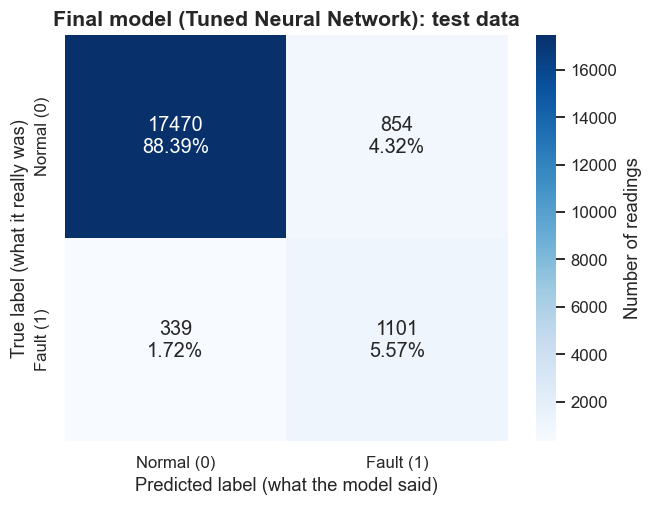

In [103]:
plot_confusion_matrix(best_model, best_X_test, y_test, title='Final model (Tuned Neural Network): test data')

**Used for:** Getting an honest estimate of how the final model would do on future data.

**What it shows:** On the test data the model caught **1,101 of the 1,440 faults** (recall 0.76) and missed 339. It raised 854 false alarms (precision 0.56), and accuracy is 0.94. Recall is lower than on the validation data (0.94). The test period is the newest one and has the most faults (7.3% of readings), so it is the hardest part of the data.

**Hence:** The model catches about three out of every four faults it has never seen, with about 1.3 real faults for every false alarm. The drop from validation to test tells us that fault patterns change over time, so the model should be retrained regularly on recent data.

## Feature Importance

In [104]:
def plot_feature_importances(model, X, y, feature_names=None, color="#1F77B4", figsize=(10, 7),
                             title=None, xlabel=None, top_n=None):
    """
    Plots feature importances for both Traditional ML models (XGBoost, RF)
    and Deep Learning models (ANNs). Returns the importances so we can show them as a table.

    Parameters:
    - model: Trained model object (XGBoost, Sklearn, Keras, etc.)
    - X: Evaluation features (DataFrame or 2D array)
    - y: Evaluation targets (Series or 1D array)
    - feature_names: List of feature names. If None and X is a DataFrame, uses X.columns.
    - top_n: only draw the top_n most important columns (None = all)
    """
    # 1. Automatically grab feature names if not provided
    if feature_names is None:
        if hasattr(X, 'columns'):
            feature_names = list(X.columns)
        else:
            feature_names = [f"Feature {i}" for i in range(X.shape[1])]

    # Convert X to numpy if it's a DataFrame for permutation calculation safety
    X_val = X.values if hasattr(X, 'columns') else X

    # 2. Extract or calculate importances
    if hasattr(model, 'feature_importances_'):
        print("Tree-based model: using its built-in feature importances")
        importances = model.feature_importances_
    else:
        print("Neural network: calculating permutation importance (shuffle one column at a time)...")
        # A Keras network has no built-in score, so we tell it how to score itself: recall at the 0.5 cut-off
        def recall_scorer(est, X_, y_):
            prob = np.asarray(est.predict(X_, verbose=0)).ravel()
            return recall_score(y_, (prob > 0.5).astype(int))
        # n_repeats is how many times a feature is shuffled; higher is more accurate but slower
        result = permutation_importance(model, X_val, y, n_repeats=5, random_state=42, scoring=recall_scorer)
        importances = result.importances_mean

    imp = pd.Series(importances, index=feature_names).sort_values()
    shown = imp if top_n is None else imp.tail(top_n)

    # 3. Plot (longest bar at the top)
    plt.figure(figsize=figsize)
    bars = plt.barh(shown.index, shown.values, color=[color if v > 0 else '#7F7F7F' for v in shown.values])
    plt.bar_label(bars, fmt='%.3f', padding=3, fontsize=10)
    plt.title(title or 'Feature importances')
    plt.xlabel(xlabel or 'Importance')
    plt.ylabel('Column')
    plt.xlim(min(0, shown.min()) * 1.2, shown.max() * 1.2)
    plt.tight_layout()
    plt.show()
    return imp

**Which readings matter most to the model?** A neural network has no built-in importance score, so we use **permutation importance**. We take one column at a time, shuffle its values so they no longer match the right readings, and measure how much the model's recall drops. If the recall drops a lot, the model relies on that column. If it hardly changes, the model can do without it.

We do this on the validation data, and we draw the 15 most important columns, with their plain names. The table under the chart lists the top 10 with their exact numbers.

Neural network: calculating permutation importance (shuffle one column at a time)...


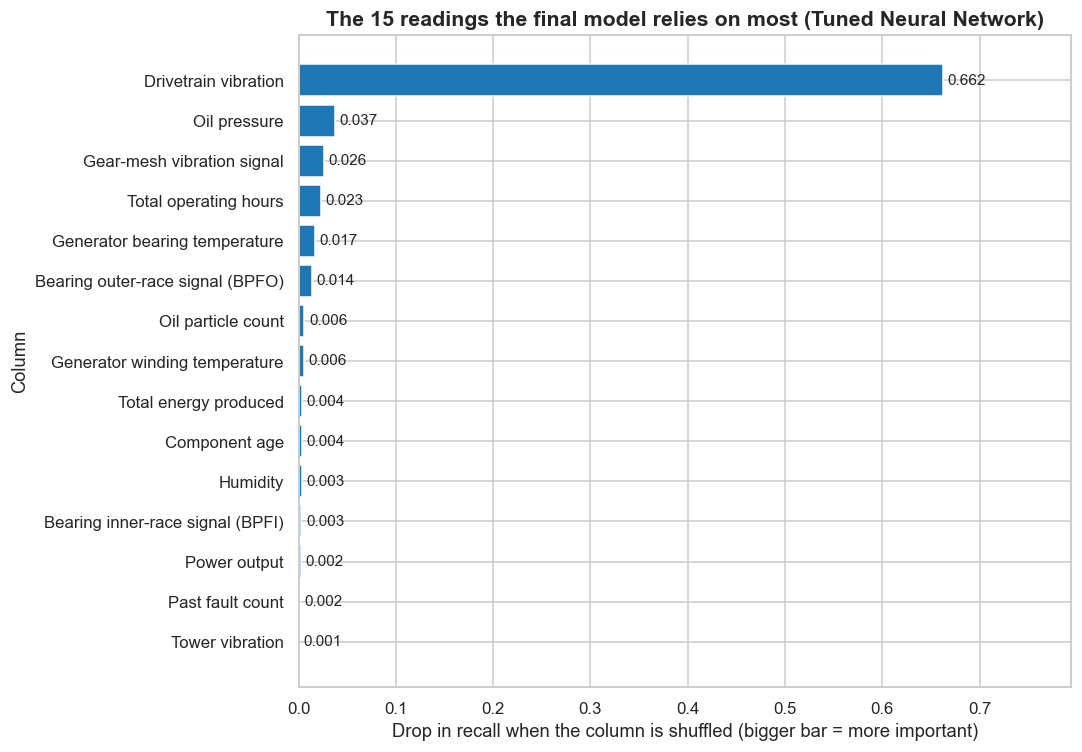

,Drop in recall when shuffled
Drivetrain vibration,0.662
Oil pressure,0.037
Gear-mesh vibration signal,0.026
Total operating hours,0.023
Generator bearing temperature,0.017
Bearing outer-race signal (BPFO),0.014
Oil particle count,0.006
Generator winding temperature,0.006
Total energy produced,0.004
Component age,0.004


In [105]:
# Plain names for the chart
NICE = {'rated_power_kW': 'Rated power', 'wind_speed_mps': 'Wind speed', 'wind_direction_deg': 'Wind direction',
        'turbulence_intensity': 'Turbulence', 'air_density_kgm3': 'Air density', 'ambient_temp_C': 'Outside temperature',
        'humidity_pct': 'Humidity', 'power_output_kW': 'Power output', 'rotor_speed_rpm': 'Rotor speed',
        'generator_speed_rpm': 'Generator speed', 'blade_pitch_angle_deg': 'Blade pitch angle',
        'yaw_misalignment_deg': 'Yaw misalignment', 'gearbox_oil_temp_C': 'Gearbox oil temperature',
        'gearbox_bearing_temp_C': 'Gearbox bearing temperature', 'generator_bearing_temp_C': 'Generator bearing temperature',
        'generator_winding_temp_C': 'Generator winding temperature', 'main_bearing_temp_C': 'Main bearing temperature',
        'nacelle_temp_C': 'Nacelle temperature', 'drivetrain_vibration_rms_mmps': 'Drivetrain vibration',
        'tower_vibration_mmps': 'Tower vibration', 'vib_fft_bearing_bpfo': 'Bearing outer-race signal (BPFO)',
        'vib_fft_bearing_bpfi': 'Bearing inner-race signal (BPFI)', 'vib_fft_gearmesh': 'Gear-mesh vibration signal',
        'vib_fft_sideband': 'Sideband vibration signal', 'oil_particle_count': 'Oil particle count',
        'oil_pressure_bar': 'Oil pressure', 'operating_hours_total': 'Total operating hours',
        'cumulative_energy_MWh': 'Total energy produced', 'load_cycles': 'Load cycles',
        'hours_since_last_maintenance': 'Hours since last maintenance', 'prior_fault_count': 'Past fault count',
        'component_age_days': 'Component age', 'dayofweek': 'Day of the week', 'hour': 'Hour of the day'}

# For the network we measure importance on the validation data (new data, and faster to run)
fi = plot_feature_importances(best_model, best_X_valid, y_valid,
                              feature_names=[NICE.get(c, c) for c in X_train.columns],
                              title='The 15 readings the final model relies on most (Tuned Neural Network)',
                              xlabel='Drop in recall when the column is shuffled (bigger bar = more important)',
                              top_n=15)

fi.sort_values(ascending=False).head(10).round(3).to_frame('Drop in recall when shuffled')

**Used for:** Seeing which readings the final model relies on to spot a fault.

**What it shows:** Drivetrain vibration is far ahead of everything else. When we shuffle it, recall drops by **0.66**, so the model would go from catching 94% of the faults to about 27%. All the other columns matter much less: oil pressure (0.037), the gear-mesh vibration signal (0.026), total operating hours (0.023), generator bearing temperature (0.017) and the bearing outer-race signal BPFO (0.014). Oil particle count is low here (0.006), even though it stood out in the charts. The likely reason is that it rises together with vibration (correlation 0.67), so the model already gets that information from the vibration sensor. Weather, time of day and power output hardly matter.

**Hence:** The model works the way an engineer would expect: shaking is the main warning sign of a bearing or gear problem. Because the model leans so heavily on one sensor, the vibration sensors on every turbine must be reliable and well looked after. If a vibration sensor fails, the model loses most of its ability to catch faults.

# **Actionable Insights and Recommendations**

This section pulls together what we learned from the charts and from the models, and turns it into advice for Aeolus Renewables.

## Business Insights

**What the data told us**

- Drivetrain faults are rare: only **3%** of the 131,760 readings are faults. They are not spread evenly. T001 (6.4%), T007 (5.6%) and T008 (5.4%) fault far more often than T014, T009 and T010 (about 1% each).
- Faults became more common over the two months: 1.6% of readings in the oldest part of the data, 5.3% in the middle and 7.3% in the newest part.
- **Vibration is the clearest warning sign.** During a fault the drivetrain shakes about twice as hard (median 3.63 mm/s against 1.68 mm/s), and 85% of fault readings are above the normal range.
- **Metal flakes in the oil are the second sign.** Fault readings have about 2.6 times more particles (165 against 64). 75% of fault readings have both high vibration (above 2.5 mm/s) and many particles (above 100), against only 4% of normal readings.
- **Low oil pressure marks a group of faults.** 20% of fault readings have oil pressure below 5 bar, against 0.6% of normal readings.
- **Temperature and power output hide faults.** Faulty gearbox bearings run about 11 °C hotter, but many healthy turbines run just as hot under heavy load. Faulty turbines also keep producing power. This explains why fixed temperature alarms only go off when the fault is almost final.

**What the models told us**

- Accuracy is the wrong score here. Every model scored 0.95 to 0.97 on accuracy, even the Random Forest that caught only 25 of 1,039 faults. We judged the models on **recall**, the share of real faults caught.
- The untuned models memorised the training data. Tuning fixed most of this: the recall drop between training and validation fell from 0.39 to 0.06 for the Neural Network and from 0.51 to 0.18 for XGBoost.
- The final model, the **Tuned Neural Network**, caught **1,101 of the 1,440 faults** in the test data (recall 0.76), data it had never seen. It raised 854 false alarms (precision 0.56), so about 1.3 real faults are flagged for every false alarm.
- Recall fell from 0.94 on the validation data to 0.76 on the test data. The newest period has the most faults, and some of them look different from the faults in the training period. The model needs fresh data to stay sharp.
- The model relies mostly on **drivetrain vibration**, then oil pressure, the gear-mesh vibration signal and total operating hours.

## Recommendations

1. **Use the model as an early-warning list in the operations centre.** Run it on every new 10-minute reading and show analysts a short list of turbines flagged as "fault". They can then focus on a handful of machines instead of scanning every channel on every turbine. Start with a pilot on these 15 turbines before rolling it out to the fleet of 1,150.
2. **Turn each alert into a planned inspection, not an emergency.** When a turbine is flagged, check its vibration spectrum and take an oil sample. If the fault is confirmed, book the crane and order the parts early. A planned repair avoids the 7 to 21 days of unplanned downtime and the premium cost of emergency work, and stops a worn bearing from destroying the gearbox.
3. **Group the alerts by turbine and by day.** A fault lasts many 10-minute readings in a row, so one problem can create many flagged readings. Counting one alert per turbine per day keeps the workload for the 140 technicians manageable and makes the false alarms easier to handle.
4. **Inspect T001, T007 and T008 first.** They have the highest fault rates in the data (5.4% to 6.4% of their readings).
5. **Look after the vibration sensors.** The model depends mostly on drivetrain vibration. Check and calibrate these sensors regularly, and set up an alert when one stops sending data. Keep the oil particle counters and oil pressure sensors in good shape too, and fix the small gaps we found (about 0.5% of readings were missing in three columns).
6. **Retrain the model regularly.** Recall dropped from 0.94 to 0.76 between the validation and test periods, so fault patterns change over time. Retrain the model every month with the newest readings, and record whether each alert turned out to be a real fault. That record also shows how much downtime and money the model saves.
7. **Collect more history before the full rollout.** This study covers only two months and 15 turbines. Before using the model on all 1,150 turbines, test it on a longer period and on more turbine models, so the results hold up across the whole fleet.